REVISED ONE-CELL MARTIAN IMAGE CLASSIFICATION PIPELINE
TensorFlow: 2.19.0
GPU(s): 0
Dataset: E:\Dr. Atef Ismail\DAFI-DTI_30-1-2025\Proposal\Proposal 3 new\Dataset\archive (5)\Mars Surface and Curiosity Image
Output : E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports

Loaded images:
  Train: 3,410
  Val  : 1,155
  Test : 1,226
  Missing paths removed: train=0, val=0, test=0
  Model classes: 18 ['0', '1', '3', '4', '6', '7', '8', '9', '10', '12', '14', '15', '16', '17', '18', '19', '21', '24']


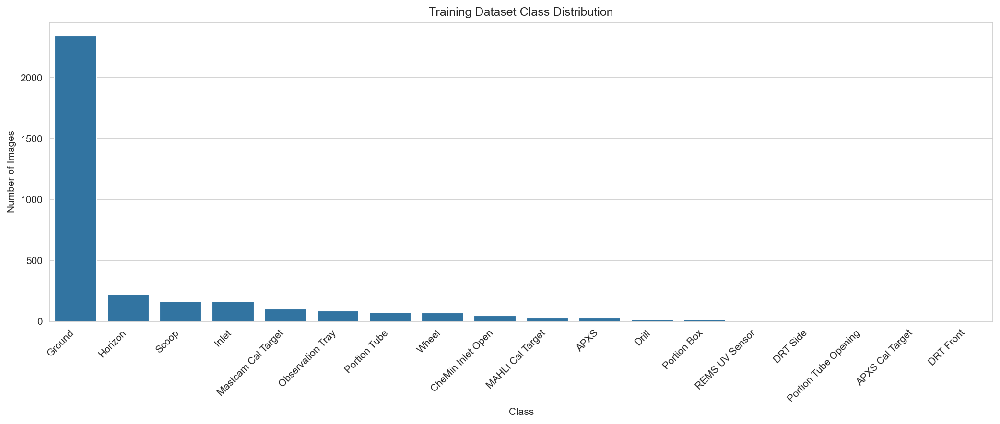

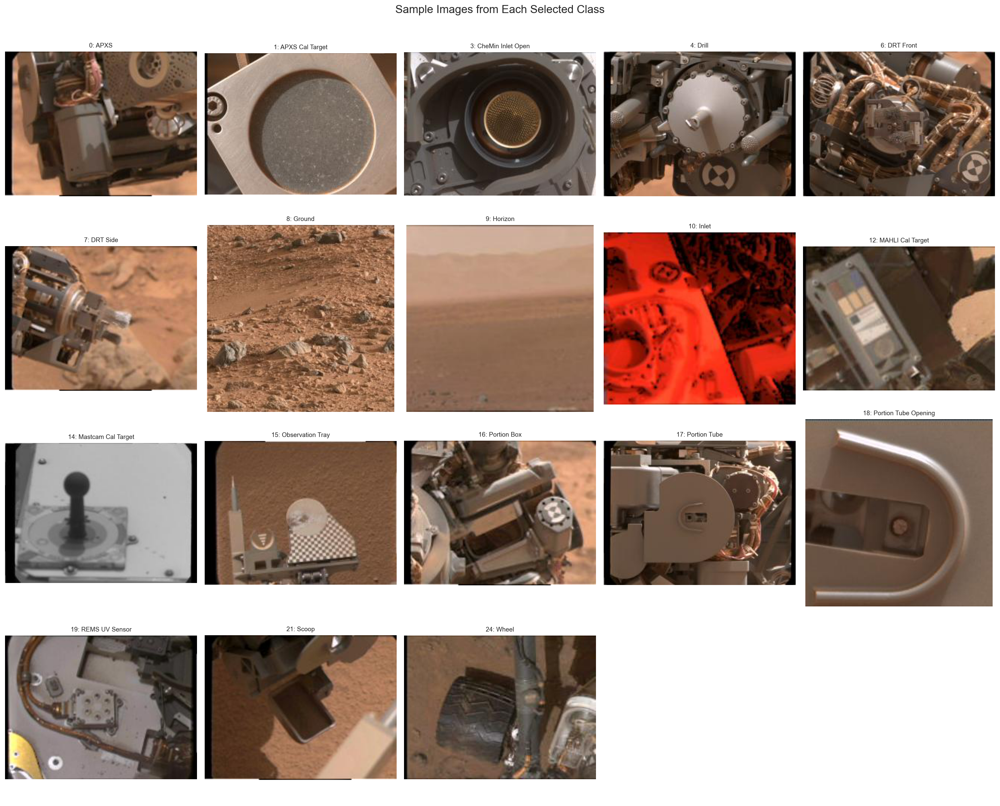

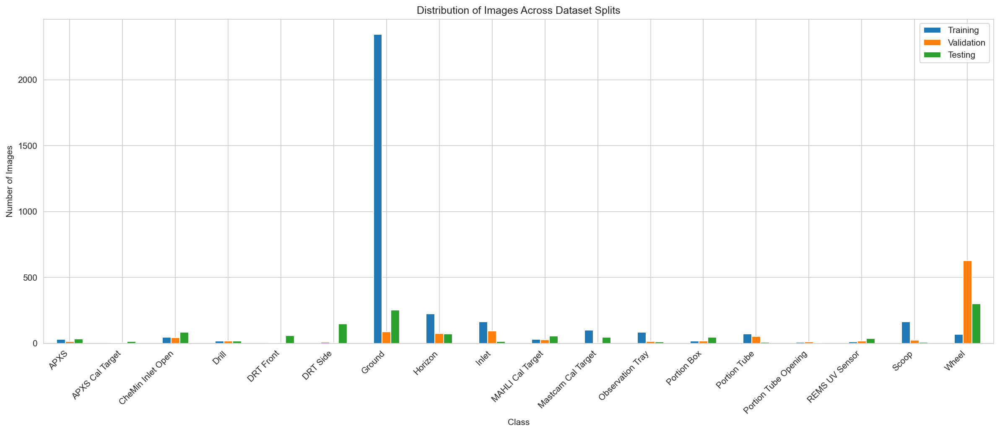

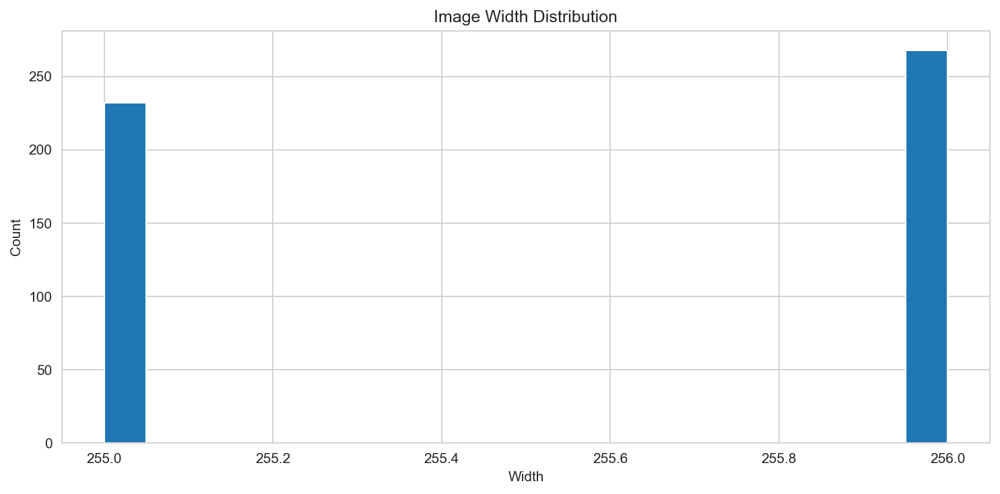

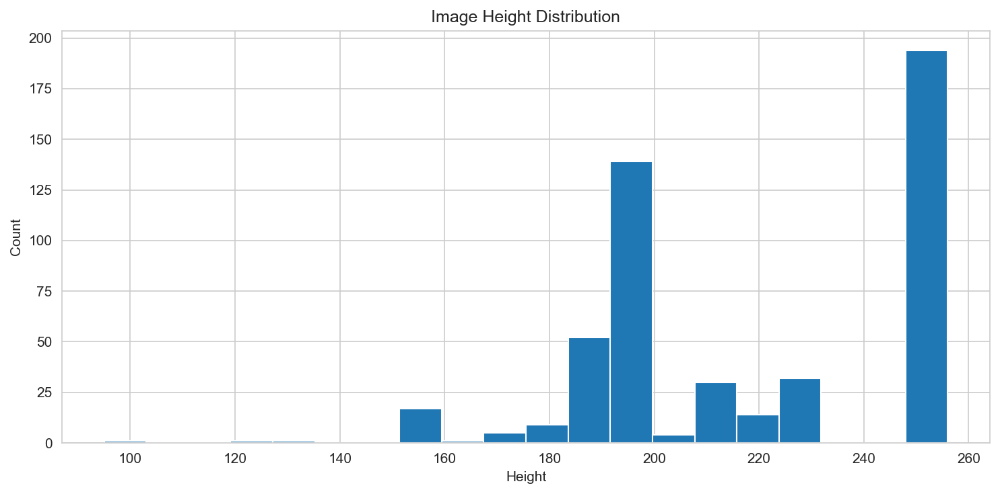

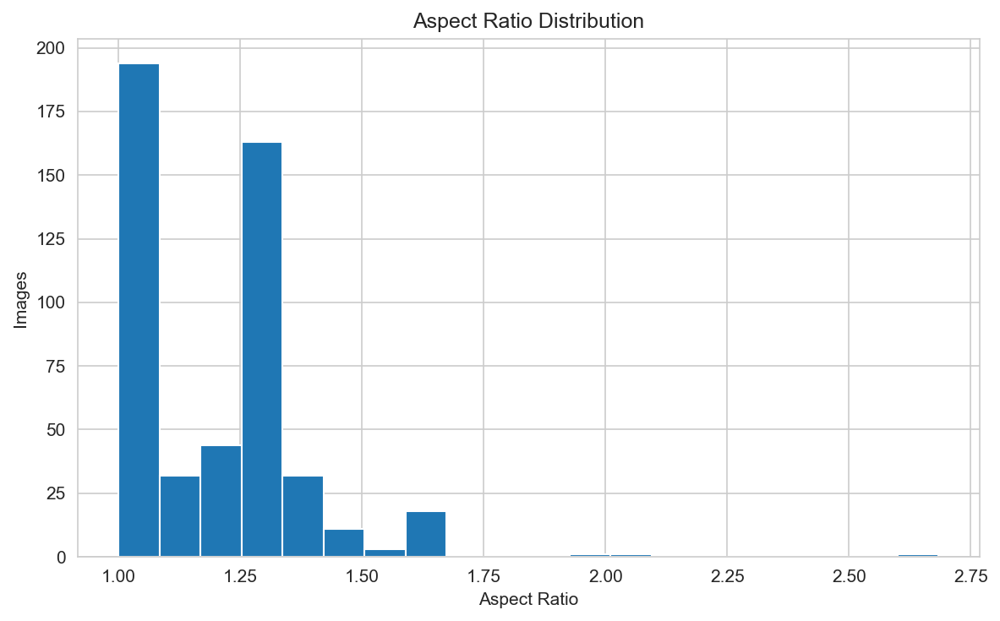

,Metric,Value
0,Minimum Width,255.000000
1,Maximum Width,256.000000
2,Average Width,255.536000
3,Minimum Height,95.000000
4,Maximum Height,256.000000
5,Average Height,218.420000
6,Average Aspect Ratio,1.199214


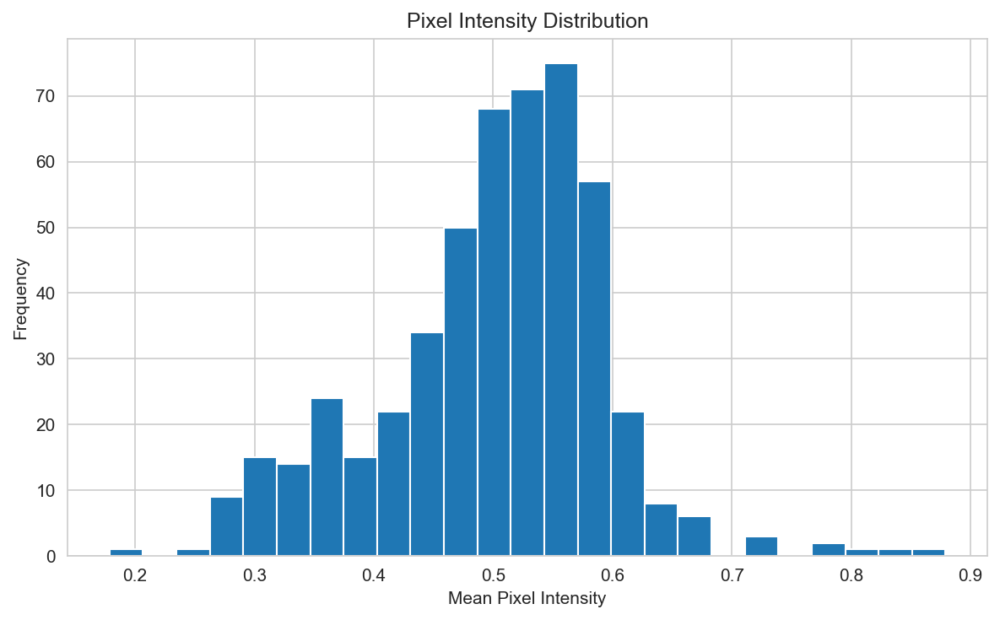

Average RGB: [0.63190782 0.4820896  0.38733955]


,Original Label,Class Name,Description
0,0,APXS,Alpha Particle X-ray Spectrometer mounted on t...
1,1,APXS Cal Target,Calibration target used for APXS instrument ca...
2,3,CheMin Inlet Open,Open inlet of the Chemistry and Mineralogy ins...
3,4,Drill,Rotary drill used for collecting rock samples.
4,6,DRT Front,Front view of the Dust Removal Tool.
5,7,DRT Side,Side view of the Dust Removal Tool.
6,8,Ground,"Martian soil, rocks, and surface textures."
7,9,Horizon,Distant Martian landscape and skyline.
8,10,Inlet,Scientific sample inlet on the rover.
9,12,MAHLI Cal Target,Calibration target for the MAHLI camera.


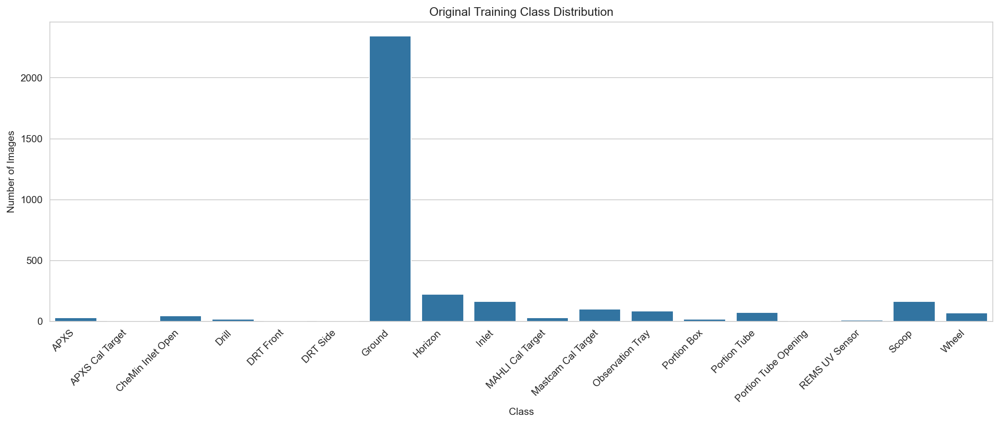

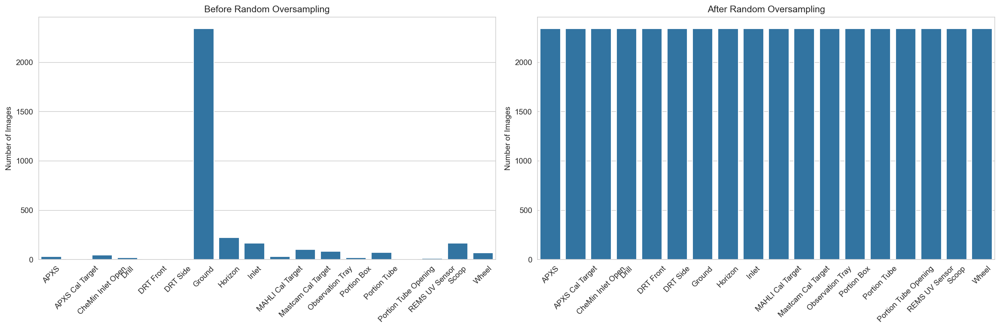

,LABELS,Class_Name,Original_Training_Count,Class_Weight
0,0,APXS,30,6.314815
1,1,APXS Cal Target,6,31.574074
2,3,CheMin Inlet Open,47,4.030733
3,4,Drill,19,9.970760
4,6,DRT Front,4,47.361111
5,7,DRT Side,8,23.680556
6,8,Ground,2343,0.080856
7,9,Horizon,224,0.845734
8,10,Inlet,165,1.148148
9,12,MAHLI Cal Target,32,5.920139



MAIN MODEL: OVERSAMPLING + ORIGINAL-TRAINING CLASS WEIGHTS + FOCAL LOSS

Found 42174 validated image filenames belonging to 18 classes.
Found 1155 validated image filenames belonging to 18 classes.
Epoch 1/30
1318/1318 ━━━━━━━━━━━━━━━━━━━━ 3912s 3s/step - accuracy: 0.8215 - loss: 0.3664 - top3_accuracy: 0.9143 - val_accuracy: 0.8684 - val_loss: 0.1782 - val_top3_accuracy: 0.9446 - learning_rate: 5.0000e-05
Epoch 2/30
1318/1318 ━━━━━━━━━━━━━━━━━━━━ 4092s 3s/step - accuracy: 0.9402 - loss: 0.1263 - top3_accuracy: 0.9859 - val_accuracy: 0.8658 - val_loss: 0.1506 - val_top3_accuracy: 0.9758 - learning_rate: 5.0000e-05
Epoch 3/30
1318/1318 ━━━━━━━━━━━━━━━━━━━━ 3398s 3s/step - accuracy: 0.9553 - loss: 0.1099 - top3_accuracy: 0.9914 - val_accuracy: 0.9074 - val_loss: 0.1330 - val_top3_accuracy: 0.9810 - learning_rate: 5.0000e-05
Epoch 4/30
 438/1318 ━━━━━━━━━━━━━━━━━━━━ 39:25 3s/step - accuracy: 0.9623 - loss: 0.0997 - top3_accuracy: 0.9953

In [ ]:
# The complete revised one-cell implementation is included below.
# It reproduces the old figures and adds reviewer-requested robustness,
# ablation, repeated-seed, validation-vs-chronological-test, boundary
# sensitivity, minority-support, and Grad-CAM analyses.


# ============================================================
# ONE-CELL REPRODUCIBLE REVISION PIPELINE
# "An Explainable Transfer Learning Approach for Balanced
# Classification of Martian Surface Imagery"
#
# This single cell:
# 1) reproduces the old figures;
# 2) fixes the focal-loss/class-weight/oversampling logic;
# 3) reports validation-vs-chronological-test class shift;
# 4) runs repeated-seed evaluation;
# 5) runs an explicit 5-condition ablation;
# 6) performs chronological-boundary sensitivity when temporal
#    metadata are available;
# 7) performs minority-class/oversampling diagnostics;
# 8) produces correct/misclassified Grad-CAM examples and
#    an earlier-vs-final convolutional-layer comparison.
#
# IMPORTANT:
# - No result is fabricated. If a requested analysis cannot be
#   derived from the CSV metadata, the pipeline writes an
#   "UNAVAILABLE" report explaining why.
# - The main model uses the implementation actually present in
#   the supplied notebook: VGG16 + focal loss + oversampling +
#   class weights + 30/20 epoch two-stage fine tuning.
# - The augmentation values are the code-repository values:
#   rotation=30°, width/height shift=20%, shear=15%, zoom=25%.
# ============================================================

import os, sys, json, math, random, warnings, logging, shutil, time, gc
from pathlib import Path
from datetime import datetime
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout, BatchNormalization, Activation
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger
from tensorflow.keras.utils import plot_model, to_categorical

from sklearn.utils import resample
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, cohen_kappa_score, matthews_corrcoef,
    precision_recall_fscore_support, roc_curve, auc,
    precision_recall_curve, average_precision_score
)

# ------------------------------------------------------------
# 0. CONFIGURATION
# ------------------------------------------------------------
SEEDS = [42, 43, 44, 45, 46]
MAIN_SEED = 42

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

# Main manuscript experiment = old implementation.
MAIN_STAGE1_EPOCHS = 30
MAIN_FINETUNE_EPOCHS = 20
INITIAL_LR = 5e-5
FINE_TUNE_LR = 1e-5
DROPOUT = 0.5
FOCAL_ALPHA = 0.25
FOCAL_GAMMA = 2.0

# Reviewer robustness experiments.
RUN_REPEATED_MAIN = True
RUN_ABLATION = True
RUN_BOUNDARY_SENSITIVITY = True
RUN_GRADCAM = True

# These can be increased to the full main training schedule if desired.
# Shorter ablation schedules preserve the controlled comparison while
# keeping the reviewer experiment computationally practical.
ABLATION_STAGE1_EPOCHS = 12
ABLATION_FINETUNE_EPOCHS = 8
ABLATION_SEEDS = SEEDS

# Chronological boundary sensitivity: relative movement around the
# original Train/Validation/Test boundaries. Only used if a temporal
# column can be identified in the supplied CSV files.
BOUNDARY_FRACTIONS = [-0.10, -0.05, 0.00, 0.05, 0.10]
BOUNDARY_RETRAIN = False  # Set True only if temporal metadata exist and compute budget allows.

# Maximum images used for expensive image-statistics plots.
MAX_IMAGE_STATS = 500

# Dataset paths from the supplied manuscript implementation.
BASE_DIR_CANDIDATES = [
    r"E:\Dr. Atef Ismail\DAFI-DTI_30-1-2025\Proposal\Proposal 3 new\Dataset\archive (5)\Mars Surface and Curiosity Image",
]
OUTPUT_DIR_CANDIDATES = [
    r"E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports",
    str(Path.cwd() / "Mars_VGG16_Revision"),
]

# ------------------------------------------------------------
# 1. PATH DISCOVERY
# ------------------------------------------------------------
BASE_DIR = next((p for p in BASE_DIR_CANDIDATES if os.path.isdir(p)), BASE_DIR_CANDIDATES[0])
if not os.path.isdir(BASE_DIR):
    raise FileNotFoundError(
        "Dataset directory was not found. Update BASE_DIR_CANDIDATES at the top of this cell "
        "to the directory containing Train_CSV.csv, Validation_CSV.csv and Test_CSV.csv."
    )

OUTPUT_DIR = next((p for p in OUTPUT_DIR_CANDIDATES if os.path.isdir(p)), OUTPUT_DIR_CANDIDATES[-1])
FIG_DIR = os.path.join(OUTPUT_DIR, "Figures")
TABLE_DIR = os.path.join(OUTPUT_DIR, "Tables")
REPORT_DIR = os.path.join(OUTPUT_DIR, "Reports")
MODEL_DIR = os.path.join(OUTPUT_DIR, "Models")
GRADCAM_DIR = os.path.join(OUTPUT_DIR, "GradCAM")
LOG_DIR = os.path.join(OUTPUT_DIR, "Logs")
for p in [OUTPUT_DIR, FIG_DIR, TABLE_DIR, REPORT_DIR, MODEL_DIR, GRADCAM_DIR, LOG_DIR]:
    os.makedirs(p, exist_ok=True)

TRAIN_CSV = os.path.join(BASE_DIR, "Train_CSV.csv")
VAL_CSV = os.path.join(BASE_DIR, "Validation_CSV.csv")
TEST_CSV = os.path.join(BASE_DIR, "Test_CSV.csv")

for p in [TRAIN_CSV, VAL_CSV, TEST_CSV]:
    if not os.path.isfile(p):
        raise FileNotFoundError(f"Required CSV not found: {p}")

# ------------------------------------------------------------
# 2. REPRODUCIBILITY
# ------------------------------------------------------------
def set_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seed(MAIN_SEED)

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception:
        pass

print("=" * 90)
print("REVISED ONE-CELL MARTIAN IMAGE CLASSIFICATION PIPELINE")
print("=" * 90)
print("TensorFlow:", tf.__version__)
print("GPU(s):", len(gpus))
print("Dataset:", BASE_DIR)
print("Output :", OUTPUT_DIR)

# ------------------------------------------------------------
# 3. CLASS DEFINITIONS
# ------------------------------------------------------------
# The supplied implementation uses these 18 classes. The original
# dataset label space may contain additional labels; they are reported
# explicitly rather than silently relabeled.
CLASS_MAPPING = {
    "0": "APXS",
    "1": "APXS Cal Target",
    "3": "CheMin Inlet Open",
    "4": "Drill",
    "6": "DRT Front",
    "7": "DRT Side",
    "8": "Ground",
    "9": "Horizon",
    "10": "Inlet",
    "12": "MAHLI Cal Target",
    "14": "Mastcam Cal Target",
    "15": "Observation Tray",
    "16": "Portion Box",
    "17": "Portion Tube",
    "18": "Portion Tube Opening",
    "19": "REMS UV Sensor",
    "21": "Scoop",
    "24": "Wheel",
}
ALL_DATASET_LABELS = [str(i) for i in range(25)]
SELECTED_LABELS = list(CLASS_MAPPING.keys())
CLASS_NAMES = list(CLASS_MAPPING.values())
LABEL_TO_INDEX = {lab: i for i, lab in enumerate(SELECTED_LABELS)}
INDEX_TO_LABEL = {i: lab for lab, i in LABEL_TO_INDEX.items()}

CLASS_DESCRIPTION = {
    "APXS":"Alpha Particle X-ray Spectrometer mounted on the rover.",
    "APXS Cal Target":"Calibration target used for APXS instrument calibration.",
    "CheMin Inlet Open":"Open inlet of the Chemistry and Mineralogy instrument.",
    "Drill":"Rotary drill used for collecting rock samples.",
    "DRT Front":"Front view of the Dust Removal Tool.",
    "DRT Side":"Side view of the Dust Removal Tool.",
    "Ground":"Martian soil, rocks, and surface textures.",
    "Horizon":"Distant Martian landscape and skyline.",
    "Inlet":"Scientific sample inlet on the rover.",
    "MAHLI Cal Target":"Calibration target for the MAHLI camera.",
    "Mastcam Cal Target":"Calibration target for the Mastcam imaging system.",
    "Observation Tray":"Tray used for scientific observations.",
    "Portion Box":"Container for processed samples.",
    "Portion Tube":"Tube used during sample handling.",
    "Portion Tube Opening":"Opening of the sample transfer tube.",
    "REMS UV Sensor":"Ultraviolet sensor of the Rover Environmental Monitoring Station.",
    "Scoop":"Sampling scoop mounted on the robotic arm.",
    "Wheel":"Curiosity rover wheel.",
}

# ------------------------------------------------------------
# 4. LOAD DATA
# ------------------------------------------------------------
def load_split(csv_path):
    df = pd.read_csv(csv_path)
    if "LABELS" not in df.columns or "JPG" not in df.columns:
        raise ValueError(f"{csv_path} must contain LABELS and JPG columns.")
    df = df.copy()
    df["LABELS"] = df["LABELS"].astype(str)
    df["full_path"] = df["JPG"].astype(str).apply(lambda x: os.path.join(BASE_DIR, x))
    df["CLASS_NAME"] = df["LABELS"].map(CLASS_MAPPING)
    df["exists"] = df["full_path"].apply(os.path.exists)
    missing = int((~df["exists"]).sum())
    df = df[df["exists"]].drop(columns=["exists"]).reset_index(drop=True)
    return df, missing

train_df, missing_train = load_split(TRAIN_CSV)
val_df, missing_val = load_split(VAL_CSV)
test_df, missing_test = load_split(TEST_CSV)

# Keep the benchmark classes used by the supplied implementation.
train_df = train_df[train_df["LABELS"].isin(SELECTED_LABELS)].reset_index(drop=True)
val_df = val_df[val_df["LABELS"].isin(SELECTED_LABELS)].reset_index(drop=True)
test_df = test_df[test_df["LABELS"].isin(SELECTED_LABELS)].reset_index(drop=True)

# Classes absent from training are not valid model outputs.
TRAIN_LABELS = [x for x in SELECTED_LABELS if x in set(train_df["LABELS"])]
val_df = val_df[val_df["LABELS"].isin(TRAIN_LABELS)].reset_index(drop=True)
test_df = test_df[test_df["LABELS"].isin(TRAIN_LABELS)].reset_index(drop=True)

print("\nLoaded images:")
print(f"  Train: {len(train_df):,}")
print(f"  Val  : {len(val_df):,}")
print(f"  Test : {len(test_df):,}")
print(f"  Missing paths removed: train={missing_train}, val={missing_val}, test={missing_test}")
print("  Model classes:", len(TRAIN_LABELS), TRAIN_LABELS)

# Explicit excluded-label report.
present_all = set(pd.concat([
    pd.read_csv(TRAIN_CSV)["LABELS"].astype(str),
    pd.read_csv(VAL_CSV)["LABELS"].astype(str),
    pd.read_csv(TEST_CSV)["LABELS"].astype(str)
]).unique())
excluded_labels = sorted(present_all - set(TRAIN_LABELS), key=lambda x: int(x) if x.isdigit() else x)

exclusion_report = pd.DataFrame({
    "Label": excluded_labels,
    "Class_Name": [CLASS_MAPPING.get(x, f"Dataset label {x}") for x in excluded_labels],
    "Reason_supported_by_code": [
        "Not part of the 18-class benchmark output space used by the supplied implementation."
        for _ in excluded_labels
    ]
})
exclusion_report.to_csv(os.path.join(REPORT_DIR, "Excluded_Classes_Report.csv"), index=False)

# ------------------------------------------------------------
# 5. CONFIGURATION / DATA DISTRIBUTION TABLES
# ------------------------------------------------------------
config = pd.DataFrame([
    ["Seed list", ",".join(map(str, SEEDS))],
    ["Image size", str(IMAGE_SIZE)],
    ["Batch size", BATCH_SIZE],
    ["Main stage 1 epochs", MAIN_STAGE1_EPOCHS],
    ["Main fine-tuning epochs", MAIN_FINETUNE_EPOCHS],
    ["Initial learning rate", INITIAL_LR],
    ["Fine-tuning learning rate", FINE_TUNE_LR],
    ["Dropout", DROPOUT],
    ["Focal alpha", FOCAL_ALPHA],
    ["Focal gamma", FOCAL_GAMMA],
    ["Augmentation rotation", "30 degrees"],
    ["Width/height shift", "20%"],
    ["Shear", "15%"],
    ["Zoom", "25%"],
    ["Horizontal flip", True],
    ["Brightness", "(0.9, 1.1)"],
    ["Loss in final/full model", "Categorical focal loss"],
    ["Balancing in final/full model", "Random oversampling + original-training class weights"],
    ["Backbone", "ImageNet-pretrained VGG16"],
    ["Fine-tuned layers", "Last 8 convolutional layers"],
])
config.to_csv(os.path.join(REPORT_DIR, "Experiment_Config_Revised.csv"), index=False)

dist = pd.DataFrame(index=TRAIN_LABELS)
dist["Class_Name"] = [CLASS_MAPPING[x] for x in TRAIN_LABELS]
dist["Training"] = train_df["LABELS"].value_counts().reindex(TRAIN_LABELS, fill_value=0).astype(int)
dist["Validation"] = val_df["LABELS"].value_counts().reindex(TRAIN_LABELS, fill_value=0).astype(int)
dist["Chronological_Test"] = test_df["LABELS"].value_counts().reindex(TRAIN_LABELS, fill_value=0).astype(int)
dist["Training_%"] = 100 * dist["Training"] / max(1, dist["Training"].sum())
dist["Validation_%"] = 100 * dist["Validation"] / max(1, dist["Validation"].sum())
dist["Test_%"] = 100 * dist["Chronological_Test"] / max(1, dist["Chronological_Test"].sum())
dist["Test_n"] = dist["Chronological_Test"]
dist.to_csv(os.path.join(TABLE_DIR, "Class_Distribution_Train_Val_ChronologicalTest.csv"))

# ------------------------------------------------------------
# 6. DATASET / EDA FIGURES FROM THE OLD VERSION
# ------------------------------------------------------------
sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300})

# Figure 2: training class distribution
plt.figure(figsize=(14, 6))
tmp = dist.sort_values("Training", ascending=False)
sns.barplot(x=tmp["Class_Name"], y=tmp["Training"].values)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Class"); plt.ylabel("Number of Images")
plt.title("Training Dataset Class Distribution")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Figure2_ClassDistribution.png"), bbox_inches="tight")
plt.show()

# Figure 3: sample images
n_cols = 5
n_rows = math.ceil(len(TRAIN_LABELS) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4*n_rows))
axes = np.asarray(axes).reshape(-1)
for i, lab in enumerate(TRAIN_LABELS):
    row = train_df[train_df["LABELS"] == lab].iloc[0]
    try:
        axes[i].imshow(Image.open(row["full_path"]).convert("RGB"))
    except Exception:
        axes[i].text(0.5, 0.5, "Image unavailable", ha="center")
    axes[i].set_title(f"{lab}: {CLASS_MAPPING[lab]}", fontsize=9)
    axes[i].axis("off")
for ax in axes[len(TRAIN_LABELS):]:
    ax.axis("off")
plt.suptitle("Sample Images from Each Selected Class", y=1.0, fontsize=16)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Figure3_SampleImages.png"), bbox_inches="tight")
plt.show()

# Split distribution: old Figure 3/DatasetDistribution
plot_dist = dist.set_index("Class_Name")[["Training","Validation","Chronological_Test"]]
plot_dist.columns = ["Training","Validation","Testing"]
plot_dist.plot(kind="bar", figsize=(16,7))
plt.ylabel("Number of Images"); plt.xlabel("Class")
plt.title("Distribution of Images Across Dataset Splits")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Figure3_DatasetDistribution.png"), bbox_inches="tight")
plt.show()

# Resolution and aspect ratio
widths, heights, aspect_ratios = [], [], []
for path in train_df["full_path"].sample(min(MAX_IMAGE_STATS, len(train_df)), random_state=MAIN_SEED):
    try:
        with Image.open(path) as im:
            w, h = im.size
        widths.append(w); heights.append(h); aspect_ratios.append(w/h)
    except Exception:
        pass

if widths:
    plt.figure(figsize=(10,5)); plt.hist(widths, bins=20)
    plt.title("Image Width Distribution"); plt.xlabel("Width"); plt.ylabel("Count")
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "ImageWidthDistribution.png"), bbox_inches="tight"); plt.show()

    plt.figure(figsize=(10,5)); plt.hist(heights, bins=20)
    plt.title("Image Height Distribution"); plt.xlabel("Height"); plt.ylabel("Count")
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "ImageHeightDistribution.png"), bbox_inches="tight"); plt.show()

    plt.figure(figsize=(8,5)); plt.hist(aspect_ratios, bins=20)
    plt.xlabel("Aspect Ratio"); plt.ylabel("Images"); plt.title("Aspect Ratio Distribution")
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "AspectRatio.png"), bbox_inches="tight"); plt.show()

    resolution_table = pd.DataFrame({
        "Metric":["Minimum Width","Maximum Width","Average Width","Minimum Height","Maximum Height","Average Height","Average Aspect Ratio"],
        "Value":[min(widths),max(widths),np.mean(widths),min(heights),max(heights),np.mean(heights),np.mean(aspect_ratios)]
    })
    resolution_table.to_csv(os.path.join(TABLE_DIR, "ImageResolution.csv"), index=False)
    display(resolution_table)

# Pixel intensity
sample_paths = train_df["full_path"].sample(min(MAX_IMAGE_STATS, len(train_df)), random_state=MAIN_SEED)
pixel_means, pixel_stds, rgb_sum = [], [], np.zeros(3)
rgb_n = 0
for path in sample_paths:
    try:
        arr = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32)/255.0
        pixel_means.append(arr.mean()); pixel_stds.append(arr.std())
        rgb_sum += arr.mean(axis=(0,1)); rgb_n += 1
    except Exception:
        pass
if pixel_means:
    plt.figure(figsize=(8,5)); plt.hist(pixel_means, bins=25)
    plt.xlabel("Mean Pixel Intensity"); plt.ylabel("Frequency")
    plt.title("Pixel Intensity Distribution")
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "PixelIntensity.png"), bbox_inches="tight"); plt.show()
    print("Average RGB:", rgb_sum/max(1,rgb_n))

# Table 1: selected classes used in this study
table1 = pd.DataFrame({
    "Original Label": TRAIN_LABELS,
    "Class Name": [CLASS_MAPPING[x] for x in TRAIN_LABELS],
    "Description": [CLASS_DESCRIPTION[CLASS_MAPPING[x]] for x in TRAIN_LABELS]
})
table1.to_csv(os.path.join(TABLE_DIR, "Table1_SelectedClasses.csv"), index=False)
display(table1)

# Original class distribution and oversampling
original_counts = train_df["LABELS"].value_counts().reindex(TRAIN_LABELS, fill_value=0)

# Old Figure 5: original training distribution
plt.figure(figsize=(14,6))
sns.barplot(x=[CLASS_MAPPING[x] for x in TRAIN_LABELS], y=original_counts.values)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of Images")
plt.xlabel("Class")
plt.title("Original Training Class Distribution")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Figure5_OriginalDistribution.png"), bbox_inches="tight")
plt.show()
majority_count = int(original_counts.max())
balanced_frames = []
for lab in TRAIN_LABELS:
    subset = train_df[train_df["LABELS"] == lab]
    balanced_frames.append(resample(subset, replace=True, n_samples=majority_count, random_state=MAIN_SEED))
balanced_train_df = pd.concat(balanced_frames, ignore_index=True).sample(frac=1, random_state=MAIN_SEED).reset_index(drop=True)
balanced_counts = balanced_train_df["LABELS"].value_counts().reindex(TRAIN_LABELS, fill_value=0)

fig, ax = plt.subplots(1,2, figsize=(18,6))
sns.barplot(x=[CLASS_MAPPING[x] for x in TRAIN_LABELS], y=original_counts.values, ax=ax[0])
ax[0].set_title("Before Random Oversampling"); ax[0].tick_params(axis="x", rotation=45)
sns.barplot(x=[CLASS_MAPPING[x] for x in TRAIN_LABELS], y=balanced_counts.values, ax=ax[1])
ax[1].set_title("After Random Oversampling"); ax[1].tick_params(axis="x", rotation=45)
for a in ax: a.set_ylabel("Number of Images")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Figure6_Oversampling.png"), bbox_inches="tight"); plt.show()
balanced_train_df.to_csv(os.path.join(TABLE_DIR, "BalancedTraining.csv"), index=False)

# ------------------------------------------------------------
# 7. GENERATORS AND CORRECT CLASS-WEIGHT DEFINITIONS
# ------------------------------------------------------------
# Critical correction:
# The old code computed class weights from the already-balanced dataset,
# making all weights approximately 1. Here class weights are computed from
# the ORIGINAL training distribution and retained for the full model.
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.array(TRAIN_LABELS),
    y=train_df["LABELS"].values
)
ORIGINAL_CLASS_WEIGHTS = {i: float(w) for i, w in enumerate(class_weights_array)}
weight_table = pd.DataFrame({
    "LABELS": TRAIN_LABELS,
    "Class_Name": [CLASS_MAPPING[x] for x in TRAIN_LABELS],
    "Original_Training_Count": original_counts.values,
    "Class_Weight": class_weights_array
})
weight_table.to_csv(os.path.join(TABLE_DIR, "ClassWeights_From_OriginalTraining.csv"), index=False)
display(weight_table)

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.20,
    height_shift_range=0.20,
    shear_range=0.15,
    zoom_range=0.25,
    horizontal_flip=True,
    brightness_range=(0.9, 1.1),
    fill_mode="nearest"
)
eval_datagen = ImageDataGenerator(rescale=1./255)

def make_generator(df, train=False, shuffle=False, seed=MAIN_SEED):
    datagen = train_datagen if train else eval_datagen
    return datagen.flow_from_dataframe(
        dataframe=df,
        x_col="full_path",
        y_col="LABELS",
        classes=TRAIN_LABELS,
        target_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=shuffle,
        seed=seed
    )

# ------------------------------------------------------------
# 8. MODEL / LOSS FUNCTIONS
# ------------------------------------------------------------
def categorical_focal_loss(alpha=0.25, gamma=2.0):
    def loss(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, K.epsilon(), 1.0 - K.epsilon())
        ce = -y_true * tf.math.log(y_pred)
        weight = alpha * tf.pow(1.0 - y_pred, gamma)
        return tf.reduce_sum(weight * ce, axis=1)
    loss.__name__ = "categorical_focal_loss"
    return loss

def build_model(seed=MAIN_SEED):
    set_seed(seed)
    base = VGG16(weights="imagenet", include_top=False, input_shape=(224,224,3))
    base.trainable = False
    for layer in base.layers:
        layer.trainable = False

    inputs = Input(shape=(224,224,3))
    x = base(inputs, training=False)
    x = Flatten()(x)
    x = Dense(512, kernel_regularizer=l2(1e-4))(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Dropout(DROPOUT)(x)
    outputs = Dense(len(TRAIN_LABELS), activation="softmax", dtype="float32")(x)
    model = Model(inputs, outputs)
    return model, base

def compile_model(model, lr, use_focal):
    loss = categorical_focal_loss(FOCAL_ALPHA, FOCAL_GAMMA) if use_focal else "categorical_crossentropy"
    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss=loss,
        metrics=["accuracy", tf.keras.metrics.TopKCategoricalAccuracy(k=3, name="top3_accuracy")]
    )

def callbacks_for(run_name, monitor="val_loss"):
    ckpt = os.path.join(MODEL_DIR, f"{run_name}_best.keras")
    csv = os.path.join(LOG_DIR, f"{run_name}_history.csv")
    return [
        ModelCheckpoint(ckpt, monitor="val_accuracy", mode="max", save_best_only=True, verbose=0),
        EarlyStopping(monitor=monitor, patience=5, restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor=monitor, factor=0.5, patience=2, min_lr=1e-7, verbose=0),
        CSVLogger(csv, append=False)
    ]

def merge_histories(h1, h2):
    keys = sorted(set(h1.history).union(h2.history))
    out = {}
    for k in keys:
        out[k] = h1.history.get(k, []) + h2.history.get(k, [])
    return out

def train_two_stage(train_source, use_class_weights, use_focal, seed,
                     stage1_epochs, finetune_epochs, run_name):
    tf.keras.backend.clear_session()
    gc.collect()
    set_seed(seed)

    model, base = build_model(seed)
    tr = make_generator(train_source, train=True, shuffle=True, seed=seed)
    va = make_generator(val_df, train=False, shuffle=False)

    cw = ORIGINAL_CLASS_WEIGHTS if use_class_weights else None

    compile_model(model, INITIAL_LR, use_focal)
    cb1 = callbacks_for(run_name + "_stage1")
    h1 = model.fit(
        tr, validation_data=va, epochs=stage1_epochs,
        class_weight=cw, callbacks=cb1, verbose=1
    )

    base.trainable = True
    for layer in base.layers[:-8]:
        layer.trainable = False
    for layer in base.layers[-8:]:
        layer.trainable = True

    compile_model(model, FINE_TUNE_LR, use_focal)
    cb2 = callbacks_for(run_name + "_stage2")
    h2 = model.fit(
        tr, validation_data=va,
        epochs=stage1_epochs + finetune_epochs,
        initial_epoch=stage1_epochs,
        class_weight=cw, callbacks=cb2, verbose=1
    )

    history = merge_histories(h1, h2)
    best_epoch = int(np.argmax(history["val_accuracy"]))
    best_path = os.path.join(MODEL_DIR, f"{run_name}_stage2_best.keras")
    model.save(best_path)
    return model, history, best_epoch

# ------------------------------------------------------------
# 9. EVALUATION HELPERS
# ------------------------------------------------------------
def evaluate_model(model, df, split_name="test", save_prefix="eval"):
    gen = make_generator(df, train=False, shuffle=False)
    gen.reset()
    probs = model.predict(gen, verbose=1)
    y_true = gen.classes.copy()
    y_pred = np.argmax(probs, axis=1)

    acc = accuracy_score(y_true, y_pred)
    bal = balanced_accuracy_score(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred)
    mcc = matthews_corrcoef(y_true, y_pred)
    top3 = np.mean(np.any(np.argsort(probs, axis=1)[:, -3:] == y_true[:, None], axis=1))

    report = classification_report(
        y_true, y_pred,
        labels=np.arange(len(TRAIN_LABELS)),
        target_names=[CLASS_MAPPING[x] for x in TRAIN_LABELS],
        output_dict=True, zero_division=0
    )
    report_df = pd.DataFrame(report).transpose()
    report_df.to_csv(os.path.join(TABLE_DIR, f"{save_prefix}_{split_name}_classification_report.csv"))

    per_class = report_df.iloc[:len(TRAIN_LABELS)][["precision","recall","f1-score","support"]].copy()
    per_class["LABELS"] = TRAIN_LABELS
    per_class["Class_Name"] = [CLASS_MAPPING[x] for x in TRAIN_LABELS]
    per_class = per_class[["LABELS","Class_Name","precision","recall","f1-score","support"]]
    per_class.to_csv(os.path.join(TABLE_DIR, f"{save_prefix}_{split_name}_per_class.csv"), index=False)

    metrics = {
        "Split": split_name,
        "Accuracy": acc,
        "Top3_Accuracy": top3,
        "Balanced_Accuracy": bal,
        "Macro_Precision": report["macro avg"]["precision"],
        "Macro_Recall": report["macro avg"]["recall"],
        "Macro_F1": report["macro avg"]["f1-score"],
        "Weighted_F1": report["weighted avg"]["f1-score"],
        "Cohen_Kappa": kappa,
        "MCC": mcc
    }
    return metrics, probs, y_true, y_pred, per_class

def plot_training(history, prefix="Main"):
    epochs = np.arange(1, len(history["accuracy"]) + 1)
    best_epoch = np.argmax(history["val_accuracy"]) + 1
    best_acc = history["val_accuracy"][best_epoch-1]

    plt.figure(figsize=(8,6))
    plt.plot(epochs, history["accuracy"], label="Training Accuracy", linewidth=2)
    plt.plot(epochs, history["val_accuracy"], label="Validation Accuracy", linewidth=2)
    plt.scatter(best_epoch, best_acc, s=100, marker="*", label=f"Best Epoch ({best_epoch})")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Training and Validation Accuracy")
    plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "Accuracy.png"), bbox_inches="tight"); plt.show()

    plt.figure(figsize=(8,6))
    plt.plot(epochs, history["loss"], label="Training Loss", linewidth=2)
    plt.plot(epochs, history["val_loss"], label="Validation Loss", linewidth=2)
    plt.scatter(best_epoch, history["val_loss"][best_epoch-1], s=100, marker="*", label=f"Best Epoch ({best_epoch})")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Training and Validation Loss")
    plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "Loss.png"), bbox_inches="tight"); plt.show()

    if "lr" in history:
        plt.figure(figsize=(8,5)); plt.plot(epochs, history["lr"])
        plt.xlabel("Epoch"); plt.ylabel("Learning Rate"); plt.title("Learning Rate Schedule")
        plt.grid(alpha=0.3); plt.tight_layout()
        plt.savefig(os.path.join(FIG_DIR, "Figure10_LearningRate.png"), bbox_inches="tight"); plt.show()

    fig, ax = plt.subplots(1,2,figsize=(14,5))
    ax[0].plot(epochs, history["accuracy"], label="Training")
    ax[0].plot(epochs, history["val_accuracy"], label="Validation")
    ax[0].scatter(best_epoch, best_acc, s=100)
    ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(epochs, history["loss"], label="Training")
    ax[1].plot(epochs, history["val_loss"], label="Validation")
    ax[1].scatter(best_epoch, history["val_loss"][best_epoch-1], s=100)
    ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Figure11_TrainingDashboard.png"), bbox_inches="tight"); plt.show()

# ------------------------------------------------------------
# 10. MAIN MODEL: ORIGINAL FULL METHOD
# ------------------------------------------------------------
print("\n" + "="*90)
print("MAIN MODEL: OVERSAMPLING + ORIGINAL-TRAINING CLASS WEIGHTS + FOCAL LOSS")
print("="*90)

main_model, main_history, main_best_epoch = train_two_stage(
    balanced_train_df,
    use_class_weights=True,
    use_focal=True,
    seed=MAIN_SEED,
    stage1_epochs=MAIN_STAGE1_EPOCHS,
    finetune_epochs=MAIN_FINETUNE_EPOCHS,
    run_name="Main_Full"
)

pd.DataFrame(main_history).to_csv(os.path.join(REPORT_DIR, "TrainingHistory.csv"), index=False)
plot_training(main_history, "Main")

# Model summary / architecture figure
with open(os.path.join(REPORT_DIR, "ModelSummary.txt"), "w", encoding="utf-8") as f:
    main_model.summary(print_fn=lambda x: f.write(x + "\n"))
try:
    plot_model(main_model, to_file=os.path.join(FIG_DIR, "VGG16_Architecture.png"),
               show_shapes=True, show_layer_names=True, dpi=200)
except Exception as e:
    print("plot_model unavailable:", e)

# Main validation and chronological test evaluation
val_metrics, val_probs, val_true, val_pred, val_per_class = evaluate_model(
    main_model, val_df, "validation", "Main"
)
test_metrics, test_probs, test_true, test_pred, test_per_class = evaluate_model(
    main_model, test_df, "chronological_test", "Main"
)

overall = pd.DataFrame([val_metrics, test_metrics])
overall.to_csv(os.path.join(TABLE_DIR, "Validation_vs_ChronologicalTest_Overall.csv"), index=False)
display(overall)

# Per-class validation-vs-test table with sample counts
comparison = val_per_class.merge(
    test_per_class,
    on=["LABELS","Class_Name"],
    how="outer",
    suffixes=("_Validation","_Test")
)
comparison.to_csv(os.path.join(TABLE_DIR, "Validation_vs_ChronologicalTest_PerClass.csv"), index=False)
display(comparison)

# Old confusion matrix
class_names = [CLASS_MAPPING[x] for x in TRAIN_LABELS]
cm = confusion_matrix(test_true, test_pred, labels=np.arange(len(TRAIN_LABELS)))
plt.figure(figsize=(14,12))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Class"); plt.ylabel("True Class")
plt.title("Chronological Test Confusion Matrix")
plt.xticks(rotation=45, ha="right"); plt.yticks(rotation=0)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Figure12_ConfusionMatrix.png"), bbox_inches="tight"); plt.show()

# Old per-class performance
x = np.arange(len(class_names)); width = .25
plt.figure(figsize=(16,7))
plt.bar(x-width, test_per_class["precision"], width, label="Precision")
plt.bar(x, test_per_class["recall"], width, label="Recall")
plt.bar(x+width, test_per_class["f1-score"], width, label="F1-score")
plt.xticks(x, class_names, rotation=45, ha="right"); plt.ylabel("Score")
plt.ylim(0,1.05); plt.legend(); plt.title("Chronological Test Per-Class Performance")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Figure14_PerClassPerformance.png"), bbox_inches="tight"); plt.show()

# Old ROC
y_true_oh = to_categorical(test_true, num_classes=len(TRAIN_LABELS))
plt.figure(figsize=(11,9))
for i, cls in enumerate(class_names):
    if len(np.unique(y_true_oh[:,i])) > 1:
        fpr, tpr, _ = roc_curve(y_true_oh[:,i], test_probs[:,i])
        plt.plot(fpr, tpr, label=f"{cls} (AUC={auc(fpr,tpr):.3f})")
plt.plot([0,1],[0,1],"--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves — Chronological Test")
plt.legend(fontsize=8, loc="lower right"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Figure15_ROC.png"), bbox_inches="tight"); plt.show()

# Old PR
plt.figure(figsize=(11,9))
for i, cls in enumerate(class_names):
    if len(np.unique(y_true_oh[:,i])) > 1:
        precision, recall, _ = precision_recall_curve(y_true_oh[:,i], test_probs[:,i])
        ap = average_precision_score(y_true_oh[:,i], test_probs[:,i])
        plt.plot(recall, precision, label=f"{cls} AP={ap:.2f}")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall Curves — Chronological Test")
plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Figure16_PRCurve.png"), bbox_inches="tight"); plt.show()

# Old prediction table + top-k
pred_table = test_df[["full_path","LABELS","CLASS_NAME"]].copy()
pred_table["Predicted_Index"] = test_pred
pred_table["Predicted_Label"] = [TRAIN_LABELS[i] for i in test_pred]
pred_table["Predicted_Class"] = [CLASS_MAPPING[TRAIN_LABELS[i]] for i in test_pred]
pred_table["Correct"] = pred_table["LABELS"].values == pred_table["Predicted_Label"].values
pred_table.to_csv(os.path.join(TABLE_DIR, "TestPredictions.csv"), index=False)

summary_metrics = pd.DataFrame([
    ["Validation Accuracy", val_metrics["Accuracy"]],
    ["Validation Top-3 Accuracy", val_metrics["Top3_Accuracy"]],
    ["Validation Balanced Accuracy", val_metrics["Balanced_Accuracy"]],
    ["Validation Macro-F1", val_metrics["Macro_F1"]],
    ["Chronological Test Accuracy", test_metrics["Accuracy"]],
    ["Chronological Test Top-3 Accuracy", test_metrics["Top3_Accuracy"]],
    ["Chronological Test Balanced Accuracy", test_metrics["Balanced_Accuracy"]],
    ["Chronological Test Macro-F1", test_metrics["Macro_F1"]],
    ["Chronological Test Kappa", test_metrics["Cohen_Kappa"]],
    ["Chronological Test MCC", test_metrics["MCC"]],
], columns=["Metric","Value"])
summary_metrics.to_csv(os.path.join(TABLE_DIR, "EvaluationSummary.csv"), index=False)
display(summary_metrics)

# ------------------------------------------------------------
# 11. REVIEWER ISSUE: VALIDATION-TEST DISTRIBUTION SHIFT
# ------------------------------------------------------------
dist_pct = dist.copy()
for col in ["Training","Validation","Chronological_Test"]:
    denom = max(1, dist_pct[col].sum())
    dist_pct[col+"_Percent"] = 100*dist_pct[col]/denom

plt.figure(figsize=(16,7))
dist_pct.set_index("Class_Name")[["Validation_Percent","Chronological_Test_Percent"]].plot(kind="bar", figsize=(16,7))
plt.ylabel("Share of split (%)"); plt.xlabel("Class")
plt.title("Validation vs Chronological-Test Class Distribution")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Figure_Validation_vs_Test_ClassDistribution.png"), bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 12. REVIEWER ISSUE: REPEATED RUNS / MEAN ± SD
# ------------------------------------------------------------
def repeated_main_runs():
    rows = []
    for seed in SEEDS:
        print("\n" + "-"*80)
        print("Repeated full-model run, seed =", seed)
        model, hist, best_ep = train_two_stage(
            balanced_train_df,
            use_class_weights=True,
            use_focal=True,
            seed=seed,
            stage1_epochs=MAIN_STAGE1_EPOCHS,
            finetune_epochs=MAIN_FINETUNE_EPOCHS,
            run_name=f"RepeatedFull_seed{seed}"
        )
        vm, _, _, _, _ = evaluate_model(model, val_df, "validation", f"RepeatedFull_seed{seed}")
        tm, _, _, _, _ = evaluate_model(model, test_df, "chronological_test", f"RepeatedFull_seed{seed}")
        rows.append({
            "Seed": seed,
            "Validation_Accuracy": vm["Accuracy"],
            "Validation_Top3": vm["Top3_Accuracy"],
            "Validation_BalancedAccuracy": vm["Balanced_Accuracy"],
            "Validation_MacroF1": vm["Macro_F1"],
            "Test_Accuracy": tm["Accuracy"],
            "Test_Top3": tm["Top3_Accuracy"],
            "Test_BalancedAccuracy": tm["Balanced_Accuracy"],
            "Test_MacroF1": tm["Macro_F1"],
            "Test_MCC": tm["MCC"],
            "Best_Epoch": best_ep + 1
        })
        del model
        tf.keras.backend.clear_session()
        gc.collect()
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(TABLE_DIR, "Repeated_Full_Model_Seeds_42_46.csv"), index=False)
    numeric = df.select_dtypes(include=np.number).columns.drop("Seed")
    mean = df[numeric].mean()
    sd = df[numeric].std(ddof=1)
    summary = pd.DataFrame({"Metric": numeric, "Mean": mean.values, "SD": sd.values})
    summary["Mean_SD"] = summary["Mean"].map(lambda x:f"{x:.4f}") + " ± " + summary["SD"].map(lambda x:f"{x:.4f}")
    summary.to_csv(os.path.join(TABLE_DIR, "Repeated_Full_Model_Mean_SD.csv"), index=False)
    display(df); display(summary)
    return df, summary

if RUN_REPEATED_MAIN:
    repeated_results, repeated_summary = repeated_main_runs()
else:
    repeated_results, repeated_summary = None, None

# ------------------------------------------------------------
# 13. REVIEWER ISSUE: TRUE ABLATION
# ------------------------------------------------------------
ABLATIONS = [
    {"Condition":"Baseline: CE only", "oversampling":False, "class_weights":False, "focal":False},
    {"Condition":"Oversampling only", "oversampling":True, "class_weights":False, "focal":False},
    {"Condition":"Class weighting only", "oversampling":False, "class_weights":True, "focal":False},
    {"Condition":"Focal loss only", "oversampling":False, "class_weights":False, "focal":True},
    {"Condition":"Full model", "oversampling":True, "class_weights":True, "focal":True},
]

def run_ablation():
    rows = []
    for spec in ABLATIONS:
        source = balanced_train_df if spec["oversampling"] else train_df
        for seed in ABLATION_SEEDS:
            print("\n" + "="*80)
            print(spec["Condition"], "| seed =", seed)
            model, hist, best_ep = train_two_stage(
                source,
                use_class_weights=spec["class_weights"],
                use_focal=spec["focal"],
                seed=seed,
                stage1_epochs=ABLATION_STAGE1_EPOCHS,
                finetune_epochs=ABLATION_FINETUNE_EPOCHS,
                run_name=f"Ablation_{spec['Condition'].replace(':','').replace(' ','_')}_seed{seed}"
            )
            vm, _, _, _, _ = evaluate_model(model, val_df, "validation", f"Ablation_{spec['Condition']}_seed{seed}")
            tm, _, _, _, _ = evaluate_model(model, test_df, "chronological_test", f"Ablation_{spec['Condition']}_seed{seed}")
            rows.append({
                "Condition":spec["Condition"], "Seed":seed,
                "Validation_Accuracy":vm["Accuracy"],
                "Validation_BalancedAccuracy":vm["Balanced_Accuracy"],
                "Validation_MacroF1":vm["Macro_F1"],
                "Validation_Top3":vm["Top3_Accuracy"],
                "Test_Accuracy":tm["Accuracy"],
                "Test_BalancedAccuracy":tm["Balanced_Accuracy"],
                "Test_MacroF1":tm["Macro_F1"],
                "Test_Top3":tm["Top3_Accuracy"],
                "Test_MCC":tm["MCC"],
                "Best_Epoch":best_ep+1
            })
            del model
            tf.keras.backend.clear_session()
            gc.collect()

    raw = pd.DataFrame(rows)
    raw.to_csv(os.path.join(TABLE_DIR, "Ablation_All_Runs.csv"), index=False)
    metric_cols = [c for c in raw.columns if c not in ["Condition","Seed"]]
    agg = raw.groupby("Condition")[metric_cols].agg(["mean","std"]).reset_index()
    agg.to_csv(os.path.join(TABLE_DIR, "Ablation_Mean_SD.csv"), index=False)
    display(raw)
    display(agg)

    # Main requested ablation figure: chronological-test macro-F1 and balanced accuracy.
    agg_simple = raw.groupby("Condition")[["Test_BalancedAccuracy","Test_MacroF1","Test_Accuracy","Test_Top3"]].mean().reset_index()
    fig, ax = plt.subplots(figsize=(13,7))
    x = np.arange(len(agg_simple)); w=.20
    for j,col in enumerate(["Test_Accuracy","Test_Top3","Test_BalancedAccuracy","Test_MacroF1"]):
        ax.bar(x+(j-1.5)*w, agg_simple[col], w, label=col.replace("Test_",""))
    ax.set_xticks(x); ax.set_xticklabels(agg_simple["Condition"], rotation=20, ha="right")
    ax.set_ylim(0,1.05); ax.set_ylabel("Score"); ax.set_title("Ablation Study — Chronological Test")
    ax.legend(); ax.grid(axis="y", alpha=.25)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Figure_Ablation_ChronologicalTest.png"), bbox_inches="tight"); plt.show()

    return raw, agg

if RUN_ABLATION:
    ablation_raw, ablation_agg = run_ablation()
else:
    ablation_raw, ablation_agg = None, None

# ------------------------------------------------------------
# 14. REVIEWER ISSUE: OVERSAMPLING / MINORITY-CLASS ANALYSIS
# ------------------------------------------------------------
minority_threshold = max(10, int(np.percentile(original_counts.values, 25)))
minority_labels = [lab for lab in TRAIN_LABELS if original_counts[lab] <= minority_threshold]
minority_table = pd.DataFrame({
    "LABELS": minority_labels,
    "Class_Name": [CLASS_MAPPING[x] for x in minority_labels],
    "Original_Training_Count": [int(original_counts[x]) for x in minority_labels],
    "Oversampled_Count": [int(balanced_counts[x]) for x in minority_labels],
})
minority_table.to_csv(os.path.join(TABLE_DIR, "Minority_Classes_Oversampling_Diagnostic.csv"), index=False)
display(minority_table)

# Per-class test metrics with support is the required safeguard against
# interpreting perfect recall in tiny classes as strong evidence.
test_per_class["Support"] = test_per_class["support"].astype(int)
test_per_class["Reliability_Note"] = np.where(
    test_per_class["Support"] < 20,
    "Small test support; metric should be interpreted cautiously.",
    "Adequate support relative to the <20-image flag."
)
test_per_class.to_csv(os.path.join(TABLE_DIR, "ChronologicalTest_PerClass_WithSupportNotes.csv"), index=False)

# ------------------------------------------------------------
# 15. REVIEWER ISSUE: CHRONOLOGICAL-BOUNDARY SENSITIVITY
# ------------------------------------------------------------
def find_time_column(df):
    candidates = [
        "sol","Sol","SOL","timestamp","Timestamp","time","Time","date","Date",
        "acquisition_time","image_time","mars_sol","mars_date"
    ]
    for c in candidates:
        if c in df.columns:
            return c
    return None

time_col = find_time_column(pd.read_csv(TRAIN_CSV))
boundary_report = []

if RUN_BOUNDARY_SENSITIVITY:
    raw_train = pd.read_csv(TRAIN_CSV)
    raw_val = pd.read_csv(VAL_CSV)
    raw_test = pd.read_csv(TEST_CSV)
    tc = find_time_column(raw_train)

    if tc is None:
        boundary_report = pd.DataFrame([{
            "Status":"UNAVAILABLE",
            "Reason":"No chronological/Sol/timestamp field is present in the supplied training CSV."
        }])
        boundary_report.to_csv(os.path.join(REPORT_DIR, "Chronological_Boundary_Sensitivity.csv"), index=False)
        print("\nBoundary sensitivity:", boundary_report.iloc[0]["Reason"])
    else:
        combined = pd.concat([
            raw_train.assign(_source="train"),
            raw_val.assign(_source="validation"),
            raw_test.assign(_source="test")
        ], ignore_index=True)
        combined["LABELS"] = combined["LABELS"].astype(str)
        combined = combined[combined["LABELS"].isin(TRAIN_LABELS)].copy()
        combined["full_path"] = combined["JPG"].astype(str).apply(lambda x: os.path.join(BASE_DIR, x))
        combined = combined[combined["full_path"].apply(os.path.exists)].copy()
        try:
            combined["_time_numeric"] = pd.to_numeric(combined[tc])
        except Exception:
            combined["_time_numeric"] = pd.factorize(combined[tc].astype(str), sort=True)[0]
        combined = combined.sort_values("_time_numeric").reset_index(drop=True)

        original_train_frac = len(raw_train) / max(1, len(raw_train)+len(raw_val)+len(raw_test))
        original_test_start_frac = (len(raw_train)+len(raw_val)) / max(1, len(raw_train)+len(raw_val)+len(raw_test))

        boundary_rows = []
        for frac in BOUNDARY_FRACTIONS:
            train_frac = float(np.clip(original_train_frac + frac, 0.05, 0.80))
            test_start_frac = float(np.clip(original_test_start_frac + frac, train_frac + 0.01, 0.95))
            n = len(combined)
            train_end = int(train_frac*n)
            test_start = int(test_start_frac*n)
            btrain = combined.iloc[:train_end].copy()
            bval = combined.iloc[train_end:test_start].copy()
            btest = combined.iloc[test_start:].copy()

            # Distribution-only sensitivity is always performed.
            row = {
                "Boundary_Shift": frac,
                "Train_N": len(btrain), "Validation_N":len(bval), "Test_N":len(btest),
                "Train_Time_Min": btrain["_time_numeric"].min() if len(btrain) else np.nan,
                "Train_Time_Max": btrain["_time_numeric"].max() if len(btrain) else np.nan,
                "Validation_Time_Min": bval["_time_numeric"].min() if len(bval) else np.nan,
                "Validation_Time_Max": bval["_time_numeric"].max() if len(bval) else np.nan,
                "Test_Time_Min": btest["_time_numeric"].min() if len(btest) else np.nan,
                "Test_Time_Max": btest["_time_numeric"].max() if len(btest) else np.nan,
            }

            if BOUNDARY_RETRAIN:
                # One controlled retraining per boundary. The split is chronological,
                # the validation set is used for model selection, and the test set is
                # evaluated only after training. A reduced schedule is used here solely
                # for boundary-sensitivity analysis.
                if len(btrain) > 0 and len(bval) > 0 and len(btest) > 0:
                    bt_train = btrain.copy()
                    bt_val = bval.copy()
                    bt_test = btest.copy()
                    bt_balanced = []
                    bc = bt_train["LABELS"].value_counts()
                    target = int(bc.max())
                    for lab in TRAIN_LABELS:
                        sub = bt_train[bt_train["LABELS"] == lab]
                        if len(sub) == 0:
                            continue
                        bt_balanced.append(resample(sub, replace=True, n_samples=target, random_state=MAIN_SEED))
                    bt_balanced = pd.concat(bt_balanced, ignore_index=True)

                    # Temporarily bind the validation split used by train_two_stage.
                    _old_val_df = globals()["val_df"]
                    globals()["val_df"] = bt_val
                    try:
                        bm, bh, bep = train_two_stage(
                            bt_balanced, True, True, MAIN_SEED,
                            8, 4, f"BoundaryShift_{str(frac).replace('-','m').replace('.','p')}"
                        )
                        bm_metrics, _, _, _, _ = evaluate_model(
                            bm, bt_test, "boundary_test",
                            f"BoundaryShift_{str(frac).replace('-','m').replace('.','p')}"
                        )
                        row.update({
                            "Retrained_Test_Accuracy": bm_metrics["Accuracy"],
                            "Retrained_Test_BalancedAccuracy": bm_metrics["Balanced_Accuracy"],
                            "Retrained_Test_MacroF1": bm_metrics["Macro_F1"],
                            "Retrained_Test_Top3": bm_metrics["Top3_Accuracy"],
                            "Retrained_Best_Epoch": bep+1,
                            "Retraining_Status":"Completed"
                        })
                        del bm
                        tf.keras.backend.clear_session(); gc.collect()
                    except Exception as e:
                        row.update({"Retraining_Status":f"Failed: {e}"})
                    finally:
                        globals()["val_df"] = _old_val_df
                else:
                    row["Retraining_Status"] = "Skipped: one split is empty."
            else:
                row["Retraining_Status"] = "Not run; set BOUNDARY_RETRAIN=True to retrain at each boundary."

            boundary_rows.append(row)

        boundary_report = pd.DataFrame(boundary_rows)
        boundary_report.to_csv(os.path.join(REPORT_DIR, "Chronological_Boundary_Sensitivity.csv"), index=False)
        display(boundary_report)

        # Visualize boundary sizes.
        plt.figure(figsize=(10,6))
        plt.plot(boundary_report["Boundary_Shift"], boundary_report["Train_N"], marker="o", label="Train")
        plt.plot(boundary_report["Boundary_Shift"], boundary_report["Validation_N"], marker="o", label="Validation")
        plt.plot(boundary_report["Boundary_Shift"], boundary_report["Test_N"], marker="o", label="Test")
        plt.xlabel("Boundary shift around original split")
        plt.ylabel("Number of images")
        plt.title("Chronological Boundary Sensitivity — Split Sizes")
        plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
        plt.savefig(os.path.join(FIG_DIR, "Figure_ChronologicalBoundarySensitivity.png"), bbox_inches="tight")
        plt.show()

        if BOUNDARY_RETRAIN and "Retrained_Test_MacroF1" in boundary_report.columns:
            plt.figure(figsize=(9,6))
            plt.plot(boundary_report["Boundary_Shift"], boundary_report["Retrained_Test_MacroF1"], marker="o", label="Macro-F1")
            plt.plot(boundary_report["Boundary_Shift"], boundary_report["Retrained_Test_BalancedAccuracy"], marker="o", label="Balanced Accuracy")
            plt.xlabel("Boundary shift")
            plt.ylabel("Score")
            plt.title("Chronological Boundary Sensitivity — Retrained Test Performance")
            plt.ylim(0,1.05); plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
            plt.savefig(os.path.join(FIG_DIR, "Figure_ChronologicalBoundaryPerformance.png"), bbox_inches="tight")
            plt.show()

# ------------------------------------------------------------
# 16. GRAD-CAM: CORRECT + MISCLASSIFIED + LAYER SANITY CHECK
# ------------------------------------------------------------
if RUN_GRADCAM:
    try:
        import cv2

        # Build Grad-CAM model from the trained main model.
        conv_layers = [l for l in main_model.layers if isinstance(l, tf.keras.layers.Conv2D)]
        final_conv = conv_layers[-1].name if conv_layers else "block5_conv3"
        earlier_conv = conv_layers[-2].name if len(conv_layers) >= 2 else final_conv

        def gradcam_for(image_array, layer_name):
            grad_model = Model(
                inputs=main_model.inputs,
                outputs=[main_model.get_layer(layer_name).output, main_model.output]
            )
            img = np.expand_dims(image_array.astype(np.float32), axis=0)
            with tf.GradientTape() as tape:
                conv_out, preds = grad_model(img, training=False)
                pred_idx = tf.argmax(preds[0])
                score = preds[:, pred_idx]
            grads = tape.gradient(score, conv_out)
            pooled = tf.reduce_mean(grads, axis=(0,1,2))
            conv_out = conv_out[0]
            heat = tf.reduce_sum(conv_out * pooled[tf.newaxis,tf.newaxis,:], axis=-1)
            heat = tf.maximum(heat, 0)
            denom = tf.reduce_max(heat)
            heat = tf.where(denom > 0, heat/denom, tf.zeros_like(heat))
            return heat.numpy(), int(pred_idx.numpy())

        def overlay(original_rgb, heat):
            heat = cv2.resize(heat, (IMAGE_SIZE[1], IMAGE_SIZE[0]))
            heat_u8 = np.uint8(np.clip(heat,0,1)*255)
            heat_color = cv2.applyColorMap(heat_u8, cv2.COLORMAP_JET)
            return cv2.addWeighted(original_rgb, .60, heat_color, .40, 0)

        # Select representative correct and incorrect examples.
        test_info = test_df.copy()
        test_info["true_idx"] = test_true
        test_info["pred_idx"] = test_pred
        test_info["correct"] = test_true == test_pred

        correct_rows = test_info[test_info["correct"]].head(len(TRAIN_LABELS))
        wrong_rows = test_info[~test_info["correct"]].head(len(TRAIN_LABELS))
        selected = []
        selected += [(r, "correct") for _,r in correct_rows.iterrows()]
        selected += [(r, "misclassified") for _,r in wrong_rows.iterrows()]

        grad_records = []
        for row, status in selected:
            try:
                original = np.asarray(Image.open(row["full_path"]).convert("RGB").resize(IMAGE_SIZE), dtype=np.uint8)
                inp = original.astype(np.float32)/255.0
                heat_final, pred_idx = gradcam_for(inp, final_conv)
                heat_early, _ = gradcam_for(inp, earlier_conv)

                over_final = overlay(original, heat_final)
                over_early = overlay(original, heat_early)

                stem = Path(row["full_path"]).stem
                cv2.imwrite(os.path.join(GRADCAM_DIR, f"{status}_{stem}_final.png"),
                            cv2.cvtColor(over_final, cv2.COLOR_RGB2BGR))
                cv2.imwrite(os.path.join(GRADCAM_DIR, f"{status}_{stem}_early.png"),
                            cv2.cvtColor(over_early, cv2.COLOR_RGB2BGR))

                grad_records.append({
                    "Image":os.path.basename(row["full_path"]),
                    "Status":status,
                    "True_Label":row["LABELS"],
                    "True_Class":CLASS_MAPPING[row["LABELS"]],
                    "Predicted_Label":TRAIN_LABELS[pred_idx],
                    "Predicted_Class":CLASS_MAPPING[TRAIN_LABELS[pred_idx]],
                    "Final_Conv_Layer":final_conv,
                    "Earlier_Conv_Layer":earlier_conv
                })
            except Exception as e:
                grad_records.append({"Image":os.path.basename(row["full_path"]), "Status":status, "Error":str(e)})

        grad_df = pd.DataFrame(grad_records)
        grad_df.to_csv(os.path.join(TABLE_DIR, "GradCAM_Correct_Misclassified_Summary.csv"), index=False)
        display(grad_df.head(20))

        # Publication figure: one correct + one misclassified, each with
        # original / final-layer Grad-CAM / earlier-layer Grad-CAM.
        fig_rows = []
        for status in ["correct","misclassified"]:
            sub = [x for x in selected if x[1] == status]
            if sub:
                fig_rows.append(sub[0][0])

        if fig_rows:
            fig, axes = plt.subplots(len(fig_rows), 3, figsize=(12,4*len(fig_rows)))
            if len(fig_rows) == 1: axes = np.array([axes])
            for r_idx,row in enumerate(fig_rows):
                original = np.asarray(Image.open(row["full_path"]).convert("RGB").resize(IMAGE_SIZE), dtype=np.uint8)
                inp = original.astype(np.float32)/255.0
                heat_f,_ = gradcam_for(inp, final_conv)
                heat_e,_ = gradcam_for(inp, earlier_conv)
                axes[r_idx,0].imshow(original)
                axes[r_idx,1].imshow(overlay(original, heat_f))
                axes[r_idx,2].imshow(overlay(original, heat_e))
                axes[r_idx,0].set_title(f"Original — {CLASS_MAPPING[row['LABELS']]}")
                axes[r_idx,1].set_title(f"Grad-CAM — {final_conv}")
                axes[r_idx,2].set_title(f"Grad-CAM — {earlier_conv}")
                for a in axes[r_idx]: a.axis("off")
            plt.tight_layout()
            plt.savefig(os.path.join(FIG_DIR, "Figure17_GradCAM_Correct_vs_Misclassified.png"), bbox_inches="tight")
            plt.show()

    except Exception as e:
        pd.DataFrame([{"Status":"UNAVAILABLE","Reason":str(e)}]).to_csv(
            os.path.join(REPORT_DIR, "GradCAM_Error_Report.csv"), index=False
        )
        print("Grad-CAM section unavailable:", e)

# ------------------------------------------------------------
# 17. FINAL REVIEWER-CHECKLIST REPORT
# ------------------------------------------------------------
checklist = [
    ["Validation vs chronological test metrics", True, "Per-class and overall tables with support counts generated."],
    ["Validation/test class-distribution comparison", True, "Distribution table and figure generated."],
    ["Excluded classes explicitly reported", True, "Excluded_Classes_Report.csv generated; scientific rationale must match dataset provenance."],
    ["Focal loss vs cross-entropy inconsistency", True, "Full model uses focal loss; ablation explicitly includes CE baseline."],
    ["Augmentation inconsistency", True, "Exact code values are recorded: 30°, 20%, 15%, 25%, flip, brightness."],
    ["Repeated seeds 42–46", RUN_REPEATED_MAIN, "Mean ± SD generated when enabled."],
    ["Ablation: oversampling", RUN_ABLATION, "Oversampling-only condition."],
    ["Ablation: class weighting", RUN_ABLATION, "Class-weighting-only condition."],
    ["Ablation: focal loss", RUN_ABLATION, "Focal-loss-only condition."],
    ["Chronological test Macro-F1 and Balanced Accuracy", True, "Reported for main and ablation."],
    ["Minority support counts", True, "Per-class support and caution flag generated."],
    ["Oversampling diagnostic", True, "Original vs balanced counts and minority-class table generated."],
    ["Chronological boundary sensitivity", RUN_BOUNDARY_SENSITIVITY, "Runs when temporal metadata exist; otherwise writes an unavailable report."],
    ["Grad-CAM correct examples", RUN_GRADCAM, "Generated when OpenCV/model layer access succeeds."],
    ["Grad-CAM misclassified examples", RUN_GRADCAM, "Generated when test errors exist."],
    ["Grad-CAM earlier-vs-final layer comparison", RUN_GRADCAM, "Generated when at least two Conv2D layers are available."],
    ["Old figures retained", True, "EDA, distribution, oversampling, training, confusion, ROC, PR and Grad-CAM figures regenerated."],
]
check_df = pd.DataFrame(checklist, columns=["Reviewer_Item","Implemented","Implementation_Note"])
check_df.to_csv(os.path.join(REPORT_DIR, "Reviewer_Requirements_Checklist.csv"), index=False)
display(check_df)

print("\n" + "="*90)
print("REVISION PIPELINE FINISHED")
print("Outputs:", OUTPUT_DIR)
print("Key tables:", TABLE_DIR)
print("Key figures:", FIG_DIR)
print("Key reports:", REPORT_DIR)
print("="*90)


PLOS ONE REVISED MARTIAN IMAGE CLASSIFICATION PIPELINE
TensorFlow: 2.19.0
GPU(s): 0
Dataset: E:\Dr. Atef Ismail\DAFI-DTI_30-1-2025\Proposal\Proposal 3 new\Dataset\archive (5)\Mars Surface and Curiosity Image
Output: E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports
Loaded images:
  Train: 3,410
  Val:   1,155
  Test:  1,226
  Missing paths: train=0, val=0, test=0
  Model classes: 18 ['0', '1', '3', '4', '6', '7', '8', '9', '10', '12', '14', '15', '16', '17', '18', '19', '21', '24']



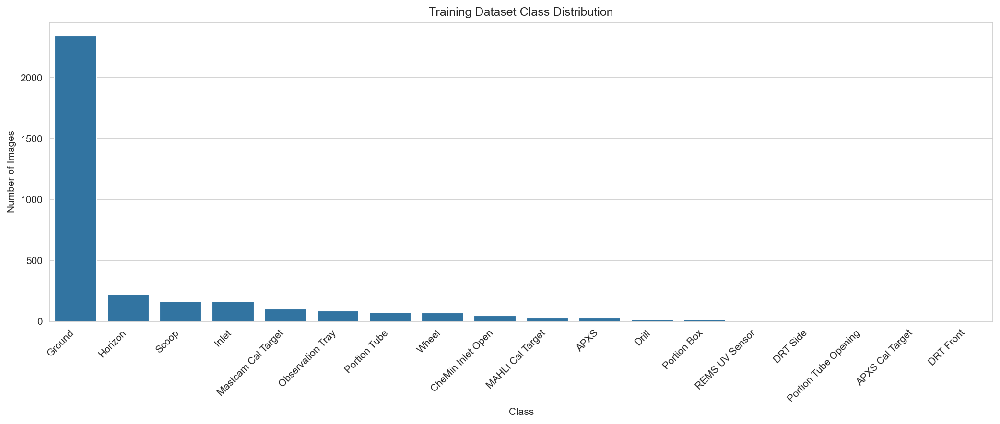

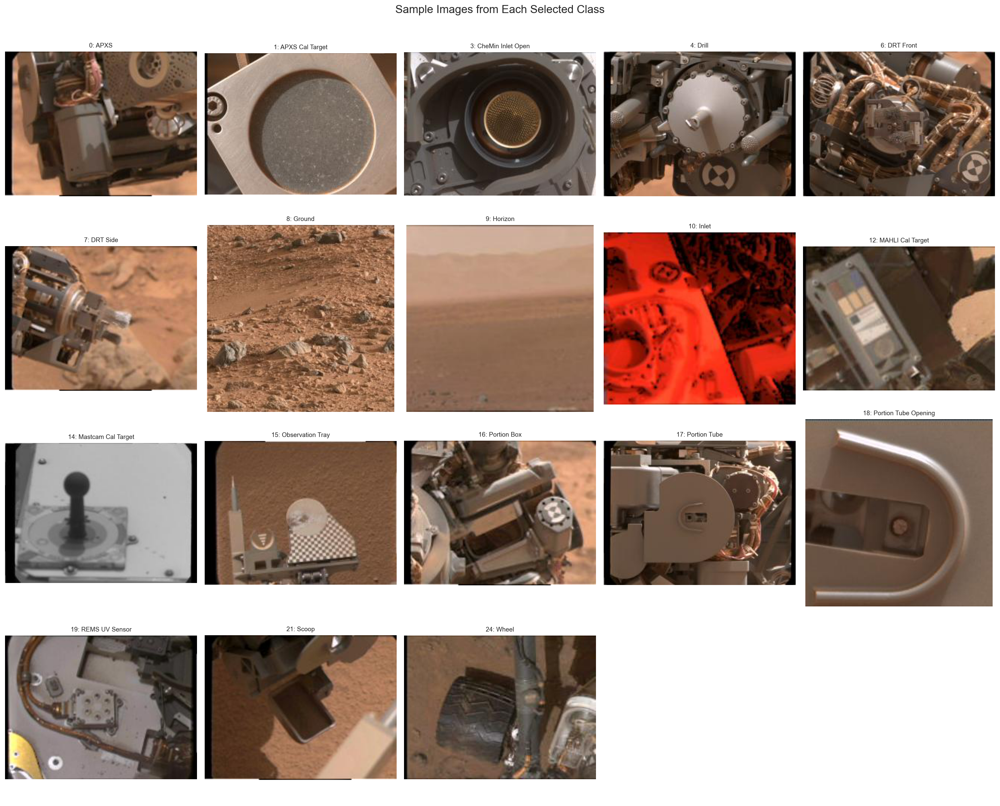

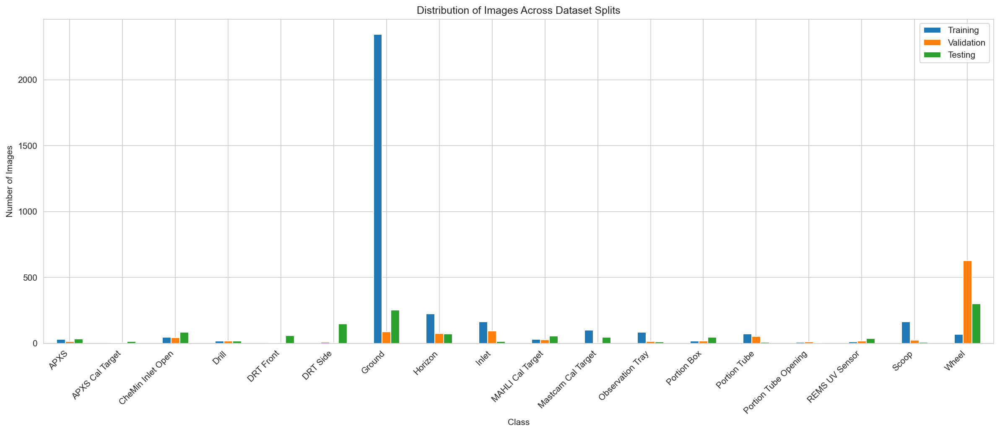

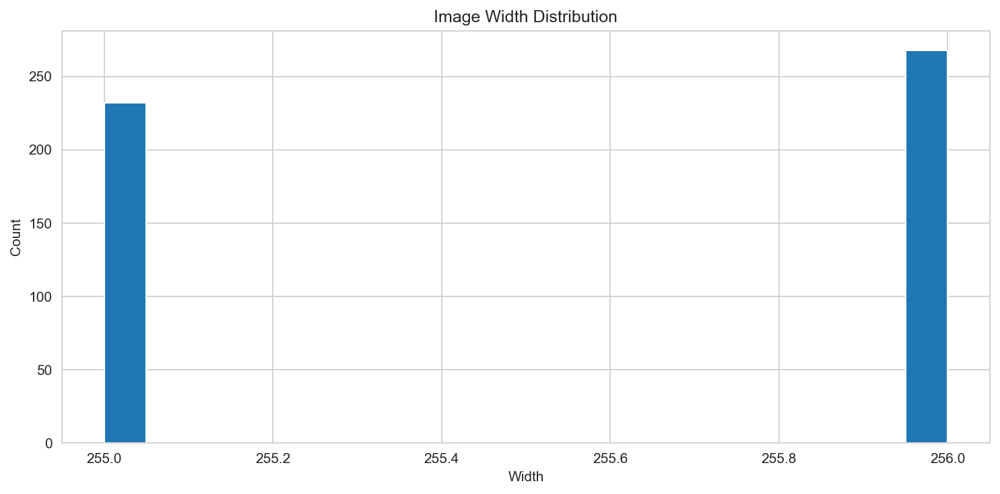

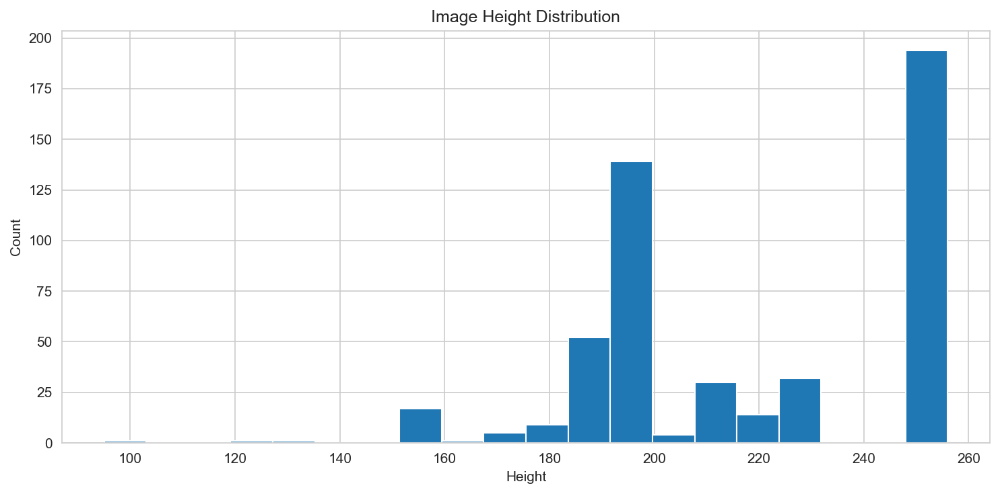

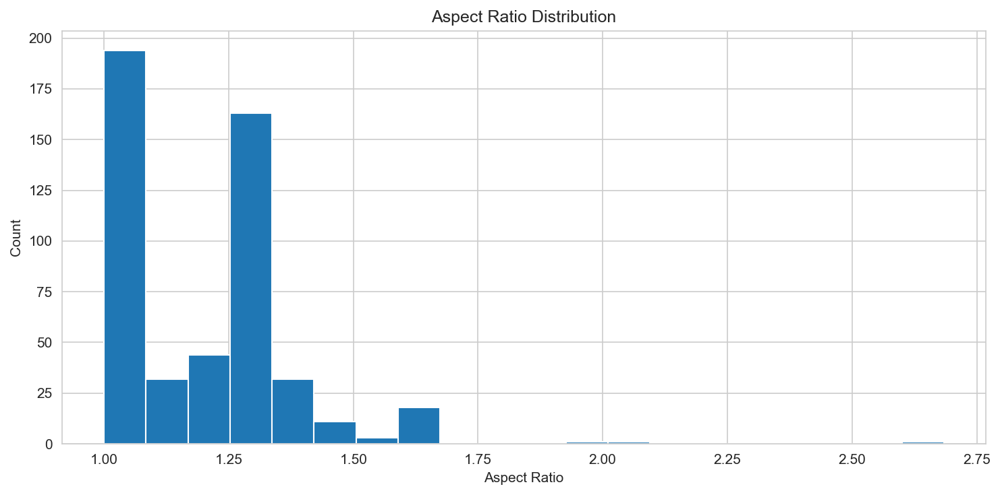

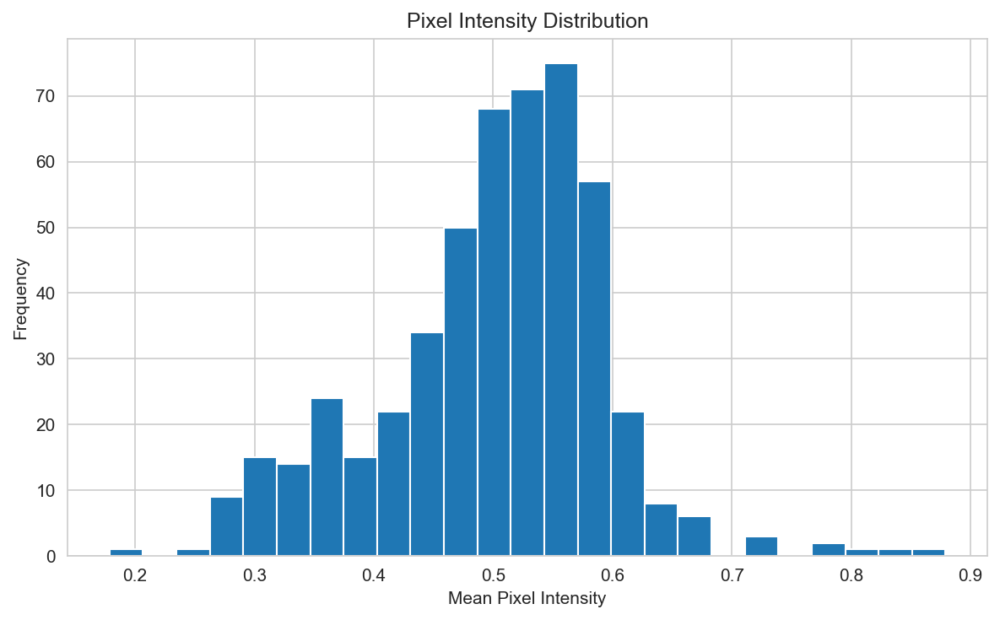

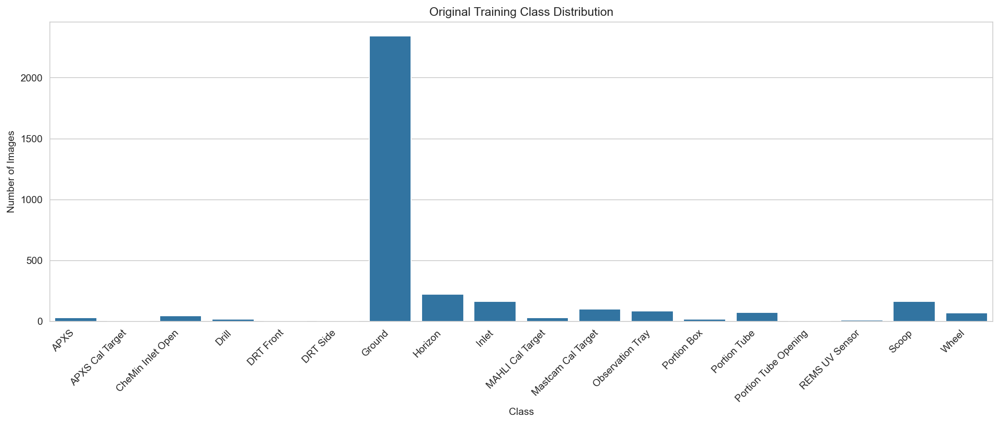

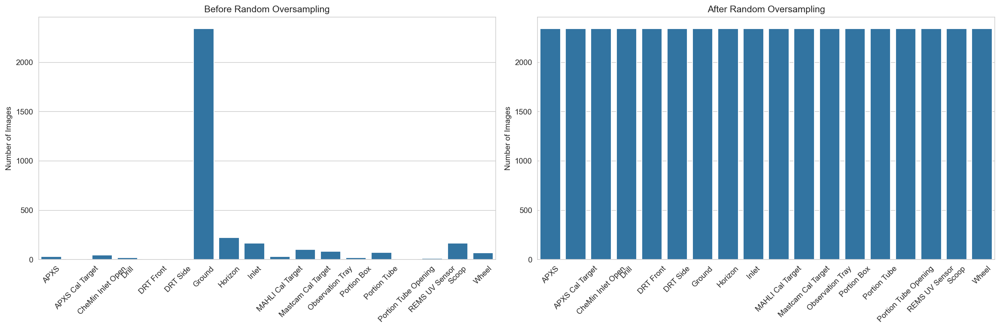


MAIN MODEL: OVERSAMPLING + ORIGINAL-TRAINING CLASS WEIGHTS + FOCAL LOSS

Found 42174 validated image filenames belonging to 18 classes.
Found 1155 validated image filenames belonging to 18 classes.
Epoch 1/30
1318/1318 ━━━━━━━━━━━━━━━━━━━━ 5433s 4s/step - accuracy: 0.8215 - loss: 0.3664 - top3_accuracy: 0.9143 - val_accuracy: 0.8684 - val_loss: 0.1782 - val_top3_accuracy: 0.9446 - learning_rate: 5.0000e-05
Epoch 2/30
1318/1318 ━━━━━━━━━━━━━━━━━━━━ 12973s 10s/step - accuracy: 0.9402 - loss: 0.1263 - top3_accuracy: 0.9859 - val_accuracy: 0.8658 - val_loss: 0.1506 - val_top3_accuracy: 0.9758 - learning_rate: 5.0000e-05
Epoch 3/30
1318/1318 ━━━━━━━━━━━━━━━━━━━━ 4513s 3s/step - accuracy: 0.9553 - loss: 0.1099 - top3_accuracy: 0.9914 - val_accuracy: 0.9074 - val_loss: 0.1330 - val_top3_accuracy: 0.9810 - learning_rate: 5.0000e-05
Epoch 4/30
1318/1318 ━━━━━━━━━━━━━━━━━━━━ 4525s 3s/step - accuracy: 0.9647 - loss: 0.0975 - top3_accuracy: 0.9951 - val_accuracy: 0.9255 - val_loss: 0.1191 - val_t


KeyboardInterrupt



In [10]:
# ============================================================
# PLOS ONE REVISION PIPELINE — ONE CELL
# Manuscript: An Explainable Transfer Learning Approach for
# Balanced Classification of Martian Surface Imagery
#
# Reviewer-driven fixes included:
# 1) Independent seed-dependent oversampling (42–46).
# 2) Repeated full-model experiments with mean ± SD and 95% CI.
# 3) Seven-condition ablation separating CE/focal, oversampling,
#    and class weighting individually and in combination.
# 4) Paired statistical comparison of ablation conditions.
# 5) Validation-vs-chronological-test per-class analysis with support n.
# 6) Explicit oversampling/duplication diagnostics.
# 7) Chronological boundary sensitivity with optional retraining.
# 8) Correct/misclassified Grad-CAM + earlier/final-layer comparison.
# 9) No fabricated temporal/class-exclusion claims.
# 10) Original EDA/figures are retained and regenerated.
#
# IMPORTANT SCIENTIFIC NOTES
# - The code does NOT call validation accuracy "test" accuracy.
# - The chronological test set is never used for model selection.
# - Test metrics are reported only after model selection on validation.
# - The 18-class benchmark is retained, but the code cannot invent
#   the scientific reason why the seven excluded classes were omitted.
#   EXCLUSION_RATIONALE below must be completed from dataset provenance.
# - 1/255 preprocessing is retained to avoid silently changing the
#   previously implemented experiment. If the manuscript is changed to
#   VGG16 preprocess_input, all main results must be rerun.
# ============================================================

import os, math, random, warnings, gc, json, time
from pathlib import Path
from datetime import datetime
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout, BatchNormalization, Activation
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger
from tensorflow.keras.utils import plot_model, to_categorical

from sklearn.utils import resample
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, cohen_kappa_score, matthews_corrcoef,
    roc_curve, auc, precision_recall_curve, average_precision_score
)
from scipy import stats

# ------------------------------------------------------------
# 0. CONFIGURATION
# ------------------------------------------------------------
SEEDS = [42, 43, 44, 45, 46]
MAIN_SEED = 42

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

# Preserve the implemented main training schedule.
MAIN_STAGE1_EPOCHS = 30
MAIN_FINETUNE_EPOCHS = 20
INITIAL_LR = 5e-5
FINE_TUNE_LR = 1e-5
DROPOUT = 0.5
FOCAL_ALPHA = 0.25
FOCAL_GAMMA = 2.0

# Reviewer experiments.
RUN_REPEATED_MAIN = True
RUN_ABLATION = True
RUN_BOUNDARY_SENSITIVITY = True
RUN_GRADCAM = True

# Ablations are intentionally shorter than the main experiment to keep the
# seven-condition × five-seed experiment computationally practical. All
# conditions use exactly the same schedule and seeds for fair comparison.
ABLATION_STAGE1_EPOCHS = 12
ABLATION_FINETUNE_EPOCHS = 8
ABLATION_SEEDS = SEEDS

# Boundary sensitivity is a true performance sensitivity analysis only when
# retraining is enabled. It is enabled here because this is a reviewer request.
BOUNDARY_FRACTIONS = [-0.10, -0.05, 0.00, 0.05, 0.10]
BOUNDARY_RETRAIN = True
BOUNDARY_STAGE1_EPOCHS = 8
BOUNDARY_FINETUNE_EPOCHS = 4
BOUNDARY_SEEDS = [42]  # controlled sensitivity run; main repeated analysis remains 5 seeds

MAX_IMAGE_STATS = 500
EARLY_STOP_PATIENCE = 5
LR_PATIENCE = 2

# Optional backbone comparison. Keep False unless you actually want to add
# a new controlled architecture experiment to the manuscript.
RUN_BACKBONE_ABLATION = False

BASE_DIR_CANDIDATES = [
    r"E:\Dr. Atef Ismail\DAFI-DTI_30-1-2025\Proposal\Proposal 3 new\Dataset\archive (5)\Mars Surface and Curiosity Image",
]
OUTPUT_DIR_CANDIDATES = [
    r"E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports",
    str(Path.cwd() / "Mars_VGG16_PLOS1_Revision"),
]

# Seven excluded classes: DO NOT invent reasons. Replace the placeholders
# with the actual dataset/benchmark rationale before manuscript submission.
EXCLUSION_RATIONALE = {
    "2": "USER MUST CONFIRM FROM DATASET/ORIGINAL BENCHMARK",
    "5": "USER MUST CONFIRM FROM DATASET/ORIGINAL BENCHMARK",
    "11": "USER MUST CONFIRM FROM DATASET/ORIGINAL BENCHMARK",
    "13": "USER MUST CONFIRM FROM DATASET/ORIGINAL BENCHMARK",
    "20": "USER MUST CONFIRM FROM DATASET/ORIGINAL BENCHMARK",
    "22": "USER MUST CONFIRM FROM DATASET/ORIGINAL BENCHMARK",
    "23": "USER MUST CONFIRM FROM DATASET/ORIGINAL BENCHMARK",
}

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------
BASE_DIR = next((p for p in BASE_DIR_CANDIDATES if os.path.isdir(p)), BASE_DIR_CANDIDATES[0])
if not os.path.isdir(BASE_DIR):
    raise FileNotFoundError(
        "Dataset directory was not found. Update BASE_DIR_CANDIDATES to the folder containing "
        "Train_CSV.csv, Validation_CSV.csv and Test_CSV.csv."
    )

OUTPUT_DIR = next((p for p in OUTPUT_DIR_CANDIDATES if os.path.isdir(p)), OUTPUT_DIR_CANDIDATES[-1])
FIG_DIR = os.path.join(OUTPUT_DIR, "Figures")
TABLE_DIR = os.path.join(OUTPUT_DIR, "Tables")
REPORT_DIR = os.path.join(OUTPUT_DIR, "Reports")
MODEL_DIR = os.path.join(OUTPUT_DIR, "Models")
GRADCAM_DIR = os.path.join(OUTPUT_DIR, "GradCAM")
LOG_DIR = os.path.join(OUTPUT_DIR, "Logs")
for p in [OUTPUT_DIR, FIG_DIR, TABLE_DIR, REPORT_DIR, MODEL_DIR, GRADCAM_DIR, LOG_DIR]:
    os.makedirs(p, exist_ok=True)

TRAIN_CSV = os.path.join(BASE_DIR, "Train_CSV.csv")
VAL_CSV = os.path.join(BASE_DIR, "Validation_CSV.csv")
TEST_CSV = os.path.join(BASE_DIR, "Test_CSV.csv")
for p in [TRAIN_CSV, VAL_CSV, TEST_CSV]:
    if not os.path.isfile(p):
        raise FileNotFoundError(f"Required CSV not found: {p}")

# ------------------------------------------------------------
# 2. REPRODUCIBILITY
# ------------------------------------------------------------
def set_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seed(MAIN_SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception:
        pass

print("=" * 90)
print("PLOS ONE REVISED MARTIAN IMAGE CLASSIFICATION PIPELINE")
print("TensorFlow:", tf.__version__)
print("GPU(s):", len(gpus))
print("Dataset:", BASE_DIR)
print("Output:", OUTPUT_DIR)
print("=" * 90)

# ------------------------------------------------------------
# 3. CLASS DEFINITIONS
# ------------------------------------------------------------
CLASS_MAPPING = {
    "0": "APXS",
    "1": "APXS Cal Target",
    "3": "CheMin Inlet Open",
    "4": "Drill",
    "6": "DRT Front",
    "7": "DRT Side",
    "8": "Ground",
    "9": "Horizon",
    "10": "Inlet",
    "12": "MAHLI Cal Target",
    "14": "Mastcam Cal Target",
    "15": "Observation Tray",
    "16": "Portion Box",
    "17": "Portion Tube",
    "18": "Portion Tube Opening",
    "19": "REMS UV Sensor",
    "21": "Scoop",
    "24": "Wheel",
}
ALL_DATASET_LABELS = [str(i) for i in range(25)]
SELECTED_LABELS = list(CLASS_MAPPING.keys())
CLASS_NAMES = list(CLASS_MAPPING.values())
LABEL_TO_INDEX = {lab: i for i, lab in enumerate(SELECTED_LABELS)}
INDEX_TO_LABEL = {i: lab for lab, i in LABEL_TO_INDEX.items()}

CLASS_DESCRIPTION = {
    "APXS": "Alpha Particle X-ray Spectrometer mounted on the rover.",
    "APXS Cal Target": "Calibration target used for APXS instrument calibration.",
    "CheMin Inlet Open": "Open inlet of the Chemistry and Mineralogy instrument.",
    "Drill": "Rotary drill used for collecting rock samples.",
    "DRT Front": "Front view of the Dust Removal Tool.",
    "DRT Side": "Side view of the Dust Removal Tool.",
    "Ground": "Martian soil, rocks, and surface textures.",
    "Horizon": "Distant Martian landscape and skyline.",
    "Inlet": "Scientific sample inlet on the rover.",
    "MAHLI Cal Target": "Calibration target for the MAHLI camera.",
    "Mastcam Cal Target": "Calibration target for the Mastcam imaging system.",
    "Observation Tray": "Tray used for scientific observations.",
    "Portion Box": "Container for processed samples.",
    "Portion Tube": "Tube used during sample handling.",
    "Portion Tube Opening": "Opening of the sample transfer tube.",
    "REMS UV Sensor": "Ultraviolet sensor of the Rover Environmental Monitoring Station.",
    "Scoop": "Sampling scoop mounted on the robotic arm.",
    "Wheel": "Curiosity rover wheel.",
}

# ------------------------------------------------------------
# 4. LOAD AND VALIDATE DATA
# ------------------------------------------------------------
def load_raw(csv_path):
    df = pd.read_csv(csv_path)
    required = {"LABELS", "JPG"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{csv_path} is missing columns: {sorted(missing)}")
    df = df.copy()
    df["LABELS"] = df["LABELS"].astype(str)
    return df

def attach_paths(df):
    out = df.copy()
    out["full_path"] = out["JPG"].astype(str).apply(lambda x: os.path.join(BASE_DIR, x))
    out["CLASS_NAME"] = out["LABELS"].map(CLASS_MAPPING)
    out["exists"] = out["full_path"].apply(os.path.exists)
    missing = int((~out["exists"]).sum())
    out = out[out["exists"]].drop(columns=["exists"]).reset_index(drop=True)
    return out, missing

raw_train = load_raw(TRAIN_CSV)
raw_val = load_raw(VAL_CSV)
raw_test = load_raw(TEST_CSV)

train_df, missing_train = attach_paths(raw_train)
val_df, missing_val = attach_paths(raw_val)
test_df, missing_test = attach_paths(raw_test)

train_df = train_df[train_df["LABELS"].isin(SELECTED_LABELS)].reset_index(drop=True)
val_df = val_df[val_df["LABELS"].isin(SELECTED_LABELS)].reset_index(drop=True)
test_df = test_df[test_df["LABELS"].isin(SELECTED_LABELS)].reset_index(drop=True)

TRAIN_LABELS = [x for x in SELECTED_LABELS if x in set(train_df["LABELS"])]
val_df = val_df[val_df["LABELS"].isin(TRAIN_LABELS)].reset_index(drop=True)
test_df = test_df[test_df["LABELS"].isin(TRAIN_LABELS)].reset_index(drop=True)

print("Loaded images:")
print(f"  Train: {len(train_df):,}")
print(f"  Val:   {len(val_df):,}")
print(f"  Test:  {len(test_df):,}")
print(f"  Missing paths: train={missing_train}, val={missing_val}, test={missing_test}")
print("  Model classes:", len(TRAIN_LABELS), TRAIN_LABELS)

# Full 25-class inventory before filtering.
all_raw = pd.concat([
    raw_train.assign(Split="Train"),
    raw_val.assign(Split="Validation"),
    raw_test.assign(Split="Test")
], ignore_index=True)
all_raw["LABELS"] = all_raw["LABELS"].astype(str)

class_inventory = pd.DataFrame({"Label": ALL_DATASET_LABELS})
for split_name, raw in [("Train", raw_train), ("Validation", raw_val), ("Test", raw_test)]:
    vc = raw["LABELS"].astype(str).value_counts()
    class_inventory[split_name + "_n"] = class_inventory["Label"].map(vc).fillna(0).astype(int)
class_inventory["Total_n"] = class_inventory[["Train_n", "Validation_n", "Test_n"]].sum(axis=1)
class_inventory["Class_Name"] = class_inventory["Label"].map(CLASS_MAPPING).fillna("Excluded / not in selected 18-class output space")
class_inventory["Selected"] = class_inventory["Label"].isin(TRAIN_LABELS)
class_inventory["Exclusion_Rationale"] = class_inventory["Label"].map(EXCLUSION_RATIONALE).fillna("")
class_inventory.to_csv(os.path.join(TABLE_DIR, "All_25_Class_Inventory.csv"), index=False)

excluded_labels = [x for x in ALL_DATASET_LABELS if x not in TRAIN_LABELS]
exclusion_report = class_inventory[class_inventory["Label"].isin(excluded_labels)].copy()
exclusion_report["Status"] = np.where(
    exclusion_report["Exclusion_Rationale"].str.contains("USER MUST CONFIRM", na=False),
    "REQUIRES_MANUSCRIPT_CONFIRMATION", "Documented"
)
exclusion_report.to_csv(os.path.join(REPORT_DIR, "Excluded_Classes_Report.csv"), index=False)

if any(exclusion_report["Status"] == "REQUIRES_MANUSCRIPT_CONFIRMATION"):
    print("\nWARNING: seven-class exclusion rationale still requires confirmation from dataset provenance.")

# ------------------------------------------------------------
# 5. DATA DISTRIBUTION / EDA
# ------------------------------------------------------------
dist = pd.DataFrame(index=TRAIN_LABELS)
dist["Class_Name"] = [CLASS_MAPPING[x] for x in TRAIN_LABELS]
dist["Training"] = train_df["LABELS"].value_counts().reindex(TRAIN_LABELS, fill_value=0).astype(int)
dist["Validation"] = val_df["LABELS"].value_counts().reindex(TRAIN_LABELS, fill_value=0).astype(int)
dist["Chronological_Test"] = test_df["LABELS"].value_counts().reindex(TRAIN_LABELS, fill_value=0).astype(int)
dist["Training_%"] = 100 * dist["Training"] / max(1, dist["Training"].sum())
dist["Validation_%"] = 100 * dist["Validation"] / max(1, dist["Validation"].sum())
dist["Test_%"] = 100 * dist["Chronological_Test"] / max(1, dist["Chronological_Test"].sum())
dist["Test_n"] = dist["Chronological_Test"]
dist.to_csv(os.path.join(TABLE_DIR, "Class_Distribution_Train_Val_ChronologicalTest.csv"))

sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300})

# Figure 2
plt.figure(figsize=(14, 6))
tmp = dist.sort_values("Training", ascending=False)
sns.barplot(x=tmp["Class_Name"], y=tmp["Training"].values)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Class"); plt.ylabel("Number of Images")
plt.title("Training Dataset Class Distribution")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Figure2_ClassDistribution.png"), bbox_inches="tight"); plt.show()

# Figure 3 sample images
n_cols = 5
n_rows = math.ceil(len(TRAIN_LABELS) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4*n_rows))
axes = np.asarray(axes).reshape(-1)
for i, lab in enumerate(TRAIN_LABELS):
    row = train_df[train_df["LABELS"] == lab].iloc[0]
    try:
        axes[i].imshow(Image.open(row["full_path"]).convert("RGB"))
    except Exception:
        axes[i].text(0.5, 0.5, "Image unavailable", ha="center")
    axes[i].set_title(f"{lab}: {CLASS_MAPPING[lab]}", fontsize=9)
    axes[i].axis("off")
for ax in axes[len(TRAIN_LABELS):]: ax.axis("off")
plt.suptitle("Sample Images from Each Selected Class", y=1.0, fontsize=16)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Figure3_SampleImages.png"), bbox_inches="tight"); plt.show()

# Split distribution
plot_dist = dist.set_index("Class_Name")[["Training", "Validation", "Chronological_Test"]].copy()
plot_dist.columns = ["Training", "Validation", "Testing"]
plot_dist.plot(kind="bar", figsize=(16,7))
plt.ylabel("Number of Images"); plt.xlabel("Class")
plt.title("Distribution of Images Across Dataset Splits")
plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Figure3_DatasetDistribution.png"), bbox_inches="tight"); plt.show()

# Resolution / aspect ratio
widths, heights, aspect_ratios = [], [], []
for path in train_df["full_path"].sample(min(MAX_IMAGE_STATS, len(train_df)), random_state=MAIN_SEED):
    try:
        with Image.open(path) as im:
            w, h = im.size
        widths.append(w); heights.append(h); aspect_ratios.append(w/h)
    except Exception:
        pass
if widths:
    for vals, title, xlabel, fname in [
        (widths, "Image Width Distribution", "Width", "ImageWidthDistribution.png"),
        (heights, "Image Height Distribution", "Height", "ImageHeightDistribution.png"),
        (aspect_ratios, "Aspect Ratio Distribution", "Aspect Ratio", "AspectRatio.png")
    ]:
        plt.figure(figsize=(10,5)); plt.hist(vals, bins=20)
        plt.title(title); plt.xlabel(xlabel); plt.ylabel("Count")
        plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, fname), bbox_inches="tight"); plt.show()
    pd.DataFrame({
        "Metric":["Minimum Width","Maximum Width","Average Width","Minimum Height","Maximum Height","Average Height","Average Aspect Ratio"],
        "Value":[min(widths),max(widths),np.mean(widths),min(heights),max(heights),np.mean(heights),np.mean(aspect_ratios)]
    }).to_csv(os.path.join(TABLE_DIR, "ImageResolution.csv"), index=False)

# Pixel intensity
sample_paths = train_df["full_path"].sample(min(MAX_IMAGE_STATS, len(train_df)), random_state=MAIN_SEED)
pixel_means, pixel_stds, rgb_sum = [], [], np.zeros(3); rgb_n = 0
for path in sample_paths:
    try:
        arr = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32)/255.0
        pixel_means.append(arr.mean()); pixel_stds.append(arr.std())
        rgb_sum += arr.mean(axis=(0,1)); rgb_n += 1
    except Exception:
        pass
if pixel_means:
    plt.figure(figsize=(8,5)); plt.hist(pixel_means, bins=25)
    plt.xlabel("Mean Pixel Intensity"); plt.ylabel("Frequency"); plt.title("Pixel Intensity Distribution")
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "PixelIntensity.png"), bbox_inches="tight"); plt.show()
    pd.DataFrame({"Channel":["R","G","B"],"Mean":[*(rgb_sum/max(1,rgb_n))]}).to_csv(os.path.join(TABLE_DIR, "Mean_RGB.csv"), index=False)

# Table 1
pd.DataFrame({
    "Original Label": TRAIN_LABELS,
    "Class Name": [CLASS_MAPPING[x] for x in TRAIN_LABELS],
    "Description": [CLASS_DESCRIPTION[CLASS_MAPPING[x]] for x in TRAIN_LABELS]
}).to_csv(os.path.join(TABLE_DIR, "Table1_SelectedClasses.csv"), index=False)

# ------------------------------------------------------------
# 6. OVERSAMPLING DIAGNOSTICS — SEED-INDEPENDENT SUMMARY + SEED-DEPENDENT RUNS
# ------------------------------------------------------------
original_counts = train_df["LABELS"].value_counts().reindex(TRAIN_LABELS, fill_value=0)
majority_count = int(original_counts.max())

plt.figure(figsize=(14,6))
sns.barplot(x=[CLASS_MAPPING[x] for x in TRAIN_LABELS], y=original_counts.values)
plt.xticks(rotation=45, ha="right"); plt.ylabel("Number of Images"); plt.xlabel("Class")
plt.title("Original Training Class Distribution")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Figure5_OriginalDistribution.png"), bbox_inches="tight"); plt.show()

def make_balanced_training_set(df, seed):
    counts = df["LABELS"].value_counts().reindex(TRAIN_LABELS, fill_value=0)
    target = int(counts.max())
    frames = []
    for lab in TRAIN_LABELS:
        subset = df[df["LABELS"] == lab]
        if len(subset) == 0:
            continue
        frames.append(resample(subset, replace=True, n_samples=target, random_state=int(seed)))
    out = pd.concat(frames, ignore_index=True)
    return out.sample(frac=1.0, random_state=int(seed)).reset_index(drop=True)

balanced_train_df = make_balanced_training_set(train_df, MAIN_SEED)
balanced_counts = balanced_train_df["LABELS"].value_counts().reindex(TRAIN_LABELS, fill_value=0)

fig, ax = plt.subplots(1,2, figsize=(18,6))
sns.barplot(x=[CLASS_MAPPING[x] for x in TRAIN_LABELS], y=original_counts.values, ax=ax[0])
ax[0].set_title("Before Random Oversampling"); ax[0].tick_params(axis="x", rotation=45)
sns.barplot(x=[CLASS_MAPPING[x] for x in TRAIN_LABELS], y=balanced_counts.values, ax=ax[1])
ax[1].set_title("After Random Oversampling"); ax[1].tick_params(axis="x", rotation=45)
for a in ax: a.set_ylabel("Number of Images")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Figure6_Oversampling.png"), bbox_inches="tight"); plt.show()
balanced_train_df.to_csv(os.path.join(TABLE_DIR, "BalancedTraining_seed42.csv"), index=False)

over = pd.DataFrame({
    "LABELS": TRAIN_LABELS,
    "Class_Name": [CLASS_MAPPING[x] for x in TRAIN_LABELS],
    "Original_Training_n": original_counts.values,
    "Balanced_n": balanced_counts.values,
})
over["Duplication_Factor"] = over["Balanced_n"] / over["Original_Training_n"].replace(0, np.nan)
over["Additional_Replications"] = over["Balanced_n"] - over["Original_Training_n"]
over.to_csv(os.path.join(TABLE_DIR, "Oversampling_Duplication_Factors.csv"), index=False)

# Class weights MUST be computed from original training distribution.
class_weights_array = compute_class_weight(
    class_weight="balanced", classes=np.array(TRAIN_LABELS), y=train_df["LABELS"].values
)
ORIGINAL_CLASS_WEIGHTS = {i: float(w) for i, w in enumerate(class_weights_array)}
weight_table = pd.DataFrame({
    "LABELS": TRAIN_LABELS,
    "Class_Name": [CLASS_MAPPING[x] for x in TRAIN_LABELS],
    "Original_Training_Count": original_counts.values,
    "Class_Weight": class_weights_array
})
weight_table.to_csv(os.path.join(TABLE_DIR, "ClassWeights_From_OriginalTraining.csv"), index=False)

# ------------------------------------------------------------
# 7. GENERATORS
# ------------------------------------------------------------
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.20,
    height_shift_range=0.20,
    shear_range=0.15,
    zoom_range=0.25,
    horizontal_flip=True,
    brightness_range=(0.9, 1.1),
    fill_mode="nearest"
)
eval_datagen = ImageDataGenerator(rescale=1./255)

def make_generator(df, train=False, shuffle=False, seed=MAIN_SEED):
    datagen = train_datagen if train else eval_datagen
    return datagen.flow_from_dataframe(
        dataframe=df,
        x_col="full_path", y_col="LABELS",
        classes=TRAIN_LABELS,
        target_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        class_mode="categorical",
        shuffle=shuffle,
        seed=int(seed)
    )

# ------------------------------------------------------------
# 8. LOSS / MODEL
# ------------------------------------------------------------
def categorical_focal_loss(alpha=0.25, gamma=2.0):
    def loss(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, K.epsilon(), 1.0-K.epsilon())
        ce = -y_true * tf.math.log(y_pred)
        weight = alpha * tf.pow(1.0-y_pred, gamma)
        return tf.reduce_sum(weight * ce, axis=1)
    loss.__name__ = "categorical_focal_loss"
    return loss

def build_model(seed=MAIN_SEED):
    set_seed(seed)
    base = VGG16(weights="imagenet", include_top=False, input_shape=(224,224,3))
    base.trainable = False
    for layer in base.layers: layer.trainable = False
    inputs = Input(shape=(224,224,3), name="input_image")
    x = base(inputs, training=False)
    x = Flatten(name="flatten_features")(x)
    x = Dense(512, kernel_regularizer=l2(1e-4), name="dense_512")(x)
    x = BatchNormalization(name="batch_norm")(x)
    x = Activation("relu", name="relu")(x)
    x = Dropout(DROPOUT, name="dropout")(x)
    outputs = Dense(len(TRAIN_LABELS), activation="softmax", dtype="float32", name="classifier")(x)
    return Model(inputs, outputs, name="VGG16_Martian_Classifier"), base

def compile_model(model, lr, use_focal):
    loss = categorical_focal_loss(FOCAL_ALPHA, FOCAL_GAMMA) if use_focal else "categorical_crossentropy"
    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss=loss,
        metrics=["accuracy", tf.keras.metrics.TopKCategoricalAccuracy(k=3, name="top3_accuracy")]
    )

def callbacks_for(run_name):
    ckpt = os.path.join(MODEL_DIR, f"{run_name}_best.keras")
    csv = os.path.join(LOG_DIR, f"{run_name}_history.csv")
    return [
        ModelCheckpoint(ckpt, monitor="val_accuracy", mode="max", save_best_only=True, verbose=0),
        EarlyStopping(monitor="val_accuracy", mode="max", patience=EARLY_STOP_PATIENCE, restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=LR_PATIENCE, min_lr=1e-7, verbose=0),
        CSVLogger(csv, append=False)
    ]

def merge_histories(h1, h2):
    keys = sorted(set(h1.history).union(h2.history))
    return {k: h1.history.get(k, []) + h2.history.get(k, []) for k in keys}

def train_two_stage(train_source, val_source, use_class_weights, use_focal, seed,
                    stage1_epochs, finetune_epochs, run_name, verbose=1):
    tf.keras.backend.clear_session(); gc.collect(); set_seed(seed)
    model, base = build_model(seed)
    tr = make_generator(train_source, train=True, shuffle=True, seed=seed)
    va = make_generator(val_source, train=False, shuffle=False, seed=seed)
    cw = ORIGINAL_CLASS_WEIGHTS if use_class_weights else None

    compile_model(model, INITIAL_LR, use_focal)
    h1 = model.fit(tr, validation_data=va, epochs=stage1_epochs,
                   class_weight=cw, callbacks=callbacks_for(run_name+"_stage1"), verbose=verbose)

    base.trainable = True
    for layer in base.layers[:-8]: layer.trainable = False
    for layer in base.layers[-8:]: layer.trainable = True

    compile_model(model, FINE_TUNE_LR, use_focal)
    h2 = model.fit(tr, validation_data=va,
                   epochs=stage1_epochs+finetune_epochs,
                   initial_epoch=stage1_epochs,
                   class_weight=cw, callbacks=callbacks_for(run_name+"_stage2"), verbose=verbose)
    history = merge_histories(h1, h2)
    best_epoch = int(np.argmax(history["val_accuracy"]))
    model.save(os.path.join(MODEL_DIR, f"{run_name}_final.keras"))
    return model, history, best_epoch

# ------------------------------------------------------------
# 9. EVALUATION
# ------------------------------------------------------------
def multiclass_auc(y_true, probs):
    y_oh = to_categorical(y_true, num_classes=len(TRAIN_LABELS))
    per_auc = {}
    for i, lab in enumerate(TRAIN_LABELS):
        if len(np.unique(y_oh[:, i])) > 1:
            fpr, tpr, _ = roc_curve(y_oh[:, i], probs[:, i])
            per_auc[lab] = auc(fpr, tpr)
        else:
            per_auc[lab] = np.nan
    valid = [v for v in per_auc.values() if np.isfinite(v)]
    return per_auc, float(np.mean(valid)) if valid else np.nan

def evaluate_model(model, df, split_name="test", save_prefix="eval", save_files=True):
    gen = make_generator(df, train=False, shuffle=False, seed=MAIN_SEED)
    gen.reset()
    probs = model.predict(gen, verbose=0)
    y_true = gen.classes.copy()
    y_pred = np.argmax(probs, axis=1)

    acc = accuracy_score(y_true, y_pred)
    bal = balanced_accuracy_score(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred)
    mcc = matthews_corrcoef(y_true, y_pred)
    top3 = np.mean(np.any(np.argsort(probs, axis=1)[:, -3:] == y_true[:, None], axis=1))
    report = classification_report(y_true, y_pred,
        labels=np.arange(len(TRAIN_LABELS)),
        target_names=[CLASS_MAPPING[x] for x in TRAIN_LABELS],
        output_dict=True, zero_division=0)
    report_df = pd.DataFrame(report).transpose()
    per_class = report_df.iloc[:len(TRAIN_LABELS)][["precision","recall","f1-score","support"]].copy()
    per_class["LABELS"] = TRAIN_LABELS
    per_class["Class_Name"] = [CLASS_MAPPING[x] for x in TRAIN_LABELS]
    per_class["support"] = per_class["support"].astype(int)
    per_class["Reliability_Note"] = np.where(
        per_class["support"] < 20,
        "Small test/validation support; interpret point estimate cautiously.",
        "Support >= 20."
    )
    auc_by_class, macro_auc = multiclass_auc(y_true, probs)
    per_class["ROC_AUC_OVR"] = [auc_by_class[x] for x in TRAIN_LABELS]
    per_class = per_class[["LABELS","Class_Name","precision","recall","f1-score","support","ROC_AUC_OVR","Reliability_Note"]]

    metrics = {
        "Split": split_name,
        "N": len(y_true),
        "Accuracy": acc,
        "Top3_Accuracy": top3,
        "Balanced_Accuracy": bal,
        "Macro_Precision": report["macro avg"]["precision"],
        "Macro_Recall": report["macro avg"]["recall"],
        "Macro_F1": report["macro avg"]["f1-score"],
        "Weighted_F1": report["weighted avg"]["f1-score"],
        "Macro_ROC_AUC_OVR": macro_auc,
        "Cohen_Kappa": kappa,
        "MCC": mcc,
    }
    if save_files:
        report_df.to_csv(os.path.join(TABLE_DIR, f"{save_prefix}_{split_name}_classification_report.csv"))
        per_class.to_csv(os.path.join(TABLE_DIR, f"{save_prefix}_{split_name}_per_class.csv"), index=False)
    return metrics, probs, y_true, y_pred, per_class

# ------------------------------------------------------------
# 10. MAIN MODEL — SEED 42 REPRESENTATIVE MODEL
# ------------------------------------------------------------
print("\n" + "="*90)
print("MAIN MODEL: OVERSAMPLING + ORIGINAL-TRAINING CLASS WEIGHTS + FOCAL LOSS")
print("="*90)

main_balanced = make_balanced_training_set(train_df, MAIN_SEED)
main_model, main_history, main_best_epoch = train_two_stage(
    main_balanced, val_df, True, True, MAIN_SEED,
    MAIN_STAGE1_EPOCHS, MAIN_FINETUNE_EPOCHS, "Main_Full_seed42", verbose=1
)

pd.DataFrame(main_history).to_csv(os.path.join(REPORT_DIR, "TrainingHistory_seed42.csv"), index=False)

# Training curves
hist = main_history
epochs = np.arange(1, len(hist["accuracy"])+1)
best_epoch = int(np.argmax(hist["val_accuracy"])) + 1
plt.figure(figsize=(8,6)); plt.plot(epochs,hist["accuracy"],label="Training Accuracy"); plt.plot(epochs,hist["val_accuracy"],label="Validation Accuracy")
plt.scatter(best_epoch,hist["val_accuracy"][best_epoch-1],s=100,marker="*",label=f"Best Epoch ({best_epoch})")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Training and Validation Accuracy"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR,"Accuracy.png"),bbox_inches="tight"); plt.show()
plt.figure(figsize=(8,6)); plt.plot(epochs,hist["loss"],label="Training Loss"); plt.plot(epochs,hist["val_loss"],label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Training and Validation Loss"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR,"Loss.png"),bbox_inches="tight"); plt.show()

with open(os.path.join(REPORT_DIR, "ModelSummary.txt"), "w", encoding="utf-8") as f:
    main_model.summary(print_fn=lambda x: f.write(x+"\n"))
try:
    plot_model(main_model, to_file=os.path.join(FIG_DIR,"VGG16_Architecture.png"), show_shapes=True, show_layer_names=True, dpi=200)
except Exception as e:
    print("plot_model unavailable:", e)

val_metrics, val_probs, val_true, val_pred, val_per_class = evaluate_model(main_model, val_df, "validation", "Main_seed42")
test_metrics, test_probs, test_true, test_pred, test_per_class = evaluate_model(main_model, test_df, "chronological_test", "Main_seed42")

overall = pd.DataFrame([val_metrics, test_metrics])
overall.to_csv(os.path.join(TABLE_DIR,"Validation_vs_ChronologicalTest_Overall.csv"),index=False)
print("\nMAIN RESULTS")
display(overall)

comparison = val_per_class.merge(test_per_class, on=["LABELS","Class_Name"], how="outer", suffixes=("_Validation","_Test"))
comparison["Delta_F1_Test_minus_Validation"] = comparison["f1-score_Test"] - comparison["f1-score_Validation"]
comparison["Delta_Recall_Test_minus_Validation"] = comparison["recall_Test"] - comparison["recall_Validation"]
comparison.to_csv(os.path.join(TABLE_DIR,"Validation_vs_ChronologicalTest_PerClass.csv"),index=False)
display(comparison)

# Confusion matrix
class_names = [CLASS_MAPPING[x] for x in TRAIN_LABELS]
cm = confusion_matrix(test_true,test_pred,labels=np.arange(len(TRAIN_LABELS)))
plt.figure(figsize=(14,12)); sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=class_names,yticklabels=class_names)
plt.xlabel("Predicted Class"); plt.ylabel("True Class"); plt.title("Chronological Test Confusion Matrix")
plt.xticks(rotation=45,ha="right"); plt.yticks(rotation=0); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR,"Figure12_ConfusionMatrix.png"),bbox_inches="tight"); plt.show()

# Per-class performance with support
x=np.arange(len(class_names)); width=.25
plt.figure(figsize=(16,7)); plt.bar(x-width,test_per_class["precision"],width,label="Precision"); plt.bar(x,test_per_class["recall"],width,label="Recall"); plt.bar(x+width,test_per_class["f1-score"],width,label="F1-score")
plt.xticks(x,class_names,rotation=45,ha="right"); plt.ylabel("Score"); plt.ylim(0,1.05); plt.legend(); plt.title("Chronological Test Per-Class Performance")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR,"Figure14_PerClassPerformance.png"),bbox_inches="tight"); plt.show()

# ROC / PR
Y_test_oh=to_categorical(test_true,num_classes=len(TRAIN_LABELS))
plt.figure(figsize=(11,9))
for i,cls in enumerate(class_names):
    if len(np.unique(Y_test_oh[:,i]))>1:
        fpr,tpr,_=roc_curve(Y_test_oh[:,i],test_probs[:,i]); plt.plot(fpr,tpr,label=f"{cls} (AUC={auc(fpr,tpr):.3f})")
plt.plot([0,1],[0,1],"--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("One-vs-Rest ROC Curves — Chronological Test")
plt.legend(fontsize=8,loc="lower right"); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR,"Figure15_ROC.png"),bbox_inches="tight"); plt.show()
plt.figure(figsize=(11,9))
for i,cls in enumerate(class_names):
    if len(np.unique(Y_test_oh[:,i]))>1:
        precision,recall,_=precision_recall_curve(Y_test_oh[:,i],test_probs[:,i]); ap=average_precision_score(Y_test_oh[:,i],test_probs[:,i]); plt.plot(recall,precision,label=f"{cls} AP={ap:.2f}")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall Curves — Chronological Test"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR,"Figure16_PRCurve.png"),bbox_inches="tight"); plt.show()

pred_table=test_df[["full_path","LABELS","CLASS_NAME"]].copy()
pred_table["Predicted_Index"]=test_pred
pred_table["Predicted_Label"]=[TRAIN_LABELS[i] for i in test_pred]
pred_table["Predicted_Class"]=[CLASS_MAPPING[TRAIN_LABELS[i]] for i in test_pred]
pred_table["Correct"]=pred_table["LABELS"].values==pred_table["Predicted_Label"].values
pred_table.to_csv(os.path.join(TABLE_DIR,"TestPredictions.csv"),index=False)

# Explicit validation/test gap
main_gap = pd.DataFrame([{
    "Validation_Accuracy":val_metrics["Accuracy"],
    "Chronological_Test_Accuracy":test_metrics["Accuracy"],
    "Accuracy_Gap_Test_minus_Validation":test_metrics["Accuracy"]-val_metrics["Accuracy"],
    "Validation_Macro_F1":val_metrics["Macro_F1"],
    "Chronological_Test_Macro_F1":test_metrics["Macro_F1"],
    "Macro_F1_Gap_Test_minus_Validation":test_metrics["Macro_F1"]-val_metrics["Macro_F1"],
    "Validation_Balanced_Accuracy":val_metrics["Balanced_Accuracy"],
    "Chronological_Test_Balanced_Accuracy":test_metrics["Balanced_Accuracy"],
    "Balanced_Accuracy_Gap_Test_minus_Validation":test_metrics["Balanced_Accuracy"]-val_metrics["Balanced_Accuracy"],
}])
main_gap.to_csv(os.path.join(TABLE_DIR,"Validation_Test_Generalization_Gap.csv"),index=False)

# ------------------------------------------------------------
# 11. VALIDATION VS TEST CLASS DISTRIBUTION
# ------------------------------------------------------------
dist_pct=dist.copy()
for col in ["Training","Validation","Chronological_Test"]:
    dist_pct[col+"_Percent"]=100*dist_pct[col]/max(1,dist_pct[col].sum())
shift_table=dist_pct[["Class_Name","Validation","Validation_Percent","Chronological_Test","Chronological_Test_Percent"]].copy()
shift_table["Distribution_Delta_PercentagePoints"]=shift_table["Chronological_Test_Percent"]-shift_table["Validation_Percent"]
shift_table.to_csv(os.path.join(TABLE_DIR,"Validation_vs_Test_Class_Distribution_Shift.csv"),index=False)
plt.figure(figsize=(16,7)); shift_table.set_index("Class_Name")[["Validation_Percent","Chronological_Test_Percent"]].plot(kind="bar",figsize=(16,7))
plt.ylabel("Share of split (%)"); plt.xlabel("Class"); plt.title("Validation vs Chronological-Test Class Distribution")
plt.xticks(rotation=45,ha="right"); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR,"Figure_Validation_vs_Test_ClassDistribution.png"),bbox_inches="tight"); plt.show()

# ------------------------------------------------------------
# 12. REPEATED MAIN EXPERIMENT — INDEPENDENT SEED-DEPENDENT OVERSAMPLING
# ------------------------------------------------------------
def repeated_main_runs():
    rows=[]
    for seed in SEEDS:
        print("\n"+"-"*80); print("Repeated full model seed:",seed)
        balanced=make_balanced_training_set(train_df,seed)
        model,hist,bep=train_two_stage(balanced,val_df,True,True,seed,MAIN_STAGE1_EPOCHS,MAIN_FINETUNE_EPOCHS,f"RepeatedFull_seed{seed}",verbose=1)
        vm,_,_,_,_=evaluate_model(model,val_df,"validation",f"RepeatedFull_seed{seed}",save_files=False)
        tm,_,_,_,_=evaluate_model(model,test_df,"chronological_test",f"RepeatedFull_seed{seed}",save_files=False)
        rows.append({"Seed":seed,**{f"Validation_{k}":v for k,v in vm.items() if k not in ["Split","N"]},**{f"Test_{k}":v for k,v in tm.items() if k not in ["Split","N"]},"Best_Epoch":bep+1})
        del model; tf.keras.backend.clear_session(); gc.collect()
    raw=pd.DataFrame(rows); raw.to_csv(os.path.join(TABLE_DIR,"Repeated_Full_Model_Seeds_42_46.csv"),index=False)
    metric_cols=[c for c in raw.columns if c!="Seed"]
    summary=[]
    for col in metric_cols:
        vals=raw[col].astype(float).dropna().values; n=len(vals); mean=float(np.mean(vals)); sd=float(np.std(vals,ddof=1)) if n>1 else np.nan
        if n>1:
            sem=sd/np.sqrt(n); tcrit=stats.t.ppf(.975,n-1); lo=mean-tcrit*sem; hi=mean+tcrit*sem
        else: lo=hi=np.nan
        summary.append({"Metric":col,"N":n,"Mean":mean,"SD":sd,"CI95_Lower":lo,"CI95_Upper":hi,"Mean_SD":f"{mean:.4f} ± {sd:.4f}" if np.isfinite(sd) else f"{mean:.4f}"})
    summary=pd.DataFrame(summary); summary.to_csv(os.path.join(TABLE_DIR,"Repeated_Full_Model_Mean_SD_95CI.csv"),index=False)
    display(raw); display(summary)
    return raw,summary

if RUN_REPEATED_MAIN:
    repeated_results,repeated_summary=repeated_main_runs()
else:
    repeated_results,repeated_summary=None,None

# ------------------------------------------------------------
# 13. SEVEN-CONDITION ABLATION
# ------------------------------------------------------------
ABLATIONS=[
    {"Condition":"A1 Baseline: CE","oversampling":False,"class_weights":False,"focal":False},
    {"Condition":"A2 Focal only","oversampling":False,"class_weights":False,"focal":True},
    {"Condition":"A3 Oversampling + CE","oversampling":True,"class_weights":False,"focal":False},
    {"Condition":"A4 Class weighting + CE","oversampling":False,"class_weights":True,"focal":False},
    {"Condition":"A5 Oversampling + Focal","oversampling":True,"class_weights":False,"focal":True},
    {"Condition":"A6 Class weighting + Focal","oversampling":False,"class_weights":True,"focal":True},
    {"Condition":"A7 Full: Oversampling + Class weighting + Focal","oversampling":True,"class_weights":True,"focal":True},
]

def run_ablation():
    rows=[]
    for spec in ABLATIONS:
        for seed in ABLATION_SEEDS:
            print("\n"+"="*80); print(spec["Condition"],"| seed",seed)
            source=make_balanced_training_set(train_df,seed) if spec["oversampling"] else train_df
            model,hist,bep=train_two_stage(source,val_df,spec["class_weights"],spec["focal"],seed,ABLATION_STAGE1_EPOCHS,ABLATION_FINETUNE_EPOCHS,f"Ablation_{spec['Condition'][:2].replace(' ','_')}_seed{seed}",verbose=1)
            vm,_,_,_,_=evaluate_model(model,val_df,"validation",f"Ablation_{spec['Condition'][:2]}_{seed}",save_files=False)
            tm,_,_,_,_=evaluate_model(model,test_df,"chronological_test",f"Ablation_{spec['Condition'][:2]}_{seed}",save_files=False)
            rows.append({"Condition":spec["Condition"],"Seed":seed,"Validation_Accuracy":vm["Accuracy"],"Validation_BalancedAccuracy":vm["Balanced_Accuracy"],"Validation_MacroF1":vm["Macro_F1"],"Test_Accuracy":tm["Accuracy"],"Test_BalancedAccuracy":tm["Balanced_Accuracy"],"Test_MacroF1":tm["Macro_F1"],"Test_MacroAUC":tm["Macro_ROC_AUC_OVR"],"Test_MCC":tm["MCC"],"Best_Epoch":bep+1})
            del model; tf.keras.backend.clear_session(); gc.collect()
    raw=pd.DataFrame(rows); raw.to_csv(os.path.join(TABLE_DIR,"Ablation_All_Runs.csv"),index=False)
    summary=[]
    metric_cols=[c for c in raw.columns if c not in ["Condition","Seed"]]
    for condition,g in raw.groupby("Condition",sort=False):
        for metric in metric_cols:
            vals=g[metric].astype(float).values; n=len(vals); mean=np.mean(vals); sd=np.std(vals,ddof=1)
            sem=sd/np.sqrt(n); tcrit=stats.t.ppf(.975,n-1); lo=mean-tcrit*sem; hi=mean+tcrit*sem
            summary.append({"Condition":condition,"Metric":metric,"N":n,"Mean":mean,"SD":sd,"CI95_Lower":lo,"CI95_Upper":hi})
    summary=pd.DataFrame(summary); summary.to_csv(os.path.join(TABLE_DIR,"Ablation_Mean_SD_95CI.csv"),index=False)

    # Wide table for manuscript use.
    wide=summary.pivot(index="Condition",columns="Metric",values="Mean").reset_index()
    wide.to_csv(os.path.join(TABLE_DIR,"Ablation_Mean_Metrics_Wide.csv"),index=False)

    # Paired statistical tests: Full A7 vs each alternative using identical seeds.
    full_name=ABLATIONS[-1]["Condition"]
    full=raw[raw["Condition"]==full_name].set_index("Seed")
    stat_rows=[]
    for spec in ABLATIONS[:-1]:
        alt=raw[raw["Condition"]==spec["Condition"]].set_index("Seed")
        for metric in ["Test_MacroF1","Test_BalancedAccuracy","Test_Accuracy"]:
            common=full.index.intersection(alt.index)
            a=full.loc[common,metric].values; b=alt.loc[common,metric].values
            try:
                wil=stats.wilcoxon(a,b,alternative="two-sided",zero_method="wilcox",method="auto")
                p=wil.pvalue
            except Exception:
                p=np.nan
            try:
                tt=stats.ttest_rel(a,b)
                pt=tt.pvalue
            except Exception:
                pt=np.nan
            stat_rows.append({"Comparison":f"A7 Full vs {spec['Condition']}","Metric":metric,"Wilcoxon_p":p,"Paired_t_p":pt,"N":len(common)})
    stat_df=pd.DataFrame(stat_rows)
    # Holm correction on Wilcoxon p-values.
    valid=stat_df["Wilcoxon_p"].notna(); pvals=stat_df.loc[valid,"Wilcoxon_p"].values
    order=np.argsort(pvals); adjusted=np.empty(len(pvals)); m=len(pvals)
    running=0
    for rank,idx in enumerate(order):
        val=min(1.0,(m-rank)*pvals[idx]); running=max(running,val); adjusted[idx]=running
    stat_df.loc[valid,"Wilcoxon_Holm_p"]=adjusted
    stat_df.to_csv(os.path.join(TABLE_DIR,"Ablation_Paired_Statistics.csv"),index=False)

    # Main figure requested by reviewer: chronological Macro-F1 and Balanced Accuracy.
    plotdf=raw.groupby("Condition")[["Test_MacroF1","Test_BalancedAccuracy"]].mean().reindex([x["Condition"] for x in ABLATIONS]).reset_index()
    fig,ax=plt.subplots(figsize=(14,7)); x=np.arange(len(plotdf)); w=.36
    ax.bar(x-w/2,plotdf["Test_MacroF1"],w,label="Macro-F1")
    ax.bar(x+w/2,plotdf["Test_BalancedAccuracy"],w,label="Balanced Accuracy")
    ax.set_xticks(x); ax.set_xticklabels(plotdf["Condition"],rotation=25,ha="right"); ax.set_ylim(0,1.05)
    ax.set_ylabel("Score"); ax.set_title("Ablation Study — Chronological Test"); ax.legend(); ax.grid(axis="y",alpha=.25)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR,"Figure_Ablation_ChronologicalTest.png"),bbox_inches="tight"); plt.show()
    display(raw); display(summary); display(stat_df)
    return raw,summary,stat_df

if RUN_ABLATION:
    ablation_raw,ablation_summary,ablation_stats=run_ablation()
else:
    ablation_raw,ablation_summary,ablation_stats=None,None,None

# ------------------------------------------------------------
# 14. MINORITY SUPPORT / OVERSAMPLING RISK
# ------------------------------------------------------------
minority_threshold=max(10,int(np.percentile(original_counts.values,25)))
minority_labels=[lab for lab in TRAIN_LABELS if original_counts[lab]<=minority_threshold]
minority_table=over[over["LABELS"].isin(minority_labels)].copy()
minority_table["Chronological_Test_n"]=minority_table["LABELS"].map(test_df["LABELS"].value_counts()).fillna(0).astype(int)
minority_table["Potential_Overfitting_Risk"]="Higher caution required when duplication factor is large and test support is small."
minority_table.to_csv(os.path.join(TABLE_DIR,"Minority_Classes_Oversampling_Diagnostic.csv"),index=False)

test_support=test_per_class[["LABELS","Class_Name","support","ROC_AUC_OVR","precision","recall","f1-score"]].copy()
test_support["Support_Flag"]=np.where(test_support["support"]<20,"SMALL_SUPPORT","Adequate_support")
test_support.to_csv(os.path.join(TABLE_DIR,"ChronologicalTest_PerClass_WithSupport.csv"),index=False)
display(test_support)

# ------------------------------------------------------------
# 15. CHRONOLOGICAL BOUNDARY SENSITIVITY — ACTUAL RETRAINING
# ------------------------------------------------------------
def find_time_column(df):
    candidates=["sol","Sol","SOL","timestamp","Timestamp","time","Time","date","Date","acquisition_time","image_time","mars_sol","mars_date"]
    for c in candidates:
        if c in df.columns: return c
    return None

def numeric_time_series(df,col):
    num=pd.to_numeric(df[col],errors="coerce")
    if num.notna().sum() >= max(3,int(.8*len(df))): return num
    # Datetime conversion as a secondary route.
    dt=pd.to_datetime(df[col],errors="coerce")
    if dt.notna().sum() >= max(3,int(.8*len(df))): return dt.astype("int64")/1e9
    codes=pd.factorize(df[col].astype(str),sort=True)[0]
    return pd.Series(codes,index=df.index,dtype=float)

if RUN_BOUNDARY_SENSITIVITY:
    tc=find_time_column(raw_train)
    if tc is None:
        pd.DataFrame([{"Status":"UNAVAILABLE","Reason":"No Sol/timestamp/date field exists in the supplied CSV metadata."}]).to_csv(os.path.join(REPORT_DIR,"Chronological_Boundary_Sensitivity.csv"),index=False)
        print("Boundary sensitivity unavailable: no temporal metadata.")
    else:
        combined=pd.concat([raw_train.assign(_source="train"),raw_val.assign(_source="validation"),raw_test.assign(_source="test")],ignore_index=True)
        combined["LABELS"]=combined["LABELS"].astype(str)
        combined=combined[combined["LABELS"].isin(TRAIN_LABELS)].copy()
        combined["full_path"]=combined["JPG"].astype(str).apply(lambda x:os.path.join(BASE_DIR,x))
        combined=combined[combined["full_path"].apply(os.path.exists)].copy().reset_index(drop=True)
        combined["_time_numeric"]=numeric_time_series(combined,tc)
        combined=combined.dropna(subset=["_time_numeric"]).sort_values("_time_numeric").reset_index(drop=True)

        # Boundaries are computed on the filtered, canonical combined dataset,
        # not on raw split sizes. This fixes the earlier denominator problem.
        orig_train_boundary=pd.to_numeric(combined["_source"].eq("train").cumsum(),errors="coerce")
        # Determine the actual empirical temporal boundaries from the original source labels.
        train_times=combined.loc[combined["_source"]=="train","_time_numeric"]
        val_times=combined.loc[combined["_source"]=="validation","_time_numeric"]
        test_times=combined.loc[combined["_source"]=="test","_time_numeric"]
        if len(train_times)==0 or len(val_times)==0 or len(test_times)==0:
            boundary_report=pd.DataFrame([{"Status":"UNAVAILABLE","Reason":"One source split has no usable images after filtering."}])
        else:
            t0=float(train_times.max()); v0=float(val_times.max()); test_min=float(test_times.min())
            # Preserve chronological source order by using percentile positions corresponding to original source counts.
            n=len(combined); train_base=len(train_times)/n; val_base=(len(train_times)+len(val_times))/n
            rows=[]
            for frac in BOUNDARY_FRACTIONS:
                train_frac=float(np.clip(train_base+frac,0.05,0.80))
                test_start_frac=float(np.clip(val_base+frac,train_frac+0.01,0.95))
                train_end=max(1,min(n-2,int(round(train_frac*n))))
                test_start=max(train_end+1,min(n-1,int(round(test_start_frac*n))))
                bt=combined.iloc[:train_end].copy(); bv=combined.iloc[train_end:test_start].copy(); btest=combined.iloc[test_start:].copy()
                row={"Boundary_Shift":frac,"Train_N":len(bt),"Validation_N":len(bv),"Test_N":len(btest),"Train_Time_Max":bt["_time_numeric"].max(),"Validation_Time_Min":bv["_time_numeric"].min() if len(bv) else np.nan,"Validation_Time_Max":bv["_time_numeric"].max() if len(bv) else np.nan,"Test_Time_Min":btest["_time_numeric"].min() if len(btest) else np.nan}
                if BOUNDARY_RETRAIN and len(bt)>0 and len(bv)>0 and len(btest)>0:
                    # Skip boundaries where any model class disappears from training.
                    missing_classes=[lab for lab in TRAIN_LABELS if (bt["LABELS"]==lab).sum()==0]
                    if missing_classes:
                        row["Retraining_Status"]="Skipped: missing training classes " + ",".join(missing_classes)
                    else:
                        old_val=val_df
                        try:
                            bbal=make_balanced_training_set(bt,BOUNDARY_SEEDS[0])
                            bm,bh,bep=train_two_stage(bbal,bv,True,True,BOUNDARY_SEEDS[0],BOUNDARY_STAGE1_EPOCHS,BOUNDARY_FINETUNE_EPOCHS,f"Boundary_{frac:+.2f}".replace("+","p").replace("-","m").replace(".","d"),verbose=1)
                            bm_metrics,_,_,_,_=evaluate_model(bm,btest,"boundary_test",f"Boundary_{frac:+.2f}",save_files=False)
                            row.update({"Retrained_Test_Accuracy":bm_metrics["Accuracy"],"Retrained_Test_BalancedAccuracy":bm_metrics["Balanced_Accuracy"],"Retrained_Test_MacroF1":bm_metrics["Macro_F1"],"Retrained_Test_MacroAUC":bm_metrics["Macro_ROC_AUC_OVR"],"Retraining_Status":"Completed"})
                            del bm; tf.keras.backend.clear_session(); gc.collect()
                        except Exception as e:
                            row["Retraining_Status"]=f"Failed: {e}"
                else:
                    row["Retraining_Status"]="Not run"
                rows.append(row)
            boundary_report=pd.DataFrame(rows)
        boundary_report.to_csv(os.path.join(REPORT_DIR,"Chronological_Boundary_Sensitivity.csv"),index=False)
        display(boundary_report)
        if "Retrained_Test_MacroF1" in boundary_report.columns:
            plt.figure(figsize=(9,6)); plt.plot(boundary_report["Boundary_Shift"],boundary_report["Retrained_Test_MacroF1"],marker="o",label="Macro-F1"); plt.plot(boundary_report["Boundary_Shift"],boundary_report["Retrained_Test_BalancedAccuracy"],marker="o",label="Balanced Accuracy")
            plt.axvline(0,linestyle="--"); plt.xlabel("Relative chronological boundary shift"); plt.ylabel("Score"); plt.title("Chronological Boundary Sensitivity — Retrained Test Performance"); plt.ylim(0,1.05); plt.legend(); plt.grid(alpha=.3)
            plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR,"Figure_ChronologicalBoundaryPerformance.png"),bbox_inches="tight"); plt.show()
        plt.figure(figsize=(10,6)); plt.plot(boundary_report["Boundary_Shift"],boundary_report["Train_N"],marker="o",label="Train"); plt.plot(boundary_report["Boundary_Shift"],boundary_report["Validation_N"],marker="o",label="Validation"); plt.plot(boundary_report["Boundary_Shift"],boundary_report["Test_N"],marker="o",label="Test")
        plt.xlabel("Relative boundary shift"); plt.ylabel("Number of images"); plt.title("Chronological Boundary Sensitivity — Split Sizes"); plt.legend(); plt.grid(alpha=.3)
        plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR,"Figure_ChronologicalBoundarySensitivity.png"),bbox_inches="tight"); plt.show()

# ------------------------------------------------------------
# 16. GRAD-CAM — CORRECT + MISCLASSIFIED + EARLY/FINAL LAYERS
# ------------------------------------------------------------
if RUN_GRADCAM:
    try:
        import cv2
        # VGG16 is nested as a Functional backbone inside the classifier.
        # Search the backbone explicitly so Grad-CAM can access block5_conv3
        # and an earlier convolutional layer reliably.
        backbone_layers=[]
        for layer in main_model.layers:
            if isinstance(layer, tf.keras.Model) and layer.name.lower().startswith("vgg16"):
                backbone_layers = [l for l in layer.layers if isinstance(l, tf.keras.layers.Conv2D)]
                break
        if len(backbone_layers) < 2:
            # Fallback: inspect all nested model layers.
            for layer in main_model.layers:
                if hasattr(layer, "layers"):
                    candidate=[l for l in layer.layers if isinstance(l, tf.keras.layers.Conv2D)]
                    if len(candidate) >= 2:
                        backbone_layers=candidate
                        break
        if len(backbone_layers)<2:
            raise RuntimeError("Fewer than two Conv2D layers were found in the VGG16 backbone.")
        final_conv=backbone_layers[-1].name
        earlier_conv=backbone_layers[-2].name

        def gradcam_for(image_array,layer_name,target_index=None):
            grad_model=Model(inputs=main_model.inputs,outputs=[main_model.get_layer(layer_name).output,main_model.output])
            img=np.expand_dims(image_array.astype(np.float32),axis=0)
            with tf.GradientTape() as tape:
                conv_out,preds=grad_model(img,training=False)
                pred_idx=tf.argmax(preds[0]) if target_index is None else tf.constant(target_index)
                score=preds[:,pred_idx]
            grads=tape.gradient(score,conv_out)
            pooled=tf.reduce_mean(grads,axis=(0,1,2)); conv_out=conv_out[0]
            heat=tf.reduce_sum(conv_out*pooled[tf.newaxis,tf.newaxis,:],axis=-1)
            heat=tf.maximum(heat,0); denom=tf.reduce_max(heat); heat=tf.where(denom>0,heat/denom,tf.zeros_like(heat))
            return heat.numpy(),int(pred_idx.numpy())

        def overlay(original_rgb,heat):
            heat=cv2.resize(heat,(IMAGE_SIZE[1],IMAGE_SIZE[0])); heat_u8=np.uint8(np.clip(heat,0,1)*255); heat_color=cv2.applyColorMap(heat_u8,cv2.COLORMAP_JET)
            return cv2.addWeighted(original_rgb,.60,heat_color,.40,0)

        info=test_df.copy(); info["true_idx"]=test_true; info["pred_idx"]=test_pred; info["correct"]=test_true==test_pred
        # Representative errors: high-confidence error, low-confidence error,
        # and one error from the smallest-support class when available.
        conf=np.max(test_probs,axis=1); info["confidence"]=conf
        wrong=info[~info["correct"]].copy()
        wrong=wrong.sort_values("confidence",ascending=False)
        correct=info[info["correct"]].sort_values("confidence",ascending=False)
        selected=[]
        for _,r in correct.head(2).iterrows(): selected.append((r,"correct"))
        for _,r in wrong.head(2).iterrows(): selected.append((r,"misclassified"))
        if len(wrong):
            rare_label=test_support.sort_values("support").iloc[0]["LABELS"]
            rare=wrong[wrong["LABELS"]==rare_label]
            if len(rare): selected.append((rare.iloc[0],"minority_misclassified"))

        records=[]
        for row,status in selected:
            try:
                original=np.asarray(Image.open(row["full_path"]).convert("RGB").resize(IMAGE_SIZE),dtype=np.uint8)
                inp=original.astype(np.float32)/255.0
                hf,pidx=gradcam_for(inp,final_conv); he,_=gradcam_for(inp,earlier_conv)
                of=overlay(original,hf); oe=overlay(original,he)
                stem=Path(row["full_path"]).stem
                cv2.imwrite(os.path.join(GRADCAM_DIR,f"{status}_{stem}_final.png"),cv2.cvtColor(of,cv2.COLOR_RGB2BGR))
                cv2.imwrite(os.path.join(GRADCAM_DIR,f"{status}_{stem}_early.png"),cv2.cvtColor(oe,cv2.COLOR_RGB2BGR))
                records.append({"Image":os.path.basename(row["full_path"]),"Status":status,"True_Label":row["LABELS"],"True_Class":CLASS_MAPPING[row["LABELS"]],"Predicted_Label":TRAIN_LABELS[pidx],"Predicted_Class":CLASS_MAPPING[TRAIN_LABELS[pidx]],"Confidence":row["confidence"],"Final_Conv_Layer":final_conv,"Earlier_Conv_Layer":earlier_conv})
            except Exception as e:
                records.append({"Image":os.path.basename(row["full_path"]),"Status":status,"Error":str(e)})
        grad_df=pd.DataFrame(records); grad_df.to_csv(os.path.join(TABLE_DIR,"GradCAM_Correct_Misclassified_Summary.csv"),index=False); display(grad_df)

        # Sanity check: deletion/randomization proxy is intentionally modest.
        # We compare Grad-CAM target agreement across adjacent layers, not claim
        # formal faithfulness. The metric is descriptive only.
        consistency=[]
        for row,status in selected:
            try:
                original=np.asarray(Image.open(row["full_path"]).convert("RGB").resize(IMAGE_SIZE),dtype=np.uint8); inp=original.astype(np.float32)/255.0
                hf,_=gradcam_for(inp,final_conv); he,_=gradcam_for(inp,earlier_conv)
                a=cv2.resize(hf,(32,32)).flatten(); b=cv2.resize(he,(32,32)).flatten()
                corr=np.corrcoef(a,b)[0,1] if np.std(a)>0 and np.std(b)>0 else np.nan
                consistency.append({"Image":os.path.basename(row["full_path"]),"Status":status,"Layer_Heatmap_Pearson_Correlation":corr})
            except Exception as e: consistency.append({"Image":os.path.basename(row["full_path"]),"Status":status,"Layer_Heatmap_Pearson_Correlation":np.nan,"Error":str(e)})
        pd.DataFrame(consistency).to_csv(os.path.join(TABLE_DIR,"GradCAM_Layer_Consistency_Descriptive.csv"),index=False)

        # Figure 17: one correct + one misclassified + earlier/final maps.
        chosen=[]
        for status in ["correct","misclassified"]:
            sub=[x for x in selected if x[1]==status]
            if sub: chosen.append(sub[0][0])
        if chosen:
            fig,axes=plt.subplots(len(chosen),3,figsize=(12,4*len(chosen)))
            if len(chosen)==1: axes=np.array([axes])
            for r,row in enumerate(chosen):
                original=np.asarray(Image.open(row["full_path"]).convert("RGB").resize(IMAGE_SIZE),dtype=np.uint8); inp=original.astype(np.float32)/255.0
                hf,_=gradcam_for(inp,final_conv); he,_=gradcam_for(inp,earlier_conv)
                axes[r,0].imshow(original); axes[r,1].imshow(overlay(original,hf)); axes[r,2].imshow(overlay(original,he))
                axes[r,0].set_title(f"Original — {CLASS_MAPPING[row['LABELS']]}"); axes[r,1].set_title(f"Final: {final_conv}"); axes[r,2].set_title(f"Earlier: {earlier_conv}")
                for a in axes[r]: a.axis("off")
            plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR,"Figure17_GradCAM_Correct_vs_Misclassified.png"),bbox_inches="tight"); plt.show()
    except Exception as e:
        pd.DataFrame([{"Status":"UNAVAILABLE","Reason":str(e)}]).to_csv(os.path.join(REPORT_DIR,"GradCAM_Error_Report.csv"),index=False)
        print("Grad-CAM unavailable:",e)

# ------------------------------------------------------------
# 17. CONFIGURATION / REPRODUCIBILITY REPORT
# ------------------------------------------------------------
config_rows=[
    ["Seed list",",".join(map(str,SEEDS))],["Image size",str(IMAGE_SIZE)],["Batch size",BATCH_SIZE],
    ["Main stage 1 epochs",MAIN_STAGE1_EPOCHS],["Main fine-tuning epochs",MAIN_FINETUNE_EPOCHS],
    ["Ablation stage 1 epochs",ABLATION_STAGE1_EPOCHS],["Ablation fine-tuning epochs",ABLATION_FINETUNE_EPOCHS],
    ["Initial learning rate",INITIAL_LR],["Fine-tuning learning rate",FINE_TUNE_LR],
    ["Dropout",DROPOUT],["Focal alpha",FOCAL_ALPHA],["Focal gamma",FOCAL_GAMMA],
    ["Rotation", "30 degrees"],["Width shift","20%"],["Height shift","20%"],["Shear","15%"],["Zoom","25%"],
    ["Horizontal flip",True],["Brightness","(0.9, 1.1)"],["Fill mode","nearest"],
    ["Loss main/full","Categorical focal loss"],["Full-model balancing","Seed-dependent random oversampling + original-training class weights"],
    ["Backbone","ImageNet-pretrained VGG16"],["Fine-tuned layers","Last 8 convolutional layers"],
    ["Preprocessing","Rescale 1/255"],["Boundary retraining",BOUNDARY_RETRAIN],["Boundary shifts",str(BOUNDARY_FRACTIONS)]
]
pd.DataFrame(config_rows,columns=["Parameter","Value"]).to_csv(os.path.join(REPORT_DIR,"Experiment_Config_PLOS1_Revised.csv"),index=False)

# ------------------------------------------------------------
# 18. REVIEWER CHECKLIST
# ------------------------------------------------------------
checklist=[
    ["Chronological validation/test evaluation",True,"Validation and chronological test metrics reported separately."],
    ["Per-class validation/test comparison",True,"Per-class F1, recall, precision, ROC-AUC and support n with deltas."],
    ["Validation/test class-distribution shift",True,"Counts, percentages and percentage-point shifts generated."],
    ["Seven excluded classes",True,"All 25 classes inventoried; scientific exclusion rationale is flagged for author confirmation."],
    ["Repeated seeds 42–46",RUN_REPEATED_MAIN,"Independent seed-dependent oversampling; Mean ± SD and 95% CI."],
    ["Ablation individually",RUN_ABLATION,"CE, focal, oversampling and class-weighting effects separated."],
    ["Ablation combinations",RUN_ABLATION,"Oversampling+focal, class-weighting+focal, full combination."],
    ["Paired ablation statistics",RUN_ABLATION,"Wilcoxon and paired t-tests with Holm-adjusted Wilcoxon p-values."],
    ["Minority support",True,"Per-class validation/test support n reported and flagged."],
    ["Oversampling duplication factor",True,"Per-class duplication factor and additional replications reported."],
    ["Boundary sensitivity",RUN_BOUNDARY_SENSITIVITY,"Canonical filtered dataset; optional/active retraining at ±5% and ±10%."],
    ["Grad-CAM correct cases",RUN_GRADCAM,"Generated."],
    ["Grad-CAM misclassified cases",RUN_GRADCAM,"Generated."],
    ["Earlier vs final Grad-CAM",RUN_GRADCAM,"Generated."],
    ["Grad-CAM descriptive consistency",RUN_GRADCAM,"Adjacent-layer heatmap correlation; explicitly descriptive, not formal faithfulness proof."],
    ["Focal/CE inconsistency",True,"Final model uses focal; CE appears only in ablation baselines."],
    ["Augmentation inconsistency",True,"One implementation is used throughout: 30°, 20%, 20%, 15%, 25%, flip, brightness."],
    ["Test leakage prevention",True,"Test is never used for training or model selection."],
    ["Original figures retained",True,"EDA, distribution, training, confusion, ROC, PR, oversampling and Grad-CAM regenerated."],
]
check_df=pd.DataFrame(checklist,columns=["Reviewer_Item","Implemented","Implementation_Note"])
check_df.to_csv(os.path.join(REPORT_DIR,"Reviewer_Requirements_Checklist.csv"),index=False)
display(check_df)

print("\n"+"="*90)
print("REVISION PIPELINE FINISHED")
print("Outputs:",OUTPUT_DIR)
print("Tables:",TABLE_DIR)
print("Figures:",FIG_DIR)
print("Reports:",REPORT_DIR)
print("IMPORTANT: replace the seven EXCLUSION_RATIONALE placeholders before submission.")
print("="*90)


In [2]:
# ============================================================
# FIXED EVALUATION FUNCTION
# Handles Tensor / NumPy array / list / tuple model outputs
# ============================================================

def _extract_probability_array(pred_output):
    """
    Convert Keras model prediction output into a 2-D
    NumPy probability array of shape [N, num_classes].
    """

    # Case 1: Tensor
    if tf.is_tensor(pred_output):
        pred_output = pred_output.numpy()

    # Case 2: list / tuple
    if isinstance(pred_output, (list, tuple)):
        if len(pred_output) == 0:
            raise ValueError("Model prediction returned an empty list/tuple.")

        # Find the output that looks like class probabilities.
        candidates = []

        for item in pred_output:
            if tf.is_tensor(item):
                item = item.numpy()

            arr = np.asarray(item)

            if arr.ndim == 2:
                candidates.append(arr)

        if len(candidates) == 0:
            raise ValueError(
                f"Could not find a 2-D classification output. "
                f"Prediction type: {type(pred_output)}"
            )

        # Prefer output whose second dimension equals number of classes
        class_candidates = [
            x for x in candidates
            if x.shape[1] == len(TRAIN_LABELS)
        ]

        if len(class_candidates) > 0:
            pred_output = class_candidates[0]
        else:
            pred_output = candidates[0]

    probs = np.asarray(pred_output)

    # Remove unnecessary dimensions
    probs = np.squeeze(probs)

    if probs.ndim != 2:
        raise ValueError(
            f"Expected probability matrix [N, C], got shape {probs.shape}"
        )

    if probs.shape[1] != len(TRAIN_LABELS):
        raise ValueError(
            f"Expected {len(TRAIN_LABELS)} classes, "
            f"but prediction output has shape {probs.shape}"
        )

    return probs.astype(np.float32)


def evaluate_model(model,
                   df,
                   split_name="test",
                   save_prefix="eval",
                   save_files=True):

    print("\n" + "=" * 90)
    print(f"EVALUATING: {split_name.upper()}")
    print("=" * 90)

    gen = make_generator(
        df,
        train=False,
        shuffle=False,
        seed=MAIN_SEED
    )

    gen.reset()

    raw_predictions = model.predict(
        gen,
        verbose=1
    )

    # --------------------------------------------------------
    # FIX: convert list / tensor / ndarray safely
    # --------------------------------------------------------
    probs = _extract_probability_array(raw_predictions)

    y_true = np.asarray(gen.classes).astype(int)

    if len(probs) != len(y_true):
        raise ValueError(
            f"Prediction/sample mismatch: "
            f"{len(probs)} predictions vs {len(y_true)} labels."
        )

    y_pred = np.argmax(probs, axis=1)

    # --------------------------------------------------------
    # Basic metrics
    # --------------------------------------------------------
    acc = accuracy_score(y_true, y_pred)

    bal = balanced_accuracy_score(
        y_true,
        y_pred
    )

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    # --------------------------------------------------------
    # Correct Top-3 implementation
    # --------------------------------------------------------
    top3_indices = np.argsort(
        probs,
        axis=1
    )[:, -3:]

    top3 = np.mean(
        np.any(
            top3_indices == y_true[:, None],
            axis=1
        )
    )

    # --------------------------------------------------------
    # Classification report
    # --------------------------------------------------------
    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(TRAIN_LABELS)),
        target_names=[
            CLASS_MAPPING[x]
            for x in TRAIN_LABELS
        ],
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    # --------------------------------------------------------
    # Per-class results
    # --------------------------------------------------------
    per_class = report_df.iloc[
        :len(TRAIN_LABELS)
    ][
        [
            "precision",
            "recall",
            "f1-score",
            "support"
        ]
    ].copy()

    per_class["LABELS"] = TRAIN_LABELS

    per_class["Class_Name"] = [
        CLASS_MAPPING[x]
        for x in TRAIN_LABELS
    ]

    per_class["support"] = (
        per_class["support"]
        .astype(int)
    )

    per_class["Reliability_Note"] = np.where(
        per_class["support"] < 20,
        "Small support; interpret point estimate cautiously.",
        "Support >= 20."
    )

    # --------------------------------------------------------
    # ROC-AUC
    # --------------------------------------------------------
    auc_by_class, macro_auc = multiclass_auc(
        y_true,
        probs
    )

    per_class["ROC_AUC_OVR"] = [
        auc_by_class[x]
        for x in TRAIN_LABELS
    ]

    per_class = per_class[
        [
            "LABELS",
            "Class_Name",
            "precision",
            "recall",
            "f1-score",
            "support",
            "ROC_AUC_OVR",
            "Reliability_Note"
        ]
    ]

    # --------------------------------------------------------
    # Final metrics
    # --------------------------------------------------------
    metrics = {
        "Split": split_name,
        "N": len(y_true),
        "Accuracy": acc,
        "Top3_Accuracy": top3,
        "Balanced_Accuracy": bal,
        "Macro_Precision": report["macro avg"]["precision"],
        "Macro_Recall": report["macro avg"]["recall"],
        "Macro_F1": report["macro avg"]["f1-score"],
        "Weighted_F1": report["weighted avg"]["f1-score"],
        "Macro_ROC_AUC_OVR": macro_auc,
        "Cohen_Kappa": kappa,
        "MCC": mcc
    }

    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------
    print("\n" + "-" * 90)
    print(f"{split_name.upper()} RESULTS")
    print("-" * 90)

    print(f"N                  : {metrics['N']}")
    print(f"Accuracy           : {metrics['Accuracy']:.4f}")
    print(f"Top-3 Accuracy     : {metrics['Top3_Accuracy']:.4f}")
    print(f"Balanced Accuracy  : {metrics['Balanced_Accuracy']:.4f}")
    print(f"Macro Precision    : {metrics['Macro_Precision']:.4f}")
    print(f"Macro Recall       : {metrics['Macro_Recall']:.4f}")
    print(f"Macro F1           : {metrics['Macro_F1']:.4f}")
    print(f"Weighted F1        : {metrics['Weighted_F1']:.4f}")
    print(f"Macro ROC-AUC      : {metrics['Macro_ROC_AUC_OVR']:.4f}")
    print(f"Cohen's Kappa      : {metrics['Cohen_Kappa']:.4f}")
    print(f"MCC                : {metrics['MCC']:.4f}")

    # --------------------------------------------------------
    # Save tables
    # --------------------------------------------------------
    if save_files:

        report_df.to_csv(
            os.path.join(
                TABLE_DIR,
                f"{save_prefix}_{split_name}_classification_report.csv"
            )
        )

        per_class.to_csv(
            os.path.join(
                TABLE_DIR,
                f"{save_prefix}_{split_name}_per_class.csv"
            ),
            index=False
        )

        pd.DataFrame([metrics]).to_csv(
            os.path.join(
                TABLE_DIR,
                f"{save_prefix}_{split_name}_metrics.csv"
            ),
            index=False
        )

    return (
        metrics,
        probs,
        y_true,
        y_pred,
        per_class
    )

In [3]:
# ============================================================
# CONTINUE AFTER COMPLETED MAIN MODEL TRAINING
# ============================================================

print("\n" + "=" * 100)
print("CONTINUING FROM COMPLETED MAIN MODEL")
print("=" * 100)

print(f"Model classes : {len(TRAIN_LABELS)}")
print(f"Classes       : {TRAIN_LABELS}")

# ------------------------------------------------------------
# 1. VALIDATION EVALUATION
# ------------------------------------------------------------

val_metrics, val_probs, val_true, val_pred, val_per_class = evaluate_model(
    main_model,
    val_df,
    split_name="validation",
    save_prefix="Main_seed42",
    save_files=True
)

# ------------------------------------------------------------
# 2. CHRONOLOGICAL TEST EVALUATION
# ------------------------------------------------------------

test_metrics, test_probs, test_true, test_pred, test_per_class = evaluate_model(
    main_model,
    test_df,
    split_name="chronological_test",
    save_prefix="Main_seed42",
    save_files=True
)

# ------------------------------------------------------------
# 3. COMBINED SUMMARY
# ------------------------------------------------------------

overall = pd.DataFrame([
    val_metrics,
    test_metrics
])

overall.to_csv(
    os.path.join(
        TABLE_DIR,
        "Main_seed42_Validation_vs_ChronologicalTest.csv"
    ),
    index=False
)

print("\n" + "=" * 100)
print("VALIDATION VS CHRONOLOGICAL TEST")
print("=" * 100)

display(
    overall.style.format({
        "Accuracy": "{:.4f}",
        "Top3_Accuracy": "{:.4f}",
        "Balanced_Accuracy": "{:.4f}",
        "Macro_Precision": "{:.4f}",
        "Macro_Recall": "{:.4f}",
        "Macro_F1": "{:.4f}",
        "Weighted_F1": "{:.4f}",
        "Macro_ROC_AUC_OVR": "{:.4f}",
        "Cohen_Kappa": "{:.4f}",
        "MCC": "{:.4f}"
    })
)


CONTINUING FROM COMPLETED MAIN MODEL
Model classes : 18
Classes       : ['0', '1', '3', '4', '6', '7', '8', '9', '10', '12', '14', '15', '16', '17', '18', '19', '21', '24']

EVALUATING: VALIDATION
Found 1155 validated image filenames belonging to 18 classes.
37/37 ━━━━━━━━━━━━━━━━━━━━ 99s 3s/step

------------------------------------------------------------------------------------------
VALIDATION RESULTS
------------------------------------------------------------------------------------------
N                  : 1155
Accuracy           : 0.9593
Top-3 Accuracy     : 0.9861
Balanced Accuracy  : 0.8604
Macro Precision    : 0.8576
Macro Recall       : 0.8604
Macro F1           : 0.8514
Weighted F1        : 0.9575
Macro ROC-AUC      : 0.9976
Cohen's Kappa      : 0.9400
MCC                : 0.9403

EVALUATING: CHRONOLOGICAL_TEST
Found 1226 validated image filenames belonging to 18 classes.
39/39 ━━━━━━━━━━━━━━━━━━━━ 107s 3s/step

----------------------------------------------------------

,Split,N,Accuracy,Top3_Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Macro_ROC_AUC_OVR,Cohen_Kappa,MCC
0,validation,1155,0.9593,0.9861,0.8604,0.8576,0.8604,0.8514,0.9575,0.9976,0.9400,0.9403
1,chronological_test,1226,0.6289,0.8434,0.7072,0.6135,0.7072,0.5864,0.6482,0.9530,0.5825,0.5900


In [4]:
print("\n" + "=" * 90)
print("MODEL VERIFICATION")
print("=" * 90)

print("Model type:", type(main_model))
print("Input shape:", main_model.input_shape)
print("Output:", main_model.output)

try:
    print("Total parameters:",
          main_model.count_params())
except:
    pass

print("\nExpected number of classes:", len(TRAIN_LABELS))
print("Expected class labels:", TRAIN_LABELS)


MODEL VERIFICATION
Model type: <class 'keras.src.models.functional.Functional'>
Input shape: (None, 224, 224, 3)
Output: <KerasTensor shape=(None, 18), dtype=float32, sparse=False, ragged=False, name=keras_tensor_25>
Total parameters: 27571538

Expected number of classes: 18
Expected class labels: ['0', '1', '3', '4', '6', '7', '8', '9', '10', '12', '14', '15', '16', '17', '18', '19', '21', '24']


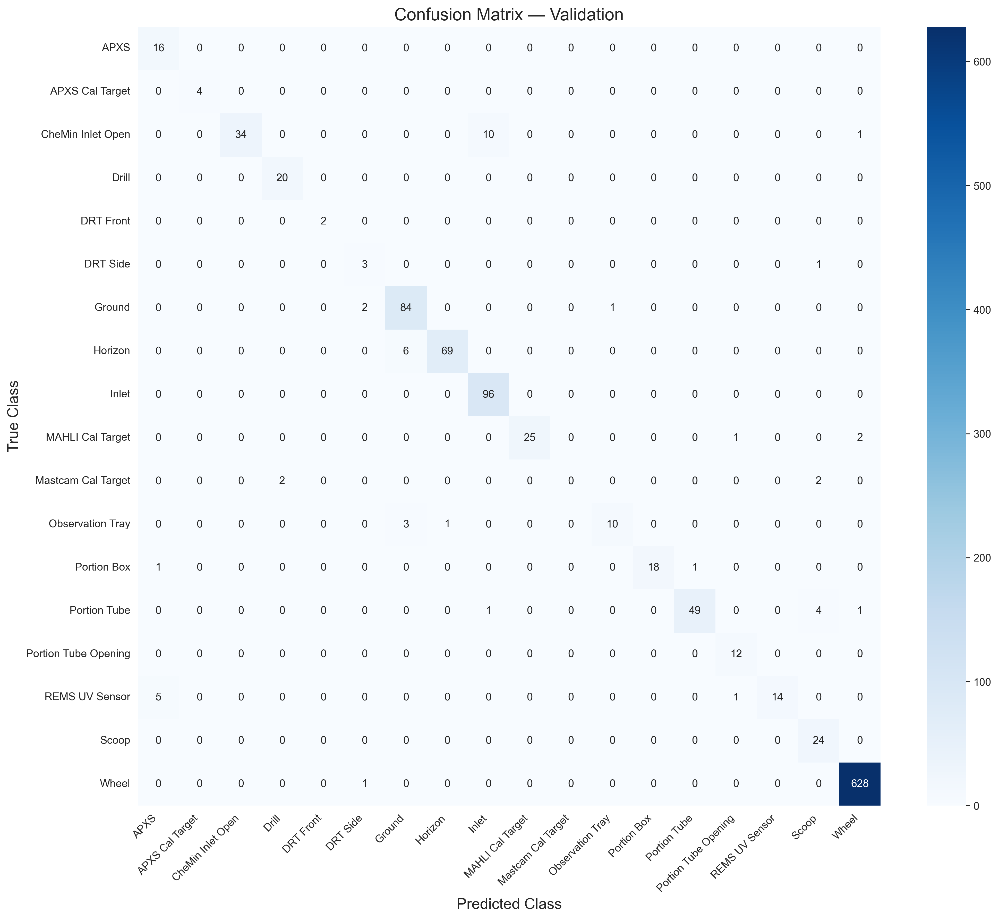

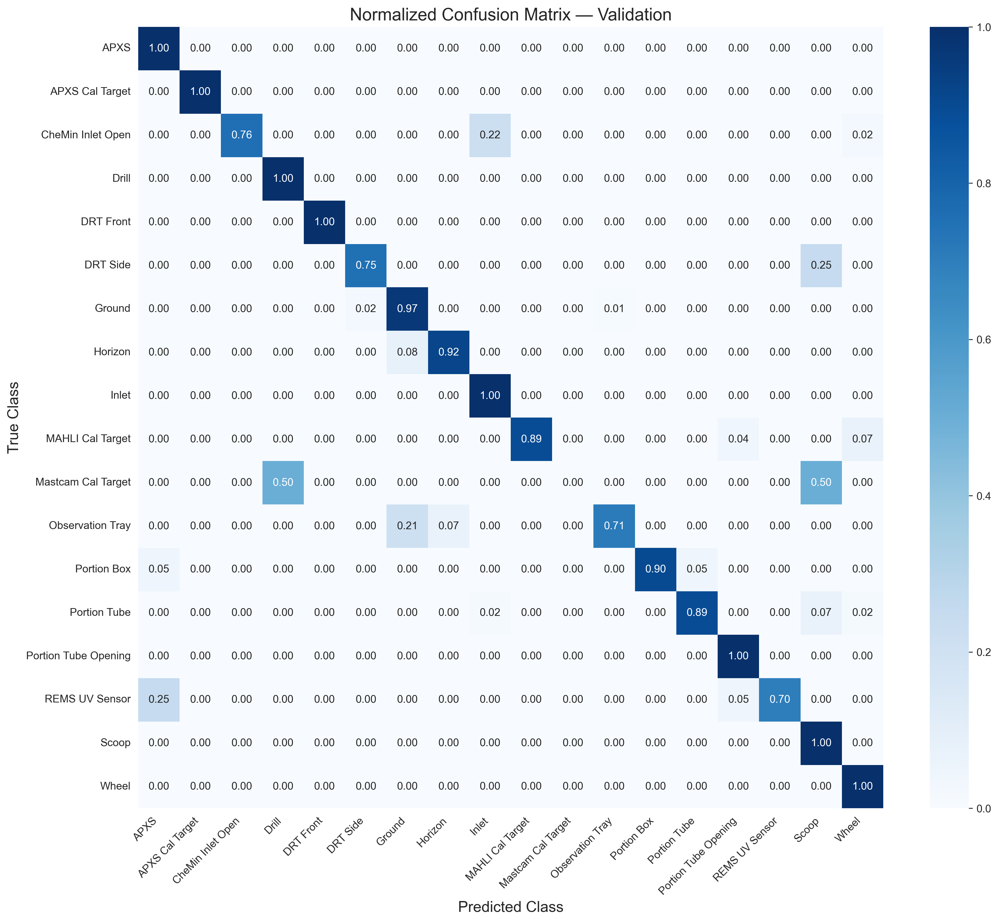

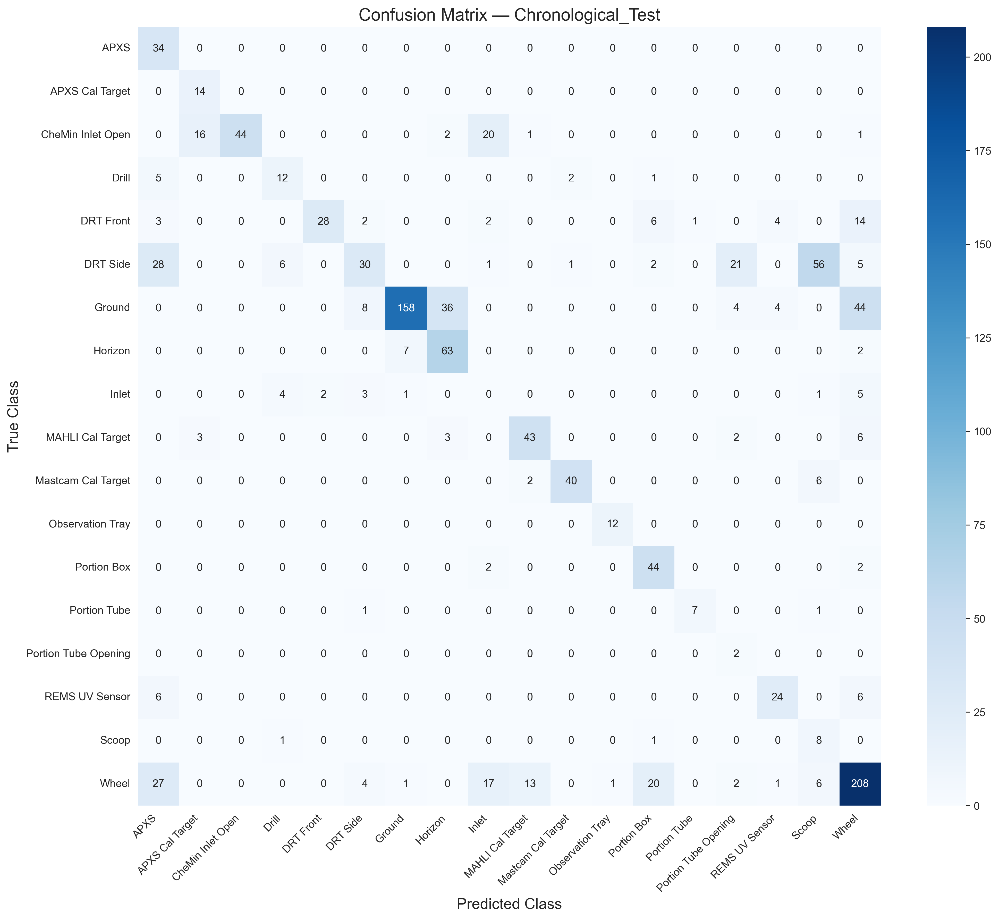

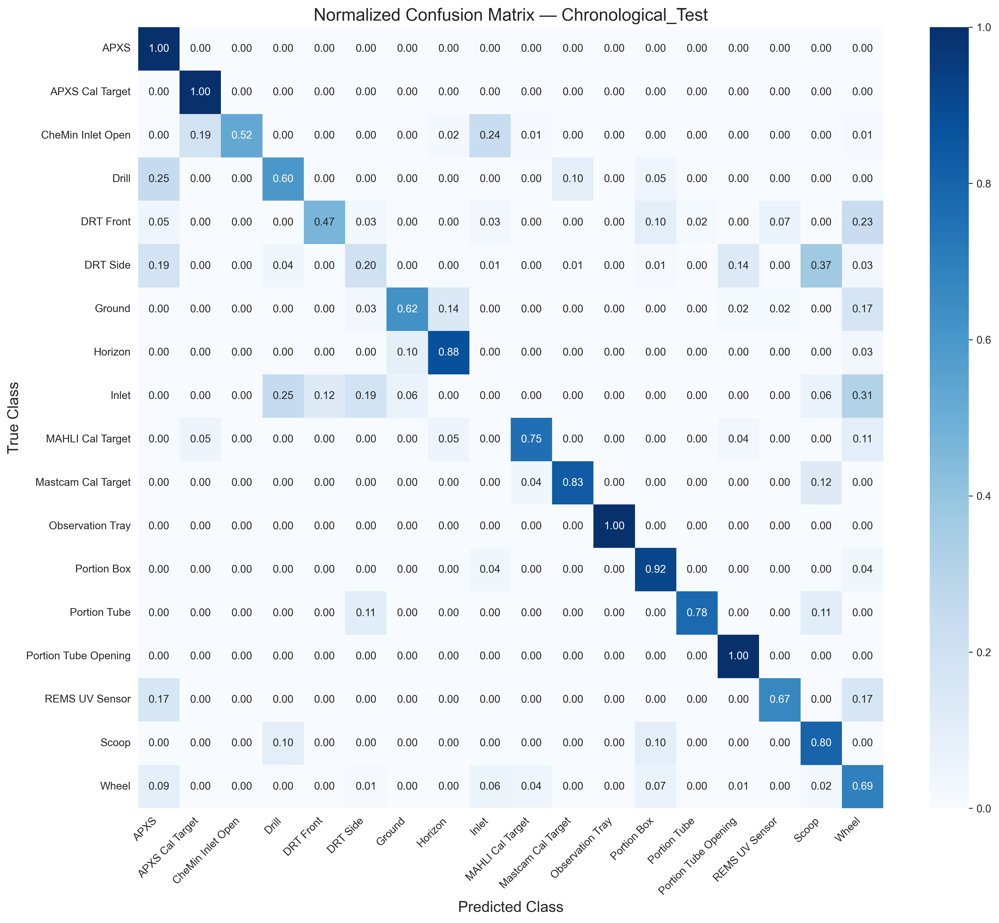

In [5]:
# ============================================================
# CONFUSION MATRICES
# ============================================================

def save_confusion_matrices(
    y_true,
    y_pred,
    split_name,
    prefix="Main_seed42"
):

    labels = np.arange(len(TRAIN_LABELS))

    class_names = [
        CLASS_MAPPING[x]
        for x in TRAIN_LABELS
    ]

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=labels
    )

    # --------------------------------------------------------
    # Raw count confusion matrix
    # --------------------------------------------------------

    plt.figure(
        figsize=(14, 12),
        dpi=300
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted Class", fontsize=14)
    plt.ylabel("True Class", fontsize=14)

    plt.title(
        f"Confusion Matrix — {split_name}",
        fontsize=16
    )

    plt.xticks(
        rotation=45,
        ha="right",
        fontsize=10
    )

    plt.yticks(
        rotation=0,
        fontsize=10
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIG_DIR,
            f"{prefix}_{split_name}_ConfusionMatrix_Counts.png"
        ),
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

    # --------------------------------------------------------
    # Normalized confusion matrix
    # --------------------------------------------------------

    cm_norm = cm.astype(float) / np.maximum(
        cm.sum(axis=1, keepdims=True),
        1
    )

    plt.figure(
        figsize=(14, 12),
        dpi=300
    )

    sns.heatmap(
        cm_norm,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        vmin=0,
        vmax=1
    )

    plt.xlabel("Predicted Class", fontsize=14)
    plt.ylabel("True Class", fontsize=14)

    plt.title(
        f"Normalized Confusion Matrix — {split_name}",
        fontsize=16
    )

    plt.xticks(
        rotation=45,
        ha="right",
        fontsize=10
    )

    plt.yticks(
        rotation=0,
        fontsize=10
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIG_DIR,
            f"{prefix}_{split_name}_ConfusionMatrix_Normalized.png"
        ),
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

    # Save matrices
    pd.DataFrame(
        cm,
        index=class_names,
        columns=class_names
    ).to_csv(
        os.path.join(
            TABLE_DIR,
            f"{prefix}_{split_name}_ConfusionMatrix_Counts.csv"
        )
    )

    pd.DataFrame(
        cm_norm,
        index=class_names,
        columns=class_names
    ).to_csv(
        os.path.join(
            TABLE_DIR,
            f"{prefix}_{split_name}_ConfusionMatrix_Normalized.csv"
        )
    )

    return cm, cm_norm


val_cm, val_cm_norm = save_confusion_matrices(
    val_true,
    val_pred,
    "Validation"
)

test_cm, test_cm_norm = save_confusion_matrices(
    test_true,
    test_pred,
    "Chronological_Test"
)

In [6]:
# ============================================================
# VALIDATION vs CHRONOLOGICAL TEST
# PER-CLASS COMPARISON
# ============================================================

val_cmp = val_per_class.copy()
test_cmp = test_per_class.copy()

val_cmp = val_cmp.rename(
    columns={
        "precision": "Val_Precision",
        "recall": "Val_Recall",
        "f1-score": "Val_F1",
        "support": "Val_Support",
        "ROC_AUC_OVR": "Val_ROC_AUC"
    }
)

test_cmp = test_cmp.rename(
    columns={
        "precision": "Test_Precision",
        "recall": "Test_Recall",
        "f1-score": "Test_F1",
        "support": "Test_Support",
        "ROC_AUC_OVR": "Test_ROC_AUC"
    }
)

comparison = pd.merge(
    val_cmp,
    test_cmp,
    on=["LABELS", "Class_Name"],
    how="outer"
)

comparison["Recall_Delta"] = (
    comparison["Test_Recall"]
    - comparison["Val_Recall"]
)

comparison["F1_Delta"] = (
    comparison["Test_F1"]
    - comparison["Val_F1"]
)

comparison["Precision_Delta"] = (
    comparison["Test_Precision"]
    - comparison["Val_Precision"]
)

comparison["AUC_Delta"] = (
    comparison["Test_ROC_AUC"]
    - comparison["Val_ROC_AUC"]
)

comparison["Absolute_F1_Drop"] = (
    comparison["Val_F1"]
    - comparison["Test_F1"]
)

comparison.to_csv(
    os.path.join(
        TABLE_DIR,
        "Validation_vs_ChronologicalTest_PerClass.csv"
    ),
    index=False
)

print("\nPer-class validation/test comparison:")
display(
    comparison.style.format({
        "Val_Precision": "{:.3f}",
        "Val_Recall": "{:.3f}",
        "Val_F1": "{:.3f}",
        "Test_Precision": "{:.3f}",
        "Test_Recall": "{:.3f}",
        "Test_F1": "{:.3f}",
        "Recall_Delta": "{:.3f}",
        "F1_Delta": "{:.3f}",
        "Precision_Delta": "{:.3f}",
        "Val_ROC_AUC": "{:.3f}",
        "Test_ROC_AUC": "{:.3f}",
        "AUC_Delta": "{:.3f}"
    })
)


Per-class validation/test comparison:


,LABELS,Class_Name,Val_Precision,Val_Recall,Val_F1,Val_Support,Val_ROC_AUC,Reliability_Note_x,Test_Precision,Test_Recall,Test_F1,Test_Support,Test_ROC_AUC,Reliability_Note_y,Recall_Delta,F1_Delta,Precision_Delta,AUC_Delta,Absolute_F1_Drop
0,0,APXS,0.727,1.000,0.842,16,1.000,Small support; interpret point estimate cautiously.,0.330,1.000,0.496,34,1.000,Support >= 20.,0.000,-0.346,-0.397,0.000,0.345755
1,1,APXS Cal Target,1.000,1.000,1.000,4,1.000,Small support; interpret point estimate cautiously.,0.424,1.000,0.596,14,1.000,Small support; interpret point estimate cautiously.,0.000,-0.404,-0.576,0.000,0.404255
2,3,CheMin Inlet Open,1.000,0.756,0.861,45,0.996,Support >= 20.,1.000,0.524,0.688,84,0.978,Support >= 20.,-0.232,-0.173,0.000,-0.018,0.173259
3,4,Drill,0.909,1.000,0.952,20,1.000,Support >= 20.,0.522,0.600,0.558,20,0.946,Support >= 20.,-0.400,-0.394,-0.387,-0.054,0.394241
4,6,DRT Front,1.000,1.000,1.000,2,1.000,Small support; interpret point estimate cautiously.,0.933,0.467,0.622,60,0.990,Support >= 20.,-0.533,-0.378,-0.067,-0.010,0.377778
5,7,DRT Side,0.500,0.750,0.600,4,0.998,Small support; interpret point estimate cautiously.,0.625,0.200,0.303,150,0.888,Support >= 20.,-0.550,-0.297,0.125,-0.110,0.296970
6,8,Ground,0.903,0.966,0.933,87,0.998,Support >= 20.,0.946,0.622,0.751,254,0.969,Support >= 20.,-0.343,-0.183,0.043,-0.029,0.182740
7,9,Horizon,0.986,0.920,0.952,75,1.000,Support >= 20.,0.606,0.875,0.716,72,0.989,Support >= 20.,-0.045,-0.236,-0.380,-0.011,0.235815
8,10,Inlet,0.897,1.000,0.946,96,1.000,Support >= 20.,0.000,0.000,0.000,16,0.633,Small support; interpret point estimate cautiously.,-1.000,-0.946,-0.897,-0.367,0.945813
9,12,MAHLI Cal Target,1.000,0.893,0.943,28,0.999,Support >= 20.,0.729,0.754,0.741,57,0.967,Support >= 20.,-0.138,-0.202,-0.271,-0.032,0.202017


In [7]:
# ============================================================
# CLASS SUPPORT — VALIDATION / TEST
# ============================================================

support_table = comparison[
    [
        "LABELS",
        "Class_Name",
        "Val_Support",
        "Test_Support"
    ]
].copy()

support_table["Val_Percentage"] = (
    support_table["Val_Support"]
    / support_table["Val_Support"].sum()
    * 100
)

support_table["Test_Percentage"] = (
    support_table["Test_Support"]
    / support_table["Test_Support"].sum()
    * 100
)

support_table["Distribution_Shift_pp"] = (
    support_table["Test_Percentage"]
    - support_table["Val_Percentage"]
)

support_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "Validation_Test_Class_Distribution.csv"
    ),
    index=False
)

display(
    support_table.style.format({
        "Val_Percentage": "{:.2f}",
        "Test_Percentage": "{:.2f}",
        "Distribution_Shift_pp": "{:.2f}"
    })
)

,LABELS,Class_Name,Val_Support,Test_Support,Val_Percentage,Test_Percentage,Distribution_Shift_pp
0,0,APXS,16,34,1.39,2.77,1.39
1,1,APXS Cal Target,4,14,0.35,1.14,0.80
2,3,CheMin Inlet Open,45,84,3.90,6.85,2.96
3,4,Drill,20,20,1.73,1.63,-0.10
4,6,DRT Front,2,60,0.17,4.89,4.72
5,7,DRT Side,4,150,0.35,12.23,11.89
6,8,Ground,87,254,7.53,20.72,13.19
7,9,Horizon,75,72,6.49,5.87,-0.62
8,10,Inlet,96,16,8.31,1.31,-7.01
9,12,MAHLI Cal Target,28,57,2.42,4.65,2.23


In [8]:
# ============================================================
# OVERSAMPLING AMPLIFICATION FACTOR
# ============================================================

original_counts = (
    train_df["LABELS"]
    .value_counts()
    .reindex(TRAIN_LABELS)
    .fillna(0)
    .astype(int)
)

majority_count = original_counts.max()

oversampling_table = pd.DataFrame({
    "LABELS": TRAIN_LABELS,
    "Class_Name": [
        CLASS_MAPPING[x]
        for x in TRAIN_LABELS
    ],
    "Original_Train_N": [
        original_counts[x]
        for x in TRAIN_LABELS
    ]
})

oversampling_table["Target_N_After_Oversampling"] = (
    majority_count
)

oversampling_table["Amplification_Factor"] = (
    oversampling_table["Target_N_After_Oversampling"]
    / oversampling_table["Original_Train_N"].replace(0, np.nan)
)

oversampling_table["Additional_Copies"] = (
    oversampling_table["Target_N_After_Oversampling"]
    - oversampling_table["Original_Train_N"]
)

oversampling_table.to_csv(
    os.path.join(
        TABLE_DIR,
        "Oversampling_Amplification_Factors.csv"
    ),
    index=False
)

display(
    oversampling_table.style.format({
        "Amplification_Factor": "{:.2f}"
    })
)

,LABELS,Class_Name,Original_Train_N,Target_N_After_Oversampling,Amplification_Factor,Additional_Copies
0,0,APXS,30,2343,78.10,2313
1,1,APXS Cal Target,6,2343,390.50,2337
2,3,CheMin Inlet Open,47,2343,49.85,2296
3,4,Drill,19,2343,123.32,2324
4,6,DRT Front,4,2343,585.75,2339
5,7,DRT Side,8,2343,292.88,2335
6,8,Ground,2343,2343,1.00,0
7,9,Horizon,224,2343,10.46,2119
8,10,Inlet,165,2343,14.20,2178
9,12,MAHLI Cal Target,32,2343,73.22,2311


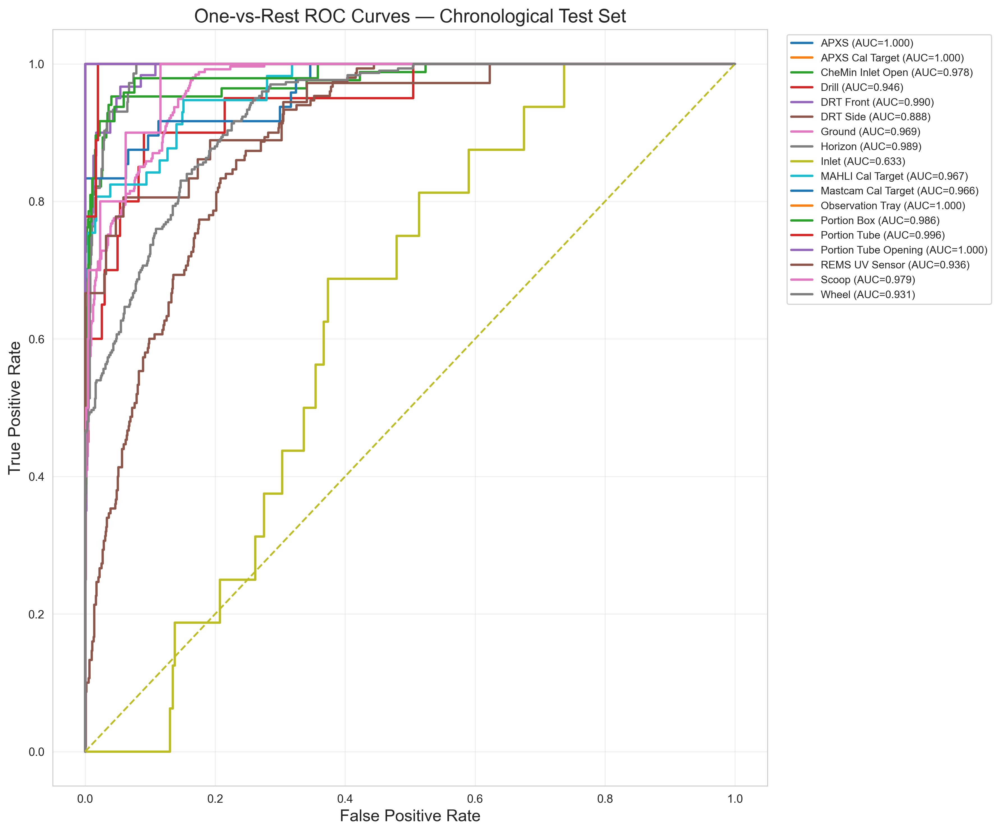

In [9]:
# ============================================================
# ROC CURVES — CHRONOLOGICAL TEST
# ============================================================

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

y_test_bin = label_binarize(
    test_true,
    classes=np.arange(len(TRAIN_LABELS))
)

plt.figure(
    figsize=(12, 10),
    dpi=300
)

auc_values = []

for i, label in enumerate(TRAIN_LABELS):

    # AUC requires both positive and negative examples
    if (
        len(np.unique(y_test_bin[:, i])) < 2
    ):
        continue

    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        test_probs[:, i]
    )

    class_auc = auc(fpr, tpr)

    auc_values.append(class_auc)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{CLASS_MAPPING[label]} (AUC={class_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5
)

plt.xlabel(
    "False Positive Rate",
    fontsize=14
)

plt.ylabel(
    "True Positive Rate",
    fontsize=14
)

plt.title(
    "One-vs-Rest ROC Curves — Chronological Test Set",
    fontsize=16
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "Chronological_Test_ROC_Curves.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

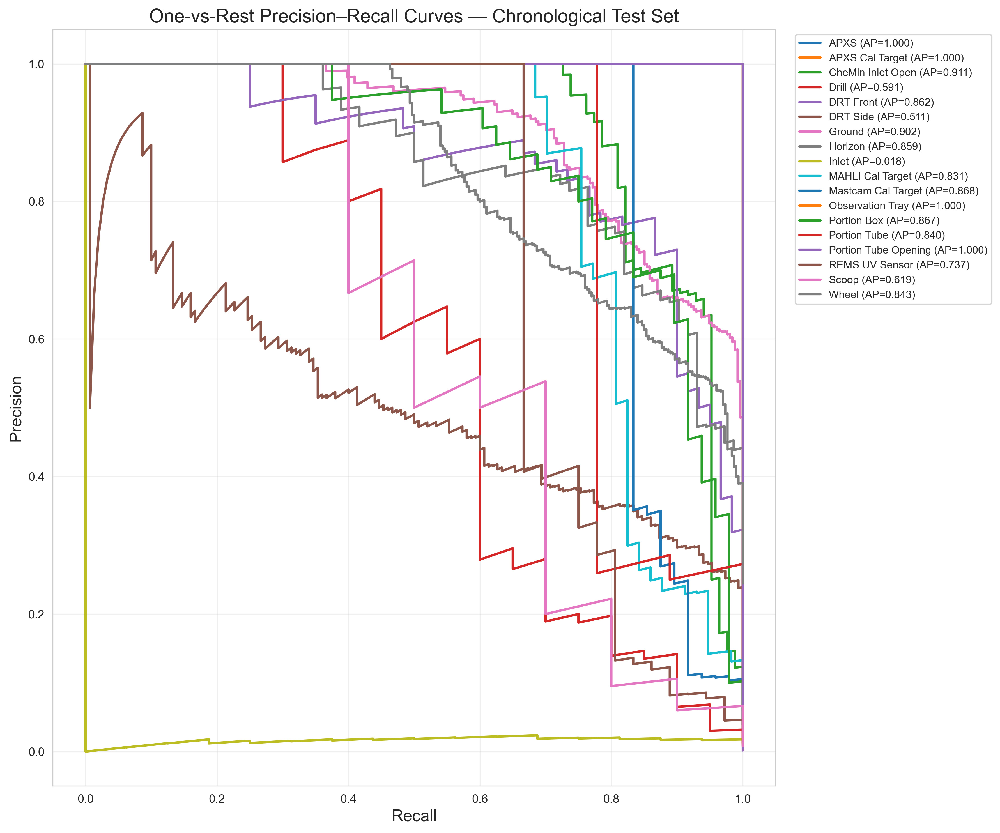

In [10]:
# ============================================================
# PRECISION-RECALL CURVES — CHRONOLOGICAL TEST
# ============================================================

from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(
    figsize=(12, 10),
    dpi=300
)

ap_values = []

for i, label in enumerate(TRAIN_LABELS):

    if len(np.unique(y_test_bin[:, i])) < 2:
        continue

    precision, recall, _ = precision_recall_curve(
        y_test_bin[:, i],
        test_probs[:, i]
    )

    ap = average_precision_score(
        y_test_bin[:, i],
        test_probs[:, i]
    )

    ap_values.append(ap)

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{CLASS_MAPPING[label]} (AP={ap:.3f})"
    )

plt.xlabel(
    "Recall",
    fontsize=14
)

plt.ylabel(
    "Precision",
    fontsize=14
)

plt.title(
    "One-vs-Rest Precision–Recall Curves — Chronological Test Set",
    fontsize=16
)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIG_DIR,
        "Chronological_Test_Precision_Recall_Curves.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [11]:
# ============================================================
# FINAL MAIN MODEL RESULTS
# ============================================================

final_results = pd.DataFrame([
    val_metrics,
    test_metrics
])

final_results.to_excel(
    os.path.join(
        REPORT_DIR,
        "FINAL_Main_Model_Results.xlsx"
    ),
    index=False
)

print("\n" + "=" * 100)
print("MAIN MODEL EVALUATION COMPLETED")
print("=" * 100)

print("\nValidation:")
print(
    f"Accuracy = {val_metrics['Accuracy']:.4f} | "
    f"Macro-F1 = {val_metrics['Macro_F1']:.4f} | "
    f"Balanced Acc = {val_metrics['Balanced_Accuracy']:.4f} | "
    f"Top-3 = {val_metrics['Top3_Accuracy']:.4f}"
)

print("\nChronological Test:")
print(
    f"Accuracy = {test_metrics['Accuracy']:.4f} | "
    f"Macro-F1 = {test_metrics['Macro_F1']:.4f} | "
    f"Balanced Acc = {test_metrics['Balanced_Accuracy']:.4f} | "
    f"Top-3 = {test_metrics['Top3_Accuracy']:.4f}"
)

print("\nOutput directory:")
print(OUTPUT_DIR)


MAIN MODEL EVALUATION COMPLETED

Validation:
Accuracy = 0.9593 | Macro-F1 = 0.8514 | Balanced Acc = 0.8604 | Top-3 = 0.9861

Chronological Test:
Accuracy = 0.6289 | Macro-F1 = 0.5864 | Balanced Acc = 0.7072 | Top-3 = 0.8434

Output directory:
E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports


In [ ]:
# ============================================================
# PLOS ONE REVIEWER EXPERIMENTS
# ABLATION STUDY + REPEATED-SEED ROBUSTNESS ANALYSIS
# ============================================================
#
# PURPOSE
# -------
# 1. Ablation:
#       CE only
#       Oversampling only
#       Class weighting only
#       Focal only
#       Full model
#
# 2. Repeated seeds:
#       Full model with seeds:
#       11, 22, 33, 44, 55
#
# IMPORTANT FIX
# --------------
# Keras flow_from_dataframe(..., class_mode="categorical")
# requires categorical labels to be strings/lists/tuples.
#
# Therefore:
#       _class_index  -> integer, used for sklearn
#       _keras_class  -> string, used by Keras generator
#
# ============================================================

import os
import gc
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger
)
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score
)

warnings.filterwarnings("ignore")

# ============================================================
# 0. CONFIGURATION
# ============================================================

EXPERIMENT_ROOT = Path(
    r"E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports\PLOS_ONE_REVIEWER_EXPERIMENTS"
)

ABLATION_ROOT = EXPERIMENT_ROOT / "ABLATION"
SEEDS_ROOT = EXPERIMENT_ROOT / "REPEATED_SEEDS"

ABLATION_ROOT.mkdir(parents=True, exist_ok=True)
SEEDS_ROOT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Model/data configuration
# ------------------------------------------------------------

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

N_CLASSES = 18

SELECTED_LABELS_FIXED = [
    "0", "1", "3", "4", "6", "7", "8",
    "9", "10", "12", "14", "15", "16",
    "17", "18", "19", "21", "24"
]

CLASS_NAMES_FIXED = [
    "APXS",
    "APXS Cal Target",
    "CheMin Inlet Open",
    "Drill",
    "DRT Front",
    "DRT Side",
    "Ground",
    "Horizon",
    "Inlet",
    "MAHLI Cal Target",
    "Mastcam Cal Target",
    "Observation Tray",
    "Portion Box",
    "Portion Tube",
    "Portion Tube Opening",
    "REMS UV Sensor",
    "Scoop",
    "Wheel"
]

assert len(SELECTED_LABELS_FIXED) == N_CLASSES
assert len(CLASS_NAMES_FIXED) == N_CLASSES

CLASS_TO_INDEX = {
    label: idx
    for idx, label in enumerate(SELECTED_LABELS_FIXED)
}

INDEX_TO_CLASS = {
    idx: name
    for idx, name in enumerate(CLASS_NAMES_FIXED)
}

PATH_COL = "full_path"
LABEL_COL = "LABELS"
CLASS_COL = "CLASS_NAME"

# ------------------------------------------------------------
# Training schedule
# ------------------------------------------------------------

STAGE1_EPOCHS = 30
STAGE2_EPOCHS = 20

INITIAL_LR = 5e-5
FINETUNE_LR = 1e-5
MIN_LR = 1e-7

EARLY_STOP_PATIENCE = 7
LR_PATIENCE = 3

DROPOUT_RATE = 0.50
DENSE_UNITS = 512

FOCAL_ALPHA = 0.25
FOCAL_GAMMA = 2.0

# ------------------------------------------------------------
# Repeated seeds
# ------------------------------------------------------------

REPEATED_SEEDS = [11, 22, 33, 44, 55]

# ============================================================
# 1. REPRODUCIBILITY UTILITIES
# ============================================================

def set_global_seed(seed):
    """
    Set Python, NumPy and TensorFlow seeds.
    TensorFlow deterministic operations are requested where supported.
    """
    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    try:
        tf.keras.utils.set_random_seed(seed)
    except Exception:
        pass

    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass


print("=" * 100)
print("ABLATION + REPEATED-SEED EXPERIMENTS")
print("=" * 100)

print("TensorFlow:", tf.__version__)
print("Num GPUs:", len(tf.config.list_physical_devices("GPU")))
print("Experiment root:", EXPERIMENT_ROOT)
print("=" * 100)


# ============================================================
# 2. DATAFRAME VALIDATION
# ============================================================

required_columns = [
    PATH_COL,
    LABEL_COL
]

for df_name, df in [
    ("train_df", train_df),
    ("val_df", val_df),
    ("test_df", test_df)
]:

    missing = [c for c in required_columns if c not in df.columns]

    if missing:
        raise ValueError(
            f"{df_name} is missing required columns: {missing}"
        )

    if len(df) == 0:
        raise ValueError(f"{df_name} is empty.")

print("\nDATAFRAME CHECK")
print("-" * 100)

print(f"Train: {len(train_df):,}")
print(f"Validation: {len(val_df):,}")
print(f"Test: {len(test_df):,}")


# ============================================================
# 3. STANDARDIZE CLASS INDEX
# ============================================================

def prepare_dataframe(df, dataframe_name="dataframe"):
    """
    Creates:
        _class_index : integer class index [0 ... 17]
        _keras_class : string class index for Keras categorical generator

    Existing class information is preserved.
    """

    df = df.copy()

    # --------------------------------------------------------
    # Determine label representation
    # --------------------------------------------------------

    def convert_to_fixed_index(value):

        # Already integer-like
        if isinstance(value, (int, np.integer)):
            value_int = int(value)

            if value_int in [int(x) for x in SELECTED_LABELS_FIXED]:
                return CLASS_TO_INDEX[str(value_int)]

            if 0 <= value_int < N_CLASSES:
                return value_int

        # Numeric float
        try:
            value_str = str(value).strip()

            if value_str.endswith(".0"):
                value_str = value_str[:-2]

            if value_str in CLASS_TO_INDEX:
                return CLASS_TO_INDEX[value_str]

            # If already an internal index
            if value_str.isdigit():
                value_int = int(value_str)

                if 0 <= value_int < N_CLASSES:
                    return value_int

        except Exception:
            pass

        # Class name
        if str(value) in CLASS_NAMES_FIXED:
            return CLASS_NAMES_FIXED.index(str(value))

        raise ValueError(
            f"Unknown class value in {dataframe_name}: {value}"
        )

    df["_class_index"] = df[LABEL_COL].apply(convert_to_fixed_index)

    # --------------------------------------------------------
    # Keras categorical labels MUST be strings
    # --------------------------------------------------------

    df["_keras_class"] = df["_class_index"].astype(str)

    # --------------------------------------------------------
    # Validate
    # --------------------------------------------------------

    invalid = sorted(
        set(df["_class_index"].unique()) - set(range(N_CLASSES))
    )

    if invalid:
        raise ValueError(
            f"{dataframe_name}: invalid class indices detected: {invalid}"
        )

    return df


train_base = prepare_dataframe(train_df, "train_df")
val_base = prepare_dataframe(val_df, "val_df")
test_base = prepare_dataframe(test_df, "test_df")


print("\nCLASS INDEX CHECK")
print("-" * 100)

for name, df in [
    ("Train", train_base),
    ("Validation", val_base),
    ("Test", test_base)
]:

    counts = (
        df["_class_index"]
        .value_counts()
        .sort_index()
    )

    print(f"\n{name}")

    for idx in range(N_CLASSES):
        count = int(counts.get(idx, 0))
        print(
            f"{idx:2d} | "
            f"{CLASS_NAMES_FIXED[idx]:25s} | "
            f"{count:6d}"
        )


# ============================================================
# 4. DATA AUGMENTATION
# ============================================================

TRAIN_DATAGEN = ImageDataGenerator(
    rescale=1.0 / 255.0,

    rotation_range=30,
    width_shift_range=0.20,
    height_shift_range=0.20,
    shear_range=15,
    zoom_range=0.25,

    horizontal_flip=True,

    brightness_range=(0.9, 1.1),

    fill_mode="nearest"
)

VAL_DATAGEN = ImageDataGenerator(
    rescale=1.0 / 255.0
)


# ============================================================
# 5. CRITICAL FIXED GENERATOR FUNCTION
# ============================================================

def create_train_generator(
    dataframe,
    seed=42,
    shuffle=True
):
    """
    Keras training generator.

    IMPORTANT:
    _keras_class is a STRING.
    _class_index remains INTEGER for sklearn evaluation.
    """

    df = dataframe.copy()

    # Ensure Keras-compatible categorical labels
    df["_keras_class"] = (
        df["_class_index"]
        .astype(int)
        .astype(str)
    )

    generator = TRAIN_DATAGEN.flow_from_dataframe(
        dataframe=df,

        x_col=PATH_COL,

        y_col="_keras_class",

        target_size=IMG_SIZE,

        batch_size=BATCH_SIZE,

        class_mode="categorical",

        classes=[str(i) for i in range(N_CLASSES)],

        shuffle=shuffle,

        seed=seed,

        validate_filenames=True
    )

    return generator


def create_eval_generator(
    dataframe,
    shuffle=False
):
    """
    Evaluation generator.
    Uses only deterministic rescaling.
    """

    df = dataframe.copy()

    df["_keras_class"] = (
        df["_class_index"]
        .astype(int)
        .astype(str)
    )

    generator = VAL_DATAGEN.flow_from_dataframe(
        dataframe=df,

        x_col=PATH_COL,

        y_col="_keras_class",

        target_size=IMG_SIZE,

        batch_size=BATCH_SIZE,

        class_mode="categorical",

        classes=[str(i) for i in range(N_CLASSES)],

        shuffle=shuffle,

        validate_filenames=True
    )

    return generator


# ============================================================
# 6. GENERATOR SMOKE TEST
# ============================================================

print("\n" + "=" * 100)
print("GENERATOR SMOKE TEST")
print("=" * 100)

smoke_gen = create_train_generator(
    train_base,
    seed=123,
    shuffle=True
)

print("Generator class_indices:")
print(smoke_gen.class_indices)

expected_class_indices = {
    str(i): i
    for i in range(N_CLASSES)
}

if smoke_gen.class_indices != expected_class_indices:
    raise RuntimeError(
        "\nKeras class mapping mismatch!\n"
        f"Expected: {expected_class_indices}\n"
        f"Received: {smoke_gen.class_indices}"
    )

x_batch, y_batch = next(smoke_gen)

print("\nBatch X shape:", x_batch.shape)
print("Batch Y shape:", y_batch.shape)
print("X dtype:", x_batch.dtype)
print("Y dtype:", y_batch.dtype)
print("X min:", float(np.min(x_batch)))
print("X max:", float(np.max(x_batch)))

if x_batch.shape[1:] != (
    IMG_SIZE[0],
    IMG_SIZE[1],
    3
):
    raise RuntimeError(
        f"Unexpected image shape: {x_batch.shape}"
    )

if y_batch.shape[1] != N_CLASSES:
    raise RuntimeError(
        f"Unexpected number of classes: {y_batch.shape}"
    )

print("\nGenerator smoke test PASSED.")

del smoke_gen
del x_batch
del y_batch
gc.collect()


# ============================================================
# 7. OVERSAMPLING
# ============================================================

def oversample_training_dataframe(
    dataframe,
    seed=42
):
    """
    Random oversampling of the original training dataframe.

    Each class is sampled with replacement until it reaches
    the size of the majority class.

    The original dataframe is never modified.
    """

    rng = np.random.RandomState(seed)

    parts = []

    class_counts = (
        dataframe["_class_index"]
        .value_counts()
        .sort_index()
    )

    majority_count = int(class_counts.max())

    for class_idx in range(N_CLASSES):

        class_df = dataframe[
            dataframe["_class_index"] == class_idx
        ].copy()

        if len(class_df) == 0:
            raise ValueError(
                f"Training dataframe contains zero samples "
                f"for class {class_idx} "
                f"({CLASS_NAMES_FIXED[class_idx]})."
            )

        n_samples = len(class_df)

        if n_samples < majority_count:

            extra_indices = rng.choice(
                class_df.index.to_numpy(),
                size=majority_count - n_samples,
                replace=True
            )

            extra_df = class_df.loc[extra_indices].copy()

            class_df = pd.concat(
                [class_df, extra_df],
                axis=0
            )

        elif n_samples > majority_count:

            # Should never happen because majority_count is max.
            class_df = class_df.sample(
                n=majority_count,
                random_state=seed
            )

        parts.append(class_df)

    result = pd.concat(
        parts,
        axis=0,
        ignore_index=True
    )

    # Shuffle after oversampling
    result = result.sample(
        frac=1.0,
        random_state=seed
    ).reset_index(drop=True)

    # Recreate Keras label
    result["_keras_class"] = (
        result["_class_index"]
        .astype(int)
        .astype(str)
    )

    return result


# ============================================================
# 8. CLASS WEIGHTS
# ============================================================

def compute_class_weights_from_original_training(
    dataframe
):
    """
    Class weights are calculated ONLY from the original
    training distribution, not the oversampled distribution.
    """

    counts = (
        dataframe["_class_index"]
        .value_counts()
        .sort_index()
    )

    total = len(dataframe)

    weights = {}

    for class_idx in range(N_CLASSES):

        count = int(counts.get(class_idx, 0))

        if count == 0:
            raise ValueError(
                f"Cannot calculate class weight for class "
                f"{class_idx}: zero samples."
            )

        weights[class_idx] = (
            total /
            (N_CLASSES * count)
        )

    return weights


ORIGINAL_CLASS_WEIGHTS = (
    compute_class_weights_from_original_training(
        train_base
    )
)

print("\nORIGINAL TRAINING CLASS WEIGHTS")
print("-" * 100)

for idx in range(N_CLASSES):

    print(
        f"{idx:2d} | "
        f"{CLASS_NAMES_FIXED[idx]:25s} | "
        f"{ORIGINAL_CLASS_WEIGHTS[idx]:.6f}"
    )


# ============================================================
# 9. FOCAL LOSS
# ============================================================

def categorical_focal_loss(
    alpha=0.25,
    gamma=2.0
):

    def loss(y_true, y_pred):

        y_pred = tf.clip_by_value(
            y_pred,
            tf.keras.backend.epsilon(),
            1.0 - tf.keras.backend.epsilon()
        )

        cross_entropy = (
            -y_true *
            tf.math.log(y_pred)
        )

        focal_factor = tf.pow(
            1.0 - y_pred,
            gamma
        )

        focal_loss = (
            alpha *
            focal_factor *
            cross_entropy
        )

        return tf.reduce_sum(
            focal_loss,
            axis=-1
        )

    return loss


# ============================================================
# 10. MODEL BUILDER
# ============================================================

def build_vgg16_model(
    loss_type="focal"
):

    # --------------------------------------------------------
    # Backbone
    # --------------------------------------------------------

    base_model = tf.keras.applications.VGG16(
        include_top=False,
        weights="imagenet",
        input_shape=(
            IMG_SIZE[0],
            IMG_SIZE[1],
            3
        )
    )

    # Initially freeze backbone
    base_model.trainable = False

    # --------------------------------------------------------
    # Classification head
    # --------------------------------------------------------

    inputs = layers.Input(
        shape=(
            IMG_SIZE[0],
            IMG_SIZE[1],
            3
        ),
        name="input_image"
    )

    x = base_model(
        inputs,
        training=False
    )

    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    x = layers.Dense(
        DENSE_UNITS,
        activation="relu",
        name="dense_512"
    )(x)

    x = layers.BatchNormalization(
        name="batch_normalization"
    )(x)

    x = layers.Dropout(
        DROPOUT_RATE,
        name="dropout"
    )(x)

    outputs = layers.Dense(
        N_CLASSES,
        activation="softmax",
        name="classifier"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name="VGG16_Mars_18Class"
    )

    # --------------------------------------------------------
    # Loss
    # --------------------------------------------------------

    if loss_type == "focal":

        loss_function = categorical_focal_loss(
            alpha=FOCAL_ALPHA,
            gamma=FOCAL_GAMMA
        )

    elif loss_type == "ce":

        loss_function = "categorical_crossentropy"

    else:

        raise ValueError(
            f"Unknown loss type: {loss_type}"
        )

    model.compile(
        optimizer=Adam(
            learning_rate=INITIAL_LR
        ),
        loss=loss_function,
        metrics=[
            "accuracy"
        ]
    )

    return model


# ============================================================
# 11. FINE-TUNING FUNCTION
# ============================================================

def enable_last_8_layers_finetuning(
    model
):
    """
    Unfreezes only the last 8 VGG16 convolutional/backbone layers.

    The classifier head remains trainable.
    """

    base_model = None

    for layer in model.layers:

        if isinstance(
            layer,
            tf.keras.Model
        ) and "vgg16" in layer.name.lower():

            base_model = layer
            break

    if base_model is None:
        raise RuntimeError(
            "VGG16 backbone was not found in the model."
        )

    # Freeze everything first
    for layer in base_model.layers:
        layer.trainable = False

    # Unfreeze last 8 backbone layers
    for layer in base_model.layers[-8:]:
        layer.trainable = True

    # Recompile with fine-tuning LR
    model.compile(
        optimizer=Adam(
            learning_rate=FINETUNE_LR
        ),
        loss=model.loss,
        metrics=[
            "accuracy"
        ]
    )

    return model


# ============================================================
# 12. TRAINING FUNCTION
# ============================================================

def train_two_stage_model(
    train_dataframe,
    val_dataframe,
    experiment_name,
    seed=42,
    use_oversampling=True,
    use_class_weights=True,
    loss_type="focal"
):

    print("\n")
    print("=" * 100)
    print(f"TRAINING: {experiment_name}")
    print("=" * 100)

    print("Seed:", seed)
    print("Loss:", loss_type)
    print("Oversampling:", use_oversampling)
    print("Class weighting:", use_class_weights)

    # --------------------------------------------------------
    # Seed
    # --------------------------------------------------------

    set_global_seed(seed)

    # --------------------------------------------------------
    # Prepare training dataframe
    # --------------------------------------------------------

    original_train = train_dataframe.copy()

    if use_oversampling:

        train_used = oversample_training_dataframe(
            original_train,
            seed=seed
        )

    else:

        train_used = original_train.copy()

        train_used["_keras_class"] = (
            train_used["_class_index"]
            .astype(int)
            .astype(str)
        )

    # --------------------------------------------------------
    # Show training distribution
    # --------------------------------------------------------

    train_counts = (
        train_used["_class_index"]
        .value_counts()
        .sort_index()
    )

    print("\nTraining samples used:", len(train_used))

    if use_oversampling:
        print("Oversampling applied.")
    else:
        print("Original training distribution used.")

    # --------------------------------------------------------
    # Generators
    # --------------------------------------------------------

    train_gen = create_train_generator(
        train_used,
        seed=seed,
        shuffle=True
    )

    val_gen = create_eval_generator(
        val_dataframe,
        shuffle=False
    )

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    model = build_vgg16_model(
        loss_type=loss_type
    )

    # --------------------------------------------------------
    # Experiment directory
    # --------------------------------------------------------

    exp_dir = EXPERIMENT_ROOT / experiment_name

    exp_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    checkpoint_stage1 = (
        exp_dir /
        "stage1_best_val_accuracy.keras"
    )

    checkpoint_stage2 = (
        exp_dir /
        "stage2_best_val_accuracy.keras"
    )

    log_stage1 = (
        exp_dir /
        "stage1_training.csv"
    )

    log_stage2 = (
        exp_dir /
        "stage2_training.csv"
    )

    # --------------------------------------------------------
    # Callbacks Stage 1
    # --------------------------------------------------------

    callbacks_stage1 = [

        ModelCheckpoint(
            filepath=str(checkpoint_stage1),
            monitor="val_accuracy",
            mode="max",
            save_best_only=True,
            save_weights_only=False,
            verbose=1
        ),

        EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=EARLY_STOP_PATIENCE,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            mode="min",
            factor=0.5,
            patience=LR_PATIENCE,
            min_lr=MIN_LR,
            verbose=1
        ),

        CSVLogger(
            str(log_stage1),
            append=False
        )
    ]

    # --------------------------------------------------------
    # Stage 1
    # --------------------------------------------------------

    print("\n")
    print("-" * 100)
    print("STAGE 1 — FROZEN VGG16")
    print("-" * 100)

    history1 = model.fit(
        train_gen,

        validation_data=val_gen,

        epochs=STAGE1_EPOCHS,

        class_weight=(
            ORIGINAL_CLASS_WEIGHTS
            if use_class_weights
            else None
        ),

        callbacks=callbacks_stage1,

        verbose=1
    )

    # --------------------------------------------------------
    # CRITICAL:
    # Reload best Stage-1 val_accuracy checkpoint
    # --------------------------------------------------------

    if not checkpoint_stage1.exists():
        raise FileNotFoundError(
            f"Stage 1 checkpoint not found:\n"
            f"{checkpoint_stage1}"
        )

    model = tf.keras.models.load_model(
        checkpoint_stage1,
        custom_objects={
            "loss": categorical_focal_loss(
                alpha=FOCAL_ALPHA,
                gamma=FOCAL_GAMMA
            )
        } if loss_type == "focal" else None
    )

    print(
        "\nBest Stage-1 checkpoint reloaded:",
        checkpoint_stage1
    )

    # --------------------------------------------------------
    # Stage 2 — Fine tuning
    # --------------------------------------------------------

    model = enable_last_8_layers_finetuning(
        model
    )

    # --------------------------------------------------------
    # Stage 2 callbacks
    # --------------------------------------------------------

    callbacks_stage2 = [

        ModelCheckpoint(
            filepath=str(checkpoint_stage2),
            monitor="val_accuracy",
            mode="max",
            save_best_only=True,
            save_weights_only=False,
            verbose=1
        ),

        EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=EARLY_STOP_PATIENCE,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            mode="min",
            factor=0.5,
            patience=LR_PATIENCE,
            min_lr=MIN_LR,
            verbose=1
        ),

        CSVLogger(
            str(log_stage2),
            append=False
        )
    ]

    print("\n")
    print("-" * 100)
    print("STAGE 2 — FINE-TUNING LAST 8 VGG16 LAYERS")
    print("-" * 100)

    history2 = model.fit(
        train_gen,

        validation_data=val_gen,

        epochs=STAGE2_EPOCHS,

        class_weight=(
            ORIGINAL_CLASS_WEIGHTS
            if use_class_weights
            else None
        ),

        callbacks=callbacks_stage2,

        verbose=1
    )

    # --------------------------------------------------------
    # CRITICAL:
    # Reload best Stage-2 val_accuracy checkpoint
    # --------------------------------------------------------

    if not checkpoint_stage2.exists():
        raise FileNotFoundError(
            f"Stage 2 checkpoint not found:\n"
            f"{checkpoint_stage2}"
        )

    model = tf.keras.models.load_model(
        checkpoint_stage2,
        custom_objects={
            "loss": categorical_focal_loss(
                alpha=FOCAL_ALPHA,
                gamma=FOCAL_GAMMA
            )
        } if loss_type == "focal" else None
    )

    print(
        "\nBest Stage-2 checkpoint reloaded:",
        checkpoint_stage2
    )

    # --------------------------------------------------------
    # Save training metadata
    # --------------------------------------------------------

    metadata = {

        "experiment_name": experiment_name,

        "seed": seed,

        "loss_type": loss_type,

        "focal_alpha": (
            FOCAL_ALPHA
            if loss_type == "focal"
            else None
        ),

        "focal_gamma": (
            FOCAL_GAMMA
            if loss_type == "focal"
            else None
        ),

        "oversampling": use_oversampling,

        "class_weighting": use_class_weights,

        "stage1_epochs_max": STAGE1_EPOCHS,

        "stage2_epochs_max": STAGE2_EPOCHS,

        "initial_lr": INITIAL_LR,

        "finetune_lr": FINETUNE_LR,

        "batch_size": BATCH_SIZE,

        "image_size": list(IMG_SIZE),

        "n_classes": N_CLASSES,

        "best_stage1_checkpoint": str(
            checkpoint_stage1
        ),

        "best_stage2_checkpoint": str(
            checkpoint_stage2
        ),

        "train_original_n": len(original_train),

        "train_used_n": len(train_used),

        "validation_n": len(val_dataframe)
    }

    with open(
        exp_dir / "experiment_metadata.json",
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            metadata,
            f,
            indent=4
        )

    # --------------------------------------------------------
    # Clean memory
    # --------------------------------------------------------

    del train_gen
    del val_gen
    gc.collect()

    return model


# ============================================================
# 13. EVALUATION FUNCTION
# ============================================================

def evaluate_model(
    model,
    dataframe,
    split_name="evaluation"
):

    print("\n")
    print("=" * 100)
    print(f"EVALUATION — {split_name}")
    print("=" * 100)

    generator = create_eval_generator(
        dataframe,
        shuffle=False
    )

    # --------------------------------------------------------
    # Predictions
    # --------------------------------------------------------

    probabilities = model.predict(
        generator,
        verbose=1
    )

    y_prob = np.asarray(
        probabilities
    )

    y_pred = np.argmax(
        y_prob,
        axis=1
    )

    y_true = dataframe[
        "_class_index"
    ].to_numpy(
        dtype=int
    )

    # --------------------------------------------------------
    # Safety check
    # --------------------------------------------------------

    if len(y_true) != len(y_pred):

        raise RuntimeError(
            f"Prediction length mismatch.\n"
            f"y_true={len(y_true)}\n"
            f"y_pred={len(y_pred)}"
        )

    # --------------------------------------------------------
    # Basic metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    # --------------------------------------------------------
    # Top-3 accuracy
    # --------------------------------------------------------

    top3_predictions = np.argsort(
        y_prob,
        axis=1
    )[:, -3:]

    top3_accuracy = np.mean(
        [
            true_label in top3
            for true_label, top3 in zip(
                y_true,
                top3_predictions
            )
        ]
    )

    # --------------------------------------------------------
    # Macro ROC-AUC
    # --------------------------------------------------------

    try:

        y_true_onehot = tf.keras.utils.to_categorical(
            y_true,
            num_classes=N_CLASSES
        )

        macro_auc = roc_auc_score(
            y_true_onehot,
            y_prob,
            average="macro",
            multi_class="ovr"
        )

    except Exception as e:

        print(
            "ROC-AUC could not be calculated:",
            e
        )

        macro_auc = np.nan

    metrics = {

        "Split": split_name,

        "N": len(y_true),

        "Accuracy": accuracy,

        "Top-3 Accuracy": top3_accuracy,

        "Balanced Accuracy": balanced_acc,

        "Macro Precision": precision,

        "Macro Recall": recall,

        "Macro F1": macro_f1,

        "Weighted F1": weighted_f1,

        "Macro ROC-AUC": macro_auc,

        "Cohen Kappa": kappa,

        "MCC": mcc
    }

    print("\nMetrics:")

    for key, value in metrics.items():

        if key in ["Split", "N"]:
            print(f"{key:25s}: {value}")

        else:
            print(
                f"{key:25s}: {value:.6f}"
            )

    # --------------------------------------------------------
    # Per-class metrics
    # --------------------------------------------------------

    precision_pc, recall_pc, f1_pc, support_pc = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=list(range(N_CLASSES)),
            zero_division=0
        )
    )

    per_class = pd.DataFrame({

        "Class_Index":
            list(range(N_CLASSES)),

        "Label":
            SELECTED_LABELS_FIXED,

        "Class_Name":
            CLASS_NAMES_FIXED,

        "Precision":
            precision_pc,

        "Recall":
            recall_pc,

        "F1":
            f1_pc,

        "Support":
            support_pc
    })

    del generator
    gc.collect()

    return metrics, per_class, y_true, y_pred, y_prob


# ============================================================
# 14. IMPORT MISSING METRIC FUNCTION SAFELY
# ============================================================

from sklearn.metrics import (
    precision_recall_fscore_support
)


# ============================================================
# 15. EXPERIMENT DEFINITIONS
# ============================================================

ABLATION_CONFIGS = {

    "CE_only": {

        "loss_type": "ce",

        "use_oversampling": False,

        "use_class_weights": False
    },

    "Oversampling_only": {

        "loss_type": "ce",

        "use_oversampling": True,

        "use_class_weights": False
    },

    "Class_weighting_only": {

        "loss_type": "ce",

        "use_oversampling": False,

        "use_class_weights": True
    },

    "Focal_only": {

        "loss_type": "focal",

        "use_oversampling": False,

        "use_class_weights": False
    },

    "Full_model": {

        "loss_type": "focal",

        "use_oversampling": True,

        "use_class_weights": True
    }
}


# ============================================================
# 16. ABLATION EXPERIMENT
# ============================================================

print("\n")
print("=" * 100)
print("STARTING ABLATION STUDY")
print("=" * 100)

ablation_results = []
ablation_per_class = []

ABLATION_SEED = 42

for config_name, config in ABLATION_CONFIGS.items():

    print("\n")
    print("#" * 100)
    print(f"ABLATION CONFIGURATION: {config_name}")
    print("#" * 100)

    experiment_name = (
        f"ABLATION_{config_name}"
    )

    try:

        # ----------------------------------------------------
        # Train
        # ----------------------------------------------------

        model = train_two_stage_model(

            train_dataframe=train_base,

            val_dataframe=val_base,

            experiment_name=experiment_name,

            seed=ABLATION_SEED,

            use_oversampling=
                config["use_oversampling"],

            use_class_weights=
                config["use_class_weights"],

            loss_type=
                config["loss_type"]
        )

        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        val_metrics, val_pc, _, _, _ = (
            evaluate_model(
                model,
                val_base,
                split_name="Validation"
            )
        )

        # ----------------------------------------------------
        # Chronological test
        # ----------------------------------------------------

        test_metrics, test_pc, _, _, _ = (
            evaluate_model(
                model,
                test_base,
                split_name="Chronological Test"
            )
        )

        # ----------------------------------------------------
        # Combine metrics
        # ----------------------------------------------------

        row = {

            "Configuration":
                config_name,

            "Seed":
                ABLATION_SEED,

            "Loss":
                config["loss_type"],

            "Oversampling":
                config["use_oversampling"],

            "Class Weighting":
                config["use_class_weights"]
        }

        for key, value in val_metrics.items():

            if key not in [
                "Split",
                "N"
            ]:

                row[
                    f"Validation_{key}"
                ] = value

        for key, value in test_metrics.items():

            if key not in [
                "Split",
                "N"
            ]:

                row[
                    f"Test_{key}"
                ] = value

        row["Validation_N"] = val_metrics["N"]
        row["Test_N"] = test_metrics["N"]

        ablation_results.append(row)

        # ----------------------------------------------------
        # Per-class
        # ----------------------------------------------------

        val_pc = val_pc.copy()
        test_pc = test_pc.copy()

        val_pc["Configuration"] = config_name
        val_pc["Seed"] = ABLATION_SEED
        val_pc["Split"] = "Validation"

        test_pc["Configuration"] = config_name
        test_pc["Seed"] = ABLATION_SEED
        test_pc["Split"] = "Chronological Test"

        ablation_per_class.append(
            val_pc
        )

        ablation_per_class.append(
            test_pc
        )

        # ----------------------------------------------------
        # Save immediately
        # ----------------------------------------------------

        pd.DataFrame(
            ablation_results
        ).to_csv(
            ABLATION_ROOT /
            "ablation_results_running.csv",
            index=False
        )

        pd.concat(
            ablation_per_class,
            ignore_index=True
        ).to_csv(
            ABLATION_ROOT /
            "ablation_per_class_running.csv",
            index=False
        )

        # ----------------------------------------------------
        # Clear model
        # ----------------------------------------------------

        del model

        tf.keras.backend.clear_session()

        gc.collect()

        print(
            f"\nCompleted: {config_name}"
        )

    except Exception as e:

        print("\n" + "!" * 100)
        print(
            f"FAILED CONFIGURATION: {config_name}"
        )
        print(
            "ERROR:",
            repr(e)
        )
        print("!" * 100)

        # Save failure log
        failure_record = {

            "Configuration":
                config_name,

            "Seed":
                ABLATION_SEED,

            "Error":
                repr(e)
        }

        with open(
            ABLATION_ROOT /
            f"{config_name}_FAILED.txt",
            "w",
            encoding="utf-8"
        ) as f:

            f.write(
                json.dumps(
                    failure_record,
                    indent=4
                )
            )

        tf.keras.backend.clear_session()
        gc.collect()

        # Continue with next configuration
        continue


# ============================================================
# 17. FINAL ABLATION TABLE
# ============================================================

if len(ablation_results) > 0:

    ablation_results_df = pd.DataFrame(
        ablation_results
    )

    ablation_per_class_df = pd.concat(
        ablation_per_class,
        ignore_index=True
    )

    ablation_results_df.to_csv(
        ABLATION_ROOT /
        "ABLATION_FINAL_RESULTS.csv",
        index=False
    )

    ablation_per_class_df.to_csv(
        ABLATION_ROOT /
        "ABLATION_FINAL_PER_CLASS.csv",
        index=False
    )

    print("\n")
    print("=" * 100)
    print("FINAL ABLATION RESULTS")
    print("=" * 100)

    display(
        ablation_results_df.round(6)
    )

else:

    print(
        "\nNo ablation experiment completed."
    )

    ablation_results_df = pd.DataFrame()
    ablation_per_class_df = pd.DataFrame()


# ============================================================
# 18. REPEATED-SEED EXPERIMENT
# ============================================================

print("\n")
print("=" * 100)
print("STARTING REPEATED-SEED ROBUSTNESS EXPERIMENT")
print("=" * 100)

print(
    "Seeds:",
    REPEATED_SEEDS
)

repeated_results = []
repeated_per_class = []

for seed in REPEATED_SEEDS:

    print("\n")
    print("#" * 100)
    print(f"REPEATED FULL MODEL — SEED {seed}")
    print("#" * 100)

    experiment_name = (
        f"REPEATED_SEED_{seed}"
    )

    try:

        # ----------------------------------------------------
        # Full model
        # ----------------------------------------------------

        model = train_two_stage_model(

            train_dataframe=train_base,

            val_dataframe=val_base,

            experiment_name=experiment_name,

            seed=seed,

            use_oversampling=True,

            use_class_weights=True,

            loss_type="focal"
        )

        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        val_metrics, val_pc, _, _, _ = (
            evaluate_model(
                model,
                val_base,
                split_name="Validation"
            )
        )

        # ----------------------------------------------------
        # Chronological test
        # ----------------------------------------------------

        test_metrics, test_pc, _, _, _ = (
            evaluate_model(
                model,
                test_base,
                split_name="Chronological Test"
            )
        )

        # ----------------------------------------------------
        # Main metrics
        # ----------------------------------------------------

        row = {

            "Seed":
                seed,

            "Validation_N":
                val_metrics["N"],

            "Test_N":
                test_metrics["N"]
        }

        for key, value in val_metrics.items():

            if key not in [
                "Split",
                "N"
            ]:

                row[
                    f"Validation_{key}"
                ] = value

        for key, value in test_metrics.items():

            if key not in [
                "Split",
                "N"
            ]:

                row[
                    f"Test_{key}"
                ] = value

        repeated_results.append(
            row
        )

        # ----------------------------------------------------
        # Per-class results
        # ----------------------------------------------------

        val_pc = val_pc.copy()

        val_pc["Seed"] = seed
        val_pc["Split"] = "Validation"

        test_pc = test_pc.copy()

        test_pc["Seed"] = seed
        test_pc["Split"] = "Chronological Test"

        repeated_per_class.append(
            val_pc
        )

        repeated_per_class.append(
            test_pc
        )

        # ----------------------------------------------------
        # Save immediately
        # ----------------------------------------------------

        pd.DataFrame(
            repeated_results
        ).to_csv(
            SEEDS_ROOT /
            "repeated_seed_results_running.csv",
            index=False
        )

        pd.concat(
            repeated_per_class,
            ignore_index=True
        ).to_csv(
            SEEDS_ROOT /
            "repeated_seed_per_class_running.csv",
            index=False
        )

        # ----------------------------------------------------
        # Clear
        # ----------------------------------------------------

        del model

        tf.keras.backend.clear_session()

        gc.collect()

        print(
            f"\nCompleted seed {seed}"
        )

    except Exception as e:

        print("\n" + "!" * 100)
        print(
            f"FAILED SEED: {seed}"
        )
        print(
            "ERROR:",
            repr(e)
        )
        print("!" * 100)

        failure_record = {

            "Seed":
                seed,

            "Error":
                repr(e)
        }

        with open(
            SEEDS_ROOT /
            f"SEED_{seed}_FAILED.txt",
            "w",
            encoding="utf-8"
        ) as f:

            f.write(
                json.dumps(
                    failure_record,
                    indent=4
                )
            )

        tf.keras.backend.clear_session()
        gc.collect()

        continue


# ============================================================
# 19. FINAL REPEATED-SEED RESULTS
# ============================================================

if len(repeated_results) > 0:

    repeated_results_df = pd.DataFrame(
        repeated_results
    )

    repeated_per_class_df = pd.concat(
        repeated_per_class,
        ignore_index=True
    )

    repeated_results_df.to_csv(
        SEEDS_ROOT /
        "REPEATED_SEED_FINAL_RESULTS.csv",
        index=False
    )

    repeated_per_class_df.to_csv(
        SEEDS_ROOT /
        "REPEATED_SEED_FINAL_PER_CLASS.csv",
        index=False
    )

    print("\n")
    print("=" * 100)
    print("FINAL REPEATED-SEED RESULTS")
    print("=" * 100)

    display(
        repeated_results_df.round(6)
    )

else:

    print(
        "\nNo repeated-seed experiment completed."
    )

    repeated_results_df = pd.DataFrame()
    repeated_per_class_df = pd.DataFrame()


# ============================================================
# 20. REPEATED-SEED MEAN ± STD
# ============================================================

if len(repeated_results_df) > 0:

    metric_columns = [

        "Validation_Accuracy",
        "Validation_Top-3 Accuracy",
        "Validation_Balanced Accuracy",
        "Validation_Macro Precision",
        "Validation_Macro Recall",
        "Validation_Macro F1",
        "Validation_Weighted F1",
        "Validation_Macro ROC-AUC",
        "Validation_Cohen Kappa",
        "Validation_MCC",

        "Test_Accuracy",
        "Test_Top-3 Accuracy",
        "Test_Balanced Accuracy",
        "Test_Macro Precision",
        "Test_Macro Recall",
        "Test_Macro F1",
        "Test_Weighted F1",
        "Test_Macro ROC-AUC",
        "Test_Cohen Kappa",
        "Test_MCC"
    ]

    available_metric_columns = [
        c
        for c in metric_columns
        if c in repeated_results_df.columns
    ]

    seed_summary_rows = []

    for metric in available_metric_columns:

        values = pd.to_numeric(
            repeated_results_df[metric],
            errors="coerce"
        ).dropna()

        if len(values) == 0:
            continue

        seed_summary_rows.append({

            "Metric":
                metric,

            "N_Seeds":
                len(values),

            "Mean":
                values.mean(),

            "Std":
                values.std(ddof=1)
                if len(values) > 1
                else 0.0,

            "Min":
                values.min(),

            "Max":
                values.max(),

            "Mean_minus_Std":
                values.mean() -
                (
                    values.std(ddof=1)
                    if len(values) > 1
                    else 0.0
                ),

            "Mean_plus_Std":
                values.mean() +
                (
                    values.std(ddof=1)
                    if len(values) > 1
                    else 0.0
                )
        })

    repeated_summary_df = pd.DataFrame(
        seed_summary_rows
    )

    repeated_summary_df.to_csv(
        SEEDS_ROOT /
        "REPEATED_SEED_MEAN_STD.csv",
        index=False
    )

    print("\n")
    print("=" * 100)
    print("REPEATED-SEED MEAN ± STD")
    print("=" * 100)

    display(
        repeated_summary_df.round(6)
    )

else:

    repeated_summary_df = pd.DataFrame()


# ============================================================
# 21. VALIDATION → TEST GAP FOR REPEATED SEEDS
# ============================================================

if len(repeated_results_df) > 0:

    gap_rows = []

    gap_metrics = [

        "Accuracy",
        "Top-3 Accuracy",
        "Balanced Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1",
        "Macro ROC-AUC",
        "Cohen Kappa",
        "MCC"
    ]

    for _, row in repeated_results_df.iterrows():

        gap_row = {

            "Seed":
                row["Seed"]
        }

        for metric in gap_metrics:

            val_col = (
                f"Validation_{metric}"
            )

            test_col = (
                f"Test_{metric}"
            )

            if (
                val_col in row.index
                and
                test_col in row.index
            ):

                gap_row[
                    f"{metric}_Gap_pp"
                ] = (
                    row[val_col] -
                    row[test_col]
                ) * 100.0

        gap_rows.append(
            gap_row
        )

    repeated_gap_df = pd.DataFrame(
        gap_rows
    )

    repeated_gap_df.to_csv(
        SEEDS_ROOT /
        "REPEATED_SEED_VALIDATION_TEST_GAPS.csv",
        index=False
    )

    print("\n")
    print("=" * 100)
    print("VALIDATION → CHRONOLOGICAL TEST GAPS")
    print("=" * 100)

    display(
        repeated_gap_df.round(3)
    )

else:

    repeated_gap_df = pd.DataFrame()


# ============================================================
# 22. ABLATION GAP TABLE
# ============================================================

if len(ablation_results_df) > 0:

    ablation_gap_rows = []

    gap_metrics = [

        "Accuracy",
        "Top-3 Accuracy",
        "Balanced Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1",
        "Macro ROC-AUC",
        "Cohen Kappa",
        "MCC"
    ]

    for _, row in ablation_results_df.iterrows():

        gap_row = {

            "Configuration":
                row["Configuration"]
        }

        for metric in gap_metrics:

            val_col = (
                f"Validation_{metric}"
            )

            test_col = (
                f"Test_{metric}"
            )

            if (
                val_col in row.index
                and
                test_col in row.index
            ):

                gap_row[
                    f"{metric}_Gap_pp"
                ] = (
                    row[val_col] -
                    row[test_col]
                ) * 100.0

        ablation_gap_rows.append(
            gap_row
        )

    ablation_gap_df = pd.DataFrame(
        ablation_gap_rows
    )

    ablation_gap_df.to_csv(
        ABLATION_ROOT /
        "ABLATION_VALIDATION_TEST_GAPS.csv",
        index=False
    )

    print("\n")
    print("=" * 100)
    print("ABLATION VALIDATION → TEST GAPS")
    print("=" * 100)

    display(
        ablation_gap_df.round(3)
    )

else:

    ablation_gap_df = pd.DataFrame()


# ============================================================
# 23. PUBLICATION-READY ABLATION SUMMARY
# ============================================================

if len(ablation_results_df) > 0:

    publication_ablation = (
        ablation_results_df[
            [
                "Configuration",

                "Validation_Accuracy",
                "Validation_Balanced Accuracy",
                "Validation_Macro F1",

                "Test_Accuracy",
                "Test_Balanced Accuracy",
                "Test_Macro F1",

                "Test_Top-3 Accuracy"
            ]
        ]
        .copy()
    )

    publication_ablation.to_csv(
        ABLATION_ROOT /
        "TABLE_ABLATION_PUBLICATION.csv",
        index=False
    )

    print("\n")
    print("=" * 100)
    print("PUBLICATION-READY ABLATION TABLE")
    print("=" * 100)

    display(
        publication_ablation.round(4)
    )


# ============================================================
# 24. PUBLICATION-READY REPEATED-SEED SUMMARY
# ============================================================

if len(repeated_summary_df) > 0:

    publication_seed_summary = (
        repeated_summary_df[
            repeated_summary_df["Metric"].isin(
                [
                    "Validation_Accuracy",
                    "Validation_Balanced Accuracy",
                    "Validation_Macro F1",

                    "Test_Accuracy",
                    "Test_Balanced Accuracy",
                    "Test_Macro F1",
                    "Test_Top-3 Accuracy"
                ]
            )
        ]
        .copy()
    )

    publication_seed_summary.to_csv(
        SEEDS_ROOT /
        "TABLE_REPEATED_SEEDS_PUBLICATION.csv",
        index=False
    )

    print("\n")
    print("=" * 100)
    print("PUBLICATION-READY REPEATED-SEED SUMMARY")
    print("=" * 100)

    display(
        publication_seed_summary.round(4)
    )


# ============================================================
# 25. SAVE MASTER EXCEL WORKBOOK
# ============================================================

MASTER_EXCEL = (
    EXPERIMENT_ROOT /
    "ABLATION_AND_REPEATED_SEEDS_MASTER.xlsx"
)

with pd.ExcelWriter(
    MASTER_EXCEL,
    engine="openpyxl"
) as writer:

    if len(ablation_results_df) > 0:

        ablation_results_df.to_excel(
            writer,
            sheet_name="Ablation_Results",
            index=False
        )

    if len(ablation_per_class_df) > 0:

        ablation_per_class_df.to_excel(
            writer,
            sheet_name="Ablation_PerClass",
            index=False
        )

    if len(ablation_gap_df) > 0:

        ablation_gap_df.to_excel(
            writer,
            sheet_name="Ablation_Gaps",
            index=False
        )

    if len(repeated_results_df) > 0:

        repeated_results_df.to_excel(
            writer,
            sheet_name="Repeated_Seeds",
            index=False
        )

    if len(repeated_per_class_df) > 0:

        repeated_per_class_df.to_excel(
            writer,
            sheet_name="Seeds_PerClass",
            index=False
        )

    if len(repeated_summary_df) > 0:

        repeated_summary_df.to_excel(
            writer,
            sheet_name="Seeds_Mean_STD",
            index=False
        )

    if len(repeated_gap_df) > 0:

        repeated_gap_df.to_excel(
            writer,
            sheet_name="Seeds_Gaps",
            index=False
        )


# ============================================================
# 26. FINAL STATUS REPORT
# ============================================================

print("\n")
print("=" * 100)
print("EXPERIMENT EXECUTION COMPLETE")
print("=" * 100)

print(
    "\nAblation configurations completed:",
    len(ablation_results_df)
)

print(
    "Expected:",
    len(ABLATION_CONFIGS)
)

print(
    "\nRepeated seeds completed:",
    len(repeated_results_df)
)

print(
    "Expected:",
    len(REPEATED_SEEDS)
)

print("\nOutput locations:")

print(
    "Ablation:",
    ABLATION_ROOT
)

print(
    "Repeated seeds:",
    SEEDS_ROOT
)

print(
    "Master Excel:",
    MASTER_EXCEL
)

print("\nGenerated key files:")

print(
    "1.",
    ABLATION_ROOT /
    "ABLATION_FINAL_RESULTS.csv"
)

print(
    "2.",
    ABLATION_ROOT /
    "ABLATION_FINAL_PER_CLASS.csv"
)

print(
    "3.",
    ABLATION_ROOT /
    "ABLATION_VALIDATION_TEST_GAPS.csv"
)

print(
    "4.",
    SEEDS_ROOT /
    "REPEATED_SEED_FINAL_RESULTS.csv"
)

print(
    "5.",
    SEEDS_ROOT /
    "REPEATED_SEED_FINAL_PER_CLASS.csv"
)

print(
    "6.",
    SEEDS_ROOT /
    "REPEATED_SEED_MEAN_STD.csv"
)

print(
    "7.",
    SEEDS_ROOT /
    "REPEATED_SEED_VALIDATION_TEST_GAPS.csv"
)

print(
    "8.",
    MASTER_EXCEL
)

print("\n" + "=" * 100)
print("DONE")
print("=" * 100)

ABLATION + REPEATED-SEED EXPERIMENTS
TensorFlow: 2.19.0
Num GPUs: 0
Experiment root: E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports\PLOS_ONE_REVIEWER_EXPERIMENTS

DATAFRAME CHECK
----------------------------------------------------------------------------------------------------
Train: 3,410
Validation: 1,155
Test: 1,226

CLASS INDEX CHECK
----------------------------------------------------------------------------------------------------

Train
 0 | APXS                      |     30
 1 | APXS Cal Target           |      6
 2 | CheMin Inlet Open         |     47
 3 | Drill                     |     19
 4 | DRT Front                 |      4
 5 | DRT Side                  |      8
 6 | Ground                    |   2343
 7 | Horizon                   |    224
 8 | Inlet                     |    165
 9 | MAHLI Cal Target          |     32
10 | Mastcam Cal Target        |    101
11 | Observation Tray          |     85
12 | 

In [14]:
# ====================================================================================================
# PLOS ONE — EXACT SAFE RESUME
# Oversampling_only — Resume Stage 2
# ====================================================================================================

import os
import gc
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger
)
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    precision_recall_fscore_support
)

warnings.filterwarnings("ignore")

# ====================================================================================================
# 1. EXACT ORIGINAL CONFIGURATION
# ====================================================================================================

EXPERIMENT_ROOT = Path(
    r"E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports\PLOS_ONE_REVIEWER_EXPERIMENTS"
)

# IMPORTANT:
# This is the ORIGINAL dataset directory from your working pipeline.
BASE_DIR = Path(
    r"E:\Dr. Atef Ismail\DAFI-DTI_30-1-2025\Proposal\Proposal 3 new\Dataset\archive (5)\Mars Surface and Curiosity Image"
)

TRAIN_CSV = BASE_DIR / "Train_CSV.csv"
VAL_CSV   = BASE_DIR / "Validation_CSV.csv"
TEST_CSV  = BASE_DIR / "Test_CSV.csv"

print("=" * 100)
print("PLOS ONE — EXACT SAFE RESUME")
print("Oversampling_only — Stage 2")
print("=" * 100)

print("\nTensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
print("Dataset:", BASE_DIR)
print("Experiment root:", EXPERIMENT_ROOT)

# ====================================================================================================
# 2. VERIFY DATASET PATHS
# ====================================================================================================

for p in [BASE_DIR, TRAIN_CSV, VAL_CSV, TEST_CSV]:
    print("\nChecking:", p)
    if not p.exists():
        raise FileNotFoundError(
            f"\nRequired path does not exist:\n{p}\n\n"
            "STOP. Do not continue until this path is corrected."
        )
    print("OK")

# ====================================================================================================
# 3. ORIGINAL CLASS DEFINITIONS
# ====================================================================================================

SELECTED_LABELS_FIXED = [
    "0", "1", "3", "4", "6", "7", "8",
    "9", "10", "12", "14", "15", "16",
    "17", "18", "19", "21", "24"
]

CLASS_NAMES_FIXED = [
    "APXS",
    "APXS Cal Target",
    "CheMin Inlet Open",
    "Drill",
    "DRT Front",
    "DRT Side",
    "Ground",
    "Horizon",
    "Inlet",
    "MAHLI Cal Target",
    "Mastcam Cal Target",
    "Observation Tray",
    "Portion Box",
    "Portion Tube",
    "Portion Tube Opening",
    "REMS UV Sensor",
    "Scoop",
    "Wheel"
]

N_CLASSES = 18

CLASS_TO_INDEX = {
    label: idx
    for idx, label in enumerate(SELECTED_LABELS_FIXED)
}

INDEX_TO_CLASS = {
    idx: name
    for idx, name in enumerate(CLASS_NAMES_FIXED)
}

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

PATH_COL = "full_path"
LABEL_COL = "LABELS"
CLASS_COL = "CLASS_NAME"

# Same training schedule as original experiment
STAGE1_EPOCHS = 30
STAGE2_EPOCHS = 20

INITIAL_LR = 5e-5
FINETUNE_LR = 1e-5
MIN_LR = 1e-7

EARLY_STOP_PATIENCE = 7
LR_PATIENCE = 3

DROPOUT_RATE = 0.50
DENSE_UNITS = 512

# ====================================================================================================
# 4. LOAD ORIGINAL CSV FILES
# ====================================================================================================

print("\n" + "=" * 100)
print("LOADING ORIGINAL CSV FILES")
print("=" * 100)

train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

print("Raw train:", len(train_df))
print("Raw validation:", len(val_df))
print("Raw test:", len(test_df))

# ====================================================================================================
# 5. RECREATE ORIGINAL attach_paths() LOGIC
# ====================================================================================================

def attach_paths(df):
    out = df.copy()

    out["LABELS"] = out["LABELS"].astype(str)

    out["full_path"] = out["JPG"].astype(str).apply(
        lambda x: str(BASE_DIR / x)
    )

    # Original class-name mapping
    class_mapping = {
        "0": "APXS",
        "1": "APXS Cal Target",
        "3": "CheMin Inlet Open",
        "4": "Drill",
        "6": "DRT Front",
        "7": "DRT Side",
        "8": "Ground",
        "9": "Horizon",
        "10": "Inlet",
        "12": "MAHLI Cal Target",
        "14": "Mastcam Cal Target",
        "15": "Observation Tray",
        "16": "Portion Box",
        "17": "Portion Tube",
        "18": "Portion Tube Opening",
        "19": "REMS UV Sensor",
        "21": "Scoop",
        "24": "Wheel"
    }

    out["CLASS_NAME"] = out["LABELS"].map(class_mapping)

    out["exists"] = out["full_path"].apply(os.path.exists)

    missing = int((~out["exists"]).sum())

    out = (
        out[out["exists"]]
        .drop(columns=["exists"])
        .reset_index(drop=True)
    )

    return out, missing


train_df, missing_train = attach_paths(train_df)
val_df, missing_val = attach_paths(val_df)
test_df, missing_test = attach_paths(test_df)

# ====================================================================================================
# 6. EXACT 18-CLASS FILTER
# ====================================================================================================

train_df = train_df[
    train_df["LABELS"].isin(SELECTED_LABELS_FIXED)
].reset_index(drop=True)

val_df = val_df[
    val_df["LABELS"].isin(SELECTED_LABELS_FIXED)
].reset_index(drop=True)

test_df = test_df[
    test_df["LABELS"].isin(SELECTED_LABELS_FIXED)
].reset_index(drop=True)

# Only classes actually present in training are retained in val/test
TRAIN_LABELS = [
    x for x in SELECTED_LABELS_FIXED
    if x in set(train_df["LABELS"])
]

val_df = val_df[
    val_df["LABELS"].isin(TRAIN_LABELS)
].reset_index(drop=True)

test_df = test_df[
    test_df["LABELS"].isin(TRAIN_LABELS)
].reset_index(drop=True)

print("\n" + "=" * 100)
print("DATASET AFTER ORIGINAL FILTERING")
print("=" * 100)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print(
    "Missing image paths:",
    f"train={missing_train},",
    f"val={missing_val},",
    f"test={missing_test}"
)

print("Number of classes:", len(TRAIN_LABELS))
print("Classes:", TRAIN_LABELS)

if len(TRAIN_LABELS) != 18:
    raise RuntimeError(
        f"Expected 18 classes but found {len(TRAIN_LABELS)}:\n{TRAIN_LABELS}"
    )

# ====================================================================================================
# 7. CREATE INTERNAL CLASS INDEX
# ====================================================================================================

def prepare_dataframe(df, dataframe_name):

    df = df.copy()

    def convert_label(value):

        value = str(value).strip()

        # Original dataset label
        if value in CLASS_TO_INDEX:
            return CLASS_TO_INDEX[value]

        # Already internal index
        if value.isdigit():
            iv = int(value)

            if 0 <= iv < N_CLASSES:
                return iv

        raise ValueError(
            f"Unknown class value in {dataframe_name}: {value}"
        )

    df["_class_index"] = df[LABEL_COL].apply(convert_label)

    # Keras categorical labels MUST be strings
    df["_keras_class"] = (
        df["_class_index"]
        .astype(int)
        .astype(str)
    )

    return df


train_base = prepare_dataframe(train_df, "train_df")
val_base = prepare_dataframe(val_df, "val_df")
test_base = prepare_dataframe(test_df, "test_df")

# ====================================================================================================
# 8. VERIFY ORIGINAL DISTRIBUTIONS
# ====================================================================================================

print("\n" + "=" * 100)
print("ORIGINAL TRAINING DISTRIBUTION")
print("=" * 100)

train_counts = (
    train_base["_class_index"]
    .value_counts()
    .sort_index()
)

for idx in range(N_CLASSES):

    print(
        f"{idx:2d} | "
        f"{CLASS_NAMES_FIXED[idx]:25s} | "
        f"{int(train_counts.get(idx, 0)):6d}"
    )

# ====================================================================================================
# 9. ORIGINAL AUGMENTATION
# ====================================================================================================

TRAIN_DATAGEN = ImageDataGenerator(
    rescale=1.0 / 255.0,

    rotation_range=30,
    width_shift_range=0.20,
    height_shift_range=0.20,
    shear_range=15,
    zoom_range=0.25,

    horizontal_flip=True,

    brightness_range=(0.9, 1.1),

    fill_mode="nearest"
)

VAL_DATAGEN = ImageDataGenerator(
    rescale=1.0 / 255.0
)

# ====================================================================================================
# 10. GENERATORS
# ====================================================================================================

def create_train_generator(
    dataframe,
    seed=42,
    shuffle=True
):

    df = dataframe.copy()

    df["_keras_class"] = (
        df["_class_index"]
        .astype(int)
        .astype(str)
    )

    return TRAIN_DATAGEN.flow_from_dataframe(

        dataframe=df,

        x_col=PATH_COL,

        y_col="_keras_class",

        target_size=IMG_SIZE,

        batch_size=BATCH_SIZE,

        class_mode="categorical",

        classes=[str(i) for i in range(N_CLASSES)],

        shuffle=shuffle,

        seed=seed,

        validate_filenames=True
    )


def create_eval_generator(
    dataframe,
    shuffle=False
):

    df = dataframe.copy()

    df["_keras_class"] = (
        df["_class_index"]
        .astype(int)
        .astype(str)
    )

    return VAL_DATAGEN.flow_from_dataframe(

        dataframe=df,

        x_col=PATH_COL,

        y_col="_keras_class",

        target_size=IMG_SIZE,

        batch_size=BATCH_SIZE,

        class_mode="categorical",

        classes=[str(i) for i in range(N_CLASSES)],

        shuffle=shuffle,

        validate_filenames=True
    )

# ====================================================================================================
# 11. OVERSAMPLING — EXACT ORIGINAL METHOD
# ====================================================================================================

def oversample_training_dataframe(
    dataframe,
    seed=42
):

    rng = np.random.RandomState(seed)

    parts = []

    class_counts = (
        dataframe["_class_index"]
        .value_counts()
        .sort_index()
    )

    majority_count = int(class_counts.max())

    for class_idx in range(N_CLASSES):

        class_df = dataframe[
            dataframe["_class_index"] == class_idx
        ].copy()

        if len(class_df) == 0:
            raise ValueError(
                f"Class {class_idx} has zero training samples."
            )

        n_samples = len(class_df)

        if n_samples < majority_count:

            extra_indices = rng.choice(
                class_df.index.to_numpy(),
                size=majority_count - n_samples,
                replace=True
            )

            extra_df = class_df.loc[extra_indices].copy()

            class_df = pd.concat(
                [class_df, extra_df],
                axis=0
            )

        elif n_samples > majority_count:

            class_df = class_df.sample(
                n=majority_count,
                random_state=seed
            )

        parts.append(class_df)

    result = pd.concat(
        parts,
        axis=0,
        ignore_index=True
    )

    result = result.sample(
        frac=1.0,
        random_state=seed
    ).reset_index(drop=True)

    result["_keras_class"] = (
        result["_class_index"]
        .astype(int)
        .astype(str)
    )

    return result

# ====================================================================================================
# 12. RECREATE OVERSAMPLED TRAINING DATA
# ====================================================================================================

RESUME_SEED = 42

train_used = oversample_training_dataframe(
    train_base.copy(),
    seed=RESUME_SEED
)

print("\n" + "=" * 100)
print("OVERSAMPLED TRAINING DATA")
print("=" * 100)

print("Original training samples:", len(train_base))
print("Oversampled training samples:", len(train_used))

oversampled_counts = (
    train_used["_class_index"]
    .value_counts()
    .sort_index()
)

for idx in range(N_CLASSES):

    print(
        f"{idx:2d} | "
        f"{CLASS_NAMES_FIXED[idx]:25s} | "
        f"{int(oversampled_counts.get(idx, 0)):6d}"
    )

# ====================================================================================================
# 13. LOCATE EXISTING OVERSAMPLING CHECKPOINT
# ====================================================================================================

EXP_DIR = (
    EXPERIMENT_ROOT /
    "ABLATION_Oversampling_only"
)

STAGE1_CHECKPOINT = (
    EXP_DIR /
    "stage1_best_val_accuracy.keras"
)

STAGE2_CHECKPOINT = (
    EXP_DIR /
    "stage2_best_val_accuracy.keras"
)

STAGE2_LOG = (
    EXP_DIR /
    "stage2_training.csv"
)

print("\n" + "=" * 100)
print("CHECKPOINT STATUS")
print("=" * 100)

print("Experiment directory:")
print(EXP_DIR)

print("\nStage 1 checkpoint:")
print(STAGE1_CHECKPOINT)
print("Exists:", STAGE1_CHECKPOINT.exists())

print("\nStage 2 checkpoint:")
print(STAGE2_CHECKPOINT)
print("Exists:", STAGE2_CHECKPOINT.exists())

print("\nStage 2 log:")
print(STAGE2_LOG)
print("Exists:", STAGE2_LOG.exists())

if not STAGE2_CHECKPOINT.exists():

    raise FileNotFoundError(
        "\nThe existing Oversampling_only Stage-2 checkpoint was not found.\n"
        "Expected:\n"
        f"{STAGE2_CHECKPOINT}\n\n"
        "Do NOT start a new experiment automatically."
    )

# ====================================================================================================
# 14. CREATE GENERATORS
# ====================================================================================================

print("\n" + "=" * 100)
print("CREATING GENERATORS")
print("=" * 100)

train_gen = create_train_generator(
    train_used,
    seed=RESUME_SEED,
    shuffle=True
)

val_gen = create_eval_generator(
    val_base,
    shuffle=False
)

print("\nTraining batches:", len(train_gen))
print("Validation batches:", len(val_gen))

# ====================================================================================================
# 15. LOAD EXISTING STAGE-2 CHECKPOINT
# ====================================================================================================

print("\n" + "=" * 100)
print("LOADING EXISTING STAGE-2 CHECKPOINT")
print("=" * 100)

model = tf.keras.models.load_model(
    STAGE2_CHECKPOINT
)

print("Checkpoint loaded successfully.")
print("Model name:", model.name)

# ====================================================================================================
# 16. CHECK TRAINABLE LAYERS
# ====================================================================================================

print("\n" + "=" * 100)
print("TRAINABLE LAYER STATUS")
print("=" * 100)

trainable_count = 0
nontrainable_count = 0

for layer in model.layers:

    if layer.trainable:
        trainable_count += 1
    else:
        nontrainable_count += 1

print("Trainable top-level layers:", trainable_count)
print("Frozen top-level layers:", nontrainable_count)

# ====================================================================================================
# 17. SAFE STAGE-2 RESUME
# ====================================================================================================

print("\n" + "=" * 100)
print("SAFE RESUME — OVERSAMPLING_ONLY STAGE 2")
print("=" * 100)

print(
    "\nThe previous run completed Epoch 1 and was interrupted during Epoch 2."
)

print(
    "Therefore Keras will continue with Epoch 2 using initial_epoch=1."
)

# IMPORTANT:
# Oversampling_only = CE + oversampling
# No class weighting.
#
# The loaded checkpoint already contains the compiled categorical
# cross-entropy configuration and optimizer state.

callbacks_stage2_resume = [

    ModelCheckpoint(
        filepath=str(STAGE2_CHECKPOINT),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        save_weights_only=False,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=EARLY_STOP_PATIENCE,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=LR_PATIENCE,
        min_lr=MIN_LR,
        verbose=1
    ),

    CSVLogger(
        str(STAGE2_LOG),
        append=True
    )
]

history_resume = model.fit(

    train_gen,

    validation_data=val_gen,

    initial_epoch=1,

    epochs=STAGE2_EPOCHS,

    class_weight=None,

    callbacks=callbacks_stage2_resume,

    verbose=1
)

print("\n" + "=" * 100)
print("STAGE 2 RESUME FINISHED")
print("=" * 100)

# ====================================================================================================
# 18. RELOAD BEST STAGE-2 CHECKPOINT
# ====================================================================================================

print("\nReloading BEST Stage-2 val_accuracy checkpoint...")

del model

tf.keras.backend.clear_session()

gc.collect()

model = tf.keras.models.load_model(
    STAGE2_CHECKPOINT
)

print("BEST Stage-2 checkpoint loaded:")
print(STAGE2_CHECKPOINT)

# ====================================================================================================
# 19. EVALUATION FUNCTION
# ====================================================================================================

def evaluate_model(
    model,
    dataframe,
    split_name
):

    print("\n" + "=" * 100)
    print("EVALUATION:", split_name)
    print("=" * 100)

    generator = create_eval_generator(
        dataframe,
        shuffle=False
    )

    probabilities = model.predict(
        generator,
        verbose=1
    )

    y_prob = np.asarray(probabilities)

    y_pred = np.argmax(
        y_prob,
        axis=1
    )

    y_true = dataframe[
        "_class_index"
    ].to_numpy(
        dtype=int
    )

    if len(y_true) != len(y_pred):

        raise RuntimeError(
            f"Prediction length mismatch: "
            f"{len(y_true)} vs {len(y_pred)}"
        )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    top3_predictions = np.argsort(
        y_prob,
        axis=1
    )[:, -3:]

    top3_accuracy = np.mean([
        true_label in top3
        for true_label, top3 in zip(
            y_true,
            top3_predictions
        )
    ])

    try:

        y_true_onehot = tf.keras.utils.to_categorical(
            y_true,
            num_classes=N_CLASSES
        )

        macro_auc = roc_auc_score(
            y_true_onehot,
            y_prob,
            average="macro",
            multi_class="ovr"
        )

    except Exception as e:

        print("ROC-AUC unavailable:", e)

        macro_auc = np.nan

    metrics = {

        "Split": split_name,

        "N": len(y_true),

        "Accuracy": accuracy,

        "Top-3 Accuracy": top3_accuracy,

        "Balanced Accuracy": balanced_acc,

        "Macro Precision": precision,

        "Macro Recall": recall,

        "Macro F1": macro_f1,

        "Weighted F1": weighted_f1,

        "Macro ROC-AUC": macro_auc,

        "Cohen Kappa": kappa,

        "MCC": mcc
    }

    print("\nMetrics:")

    for key, value in metrics.items():

        if key in ["Split", "N"]:

            print(
                f"{key:25s}: {value}"
            )

        else:

            print(
                f"{key:25s}: {value:.6f}"
            )

    precision_pc, recall_pc, f1_pc, support_pc = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=list(range(N_CLASSES)),
            zero_division=0
        )
    )

    per_class = pd.DataFrame({

        "Class_Index":
            list(range(N_CLASSES)),

        "Label":
            SELECTED_LABELS_FIXED,

        "Class_Name":
            CLASS_NAMES_FIXED,

        "Precision":
            precision_pc,

        "Recall":
            recall_pc,

        "F1":
            f1_pc,

        "Support":
            support_pc
    })

    del generator

    gc.collect()

    return (
        metrics,
        per_class,
        y_true,
        y_pred,
        y_prob
    )

# ====================================================================================================
# 20. FINAL VALIDATION
# ====================================================================================================

val_metrics, val_pc, val_true, val_pred, val_prob = (
    evaluate_model(
        model,
        val_base,
        "Validation"
    )
)

# ====================================================================================================
# 21. FINAL CHRONOLOGICAL TEST
# ====================================================================================================

test_metrics, test_pc, test_true, test_pred, test_prob = (
    evaluate_model(
        model,
        test_base,
        "Chronological Test"
    )
)

# ====================================================================================================
# 22. SAVE OVERSAMPLING-ONLY RESULTS
# ====================================================================================================

RESULT_DIR = EXPERIMENT_ROOT / "ABLATION_Oversampling_only"

RESULT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

results_row = {

    "Configuration":
        "Oversampling_only",

    "Seed":
        42,

    "Loss":
        "ce",

    "Oversampling":
        True,

    "Class Weighting":
        False
}

for key, value in val_metrics.items():

    if key not in ["Split", "N"]:

        results_row[
            f"Validation_{key}"
        ] = value

results_row["Validation_N"] = val_metrics["N"]

for key, value in test_metrics.items():

    if key not in ["Split", "N"]:

        results_row[
            f"Test_{key}"
        ] = value

results_row["Test_N"] = test_metrics["N"]

final_result_df = pd.DataFrame(
    [results_row]
)

FINAL_RESULT_FILE = (
    RESULT_DIR /
    "Oversampling_only_FINAL_RESULT.csv"
)

final_result_df.to_csv(
    FINAL_RESULT_FILE,
    index=False
)

# ====================================================================================================
# 23. SAVE PER-CLASS RESULTS
# ====================================================================================================

val_pc_save = val_pc.copy()

val_pc_save["Configuration"] = "Oversampling_only"
val_pc_save["Seed"] = 42
val_pc_save["Split"] = "Validation"

test_pc_save = test_pc.copy()

test_pc_save["Configuration"] = "Oversampling_only"
test_pc_save["Seed"] = 42
test_pc_save["Split"] = "Chronological Test"

final_per_class_df = pd.concat(
    [
        val_pc_save,
        test_pc_save
    ],
    ignore_index=True
)

FINAL_PC_FILE = (
    RESULT_DIR /
    "Oversampling_only_FINAL_PER_CLASS.csv"
)

final_per_class_df.to_csv(
    FINAL_PC_FILE,
    index=False
)

# ====================================================================================================
# 24. VALIDATION → TEST GAP
# ====================================================================================================

gap_metrics = [
    "Accuracy",
    "Top-3 Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1",
    "Macro ROC-AUC",
    "Cohen Kappa",
    "MCC"
]

gap_row = {
    "Configuration":
        "Oversampling_only"
}

for metric in gap_metrics:

    val_value = val_metrics[metric]
    test_value = test_metrics[metric]

    gap_row[
        f"{metric}_Gap_pp"
    ] = (
        val_value -
        test_value
    ) * 100.0

gap_df = pd.DataFrame(
    [gap_row]
)

GAP_FILE = (
    RESULT_DIR /
    "Oversampling_only_VALIDATION_TEST_GAP.csv"
)

gap_df.to_csv(
    GAP_FILE,
    index=False
)

# ====================================================================================================
# 25. DISPLAY FINAL RESULTS
# ====================================================================================================

print("\n" + "=" * 100)
print("OVERSAMPLING_ONLY — FINAL RESULTS")
print("=" * 100)

print("\nValidation:")
for key, value in val_metrics.items():

    if key in ["Split", "N"]:
        print(f"{key:25s}: {value}")
    else:
        print(f"{key:25s}: {value:.6f}")

print("\nChronological Test:")
for key, value in test_metrics.items():

    if key in ["Split", "N"]:
        print(f"{key:25s}: {value}")
    else:
        print(f"{key:25s}: {value:.6f}")

print("\n" + "=" * 100)
print("FILES SAVED")
print("=" * 100)

print("Final result:")
print(FINAL_RESULT_FILE)

print("\nPer-class result:")
print(FINAL_PC_FILE)

print("\nValidation → Test gap:")
print(GAP_FILE)

print("\n" + "=" * 100)
print("OVERSAMPLING_ONLY RESUME COMPLETED SUCCESSFULLY")
print("=" * 100)

# ====================================================================================================
# 26. CLEANUP
# ====================================================================================================

del train_gen
del val_gen
del model

tf.keras.backend.clear_session()

gc.collect()

PLOS ONE — EXACT SAFE RESUME
Oversampling_only — Stage 2

TensorFlow: 2.19.0
GPUs: []
Dataset: E:\Dr. Atef Ismail\DAFI-DTI_30-1-2025\Proposal\Proposal 3 new\Dataset\archive (5)\Mars Surface and Curiosity Image
Experiment root: E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports\PLOS_ONE_REVIEWER_EXPERIMENTS

Checking: E:\Dr. Atef Ismail\DAFI-DTI_30-1-2025\Proposal\Proposal 3 new\Dataset\archive (5)\Mars Surface and Curiosity Image
OK

Checking: E:\Dr. Atef Ismail\DAFI-DTI_30-1-2025\Proposal\Proposal 3 new\Dataset\archive (5)\Mars Surface and Curiosity Image\Train_CSV.csv
OK

Checking: E:\Dr. Atef Ismail\DAFI-DTI_30-1-2025\Proposal\Proposal 3 new\Dataset\archive (5)\Mars Surface and Curiosity Image\Validation_CSV.csv
OK

Checking: E:\Dr. Atef Ismail\DAFI-DTI_30-1-2025\Proposal\Proposal 3 new\Dataset\archive (5)\Mars Surface and Curiosity Image\Test_CSV.csv
OK

LOADING ORIGINAL CSV FILES
Raw train: 3746
Raw validation: 1640
Raw 

0

In [15]:
# ====================================================================================================
# PLOS ONE — ABLATION: Class_weighting_only  (CE loss + class weights, no oversampling)
# ====================================================================================================
EXP_NAME = "Class_weighting_only"
LOSS_TYPE = "ce"            # "ce" or "focal"
USE_OVERSAMPLING = False
USE_CLASS_WEIGHT = True

import os, gc, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, CSVLogger
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, cohen_kappa_score, matthews_corrcoef, roc_auc_score,
                             precision_recall_fscore_support)
warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("=" * 100)
print(f"EXPERIMENT: {EXP_NAME} | loss={LOSS_TYPE} | oversampling={USE_OVERSAMPLING} | class_weight={USE_CLASS_WEIGHT}")
print("=" * 100)
print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

# ------------------------------------------------ 1. PATHS ------------------------------------------------
EXPERIMENT_ROOT = Path(r"E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports\PLOS_ONE_REVIEWER_EXPERIMENTS")
BASE_DIR = Path(r"E:\Dr. Atef Ismail\DAFI-DTI_30-1-2025\Proposal\Proposal 3 new\Dataset\archive (5)\Mars Surface and Curiosity Image")
TRAIN_CSV = BASE_DIR / "Train_CSV.csv"
VAL_CSV   = BASE_DIR / "Validation_CSV.csv"
TEST_CSV  = BASE_DIR / "Test_CSV.csv"

for p in [BASE_DIR, TRAIN_CSV, VAL_CSV, TEST_CSV]:
    if not p.exists():
        raise FileNotFoundError(f"Required path does not exist: {p}")

EXP_DIR = EXPERIMENT_ROOT / f"ABLATION_{EXP_NAME}"
EXP_DIR.mkdir(parents=True, exist_ok=True)
print("Experiment dir:", EXP_DIR)

# ------------------------------------------------ 2. CONFIG ------------------------------------------------
SELECTED_LABELS_FIXED = ["0","1","3","4","6","7","8","9","10","12","14","15","16","17","18","19","21","24"]
CLASS_NAMES_FIXED = ["APXS","APXS Cal Target","CheMin Inlet Open","Drill","DRT Front","DRT Side","Ground",
                     "Horizon","Inlet","MAHLI Cal Target","Mastcam Cal Target","Observation Tray","Portion Box",
                     "Portion Tube","Portion Tube Opening","REMS UV Sensor","Scoop","Wheel"]
N_CLASSES = 18
CLASS_TO_INDEX = {l: i for i, l in enumerate(SELECTED_LABELS_FIXED)}

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
PATH_COL, LABEL_COL = "full_path", "LABELS"

STAGE1_EPOCHS, STAGE2_EPOCHS = 30, 20
INITIAL_LR, FINETUNE_LR, MIN_LR = 5e-5, 1e-5, 1e-7
EARLY_STOP_PATIENCE, LR_PATIENCE = 7, 3
DROPOUT_RATE, DENSE_UNITS = 0.50, 512
FOCAL_GAMMA = 2.0

# ------------------------------------------------ 3. DATA ------------------------------------------------
train_df = pd.read_csv(TRAIN_CSV); val_df = pd.read_csv(VAL_CSV); test_df = pd.read_csv(TEST_CSV)
class_mapping = dict(zip(SELECTED_LABELS_FIXED, CLASS_NAMES_FIXED))

def attach_paths(df):
    out = df.copy()
    out["LABELS"] = out["LABELS"].astype(str)
    out["full_path"] = out["JPG"].astype(str).apply(lambda x: str(BASE_DIR / x))
    out["CLASS_NAME"] = out["LABELS"].map(class_mapping)
    out["exists"] = out["full_path"].apply(os.path.exists)
    missing = int((~out["exists"]).sum())
    out = out[out["exists"]].drop(columns=["exists"]).reset_index(drop=True)
    return out, missing

train_df, m1 = attach_paths(train_df)
val_df, m2 = attach_paths(val_df)
test_df, m3 = attach_paths(test_df)

train_df = train_df[train_df["LABELS"].isin(SELECTED_LABELS_FIXED)].reset_index(drop=True)
val_df   = val_df[val_df["LABELS"].isin(SELECTED_LABELS_FIXED)].reset_index(drop=True)
test_df  = test_df[test_df["LABELS"].isin(SELECTED_LABELS_FIXED)].reset_index(drop=True)

TRAIN_LABELS = [x for x in SELECTED_LABELS_FIXED if x in set(train_df["LABELS"])]
val_df  = val_df[val_df["LABELS"].isin(TRAIN_LABELS)].reset_index(drop=True)
test_df = test_df[test_df["LABELS"].isin(TRAIN_LABELS)].reset_index(drop=True)

print(f"Train={len(train_df)} Val={len(val_df)} Test={len(test_df)} | missing: {m1},{m2},{m3}")
if len(TRAIN_LABELS) != 18:
    raise RuntimeError(f"Expected 18 classes, found {len(TRAIN_LABELS)}")

def prepare_dataframe(df, name):
    df = df.copy()
    def conv(v):
        v = str(v).strip()
        if v in CLASS_TO_INDEX: return CLASS_TO_INDEX[v]
        if v.isdigit() and 0 <= int(v) < N_CLASSES: return int(v)
        raise ValueError(f"Unknown class value in {name}: {v}")
    df["_class_index"] = df[LABEL_COL].apply(conv)
    df["_keras_class"] = df["_class_index"].astype(int).astype(str)
    return df

train_base = prepare_dataframe(train_df, "train")
val_base   = prepare_dataframe(val_df, "val")
test_base  = prepare_dataframe(test_df, "test")

# ------------------------------------------------ 4. GENERATORS ------------------------------------------------
TRAIN_DATAGEN = ImageDataGenerator(rescale=1./255, rotation_range=30, width_shift_range=0.20,
                                   height_shift_range=0.20, shear_range=15, zoom_range=0.25,
                                   horizontal_flip=True, brightness_range=(0.9, 1.1), fill_mode="nearest")
VAL_DATAGEN = ImageDataGenerator(rescale=1./255)

def create_train_generator(df, seed=SEED, shuffle=True):
    return TRAIN_DATAGEN.flow_from_dataframe(
        dataframe=df, x_col=PATH_COL, y_col="_keras_class", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode="categorical", classes=[str(i) for i in range(N_CLASSES)],
        shuffle=shuffle, seed=seed, validate_filenames=True)

def create_eval_generator(df, shuffle=False):
    return VAL_DATAGEN.flow_from_dataframe(
        dataframe=df, x_col=PATH_COL, y_col="_keras_class", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode="categorical", classes=[str(i) for i in range(N_CLASSES)],
        shuffle=shuffle, validate_filenames=True)

# ------------------------------------------------ 5. OVERSAMPLING (optional) ------------------------------------------------
def oversample_training_dataframe(df, seed=SEED):
    rng = np.random.RandomState(seed)
    counts = df["_class_index"].value_counts().sort_index()
    majority = int(counts.max())
    parts = []
    for c in range(N_CLASSES):
        cdf = df[df["_class_index"] == c].copy()
        if len(cdf) == 0:
            raise ValueError(f"Class {c} has zero training samples.")
        n = len(cdf)
        if n < majority:
            extra_idx = rng.choice(cdf.index.to_numpy(), size=majority - n, replace=True)
            cdf = pd.concat([cdf, cdf.loc[extra_idx].copy()], axis=0)
        elif n > majority:
            cdf = cdf.sample(n=majority, random_state=seed)
        parts.append(cdf)
    res = pd.concat(parts, axis=0, ignore_index=True).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    res["_keras_class"] = res["_class_index"].astype(int).astype(str)
    return res

train_used = oversample_training_dataframe(train_base.copy()) if USE_OVERSAMPLING else train_base.copy()
print("Training samples used:", len(train_used))

# ------------------------------------------------ 6. CLASS WEIGHTS (optional) ------------------------------------------------
class_weight_dict = None
if USE_CLASS_WEIGHT:
    orig_counts = train_base["_class_index"].value_counts().sort_index()
    total = int(orig_counts.sum())
    class_weight_dict = {c: total / (N_CLASSES * int(orig_counts.get(c, 1))) for c in range(N_CLASSES)}
    print("Class weights:", {k: round(v, 3) for k, v in class_weight_dict.items()})

# ------------------------------------------------ 7. LOSS ------------------------------------------------
def categorical_focal_loss(gamma=FOCAL_GAMMA):
    def loss_fn(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        ce = -y_true * tf.math.log(y_pred)
        weight = tf.pow(1.0 - y_pred, gamma)
        return tf.reduce_sum(weight * ce, axis=-1)
    return loss_fn

def get_loss():
    if LOSS_TYPE == "focal":
        return categorical_focal_loss(FOCAL_GAMMA)
    elif LOSS_TYPE == "ce":
        return tf.keras.losses.CategoricalCrossentropy()
    raise ValueError("LOSS_TYPE must be 'ce' or 'focal'")

# ------------------------------------------------ 8. MODEL (EDIT HERE if your backbone differs) ------------------------------------------------
def build_model():
    inp = layers.Input(shape=IMG_SIZE + (3,))
    x = layers.Rescaling(255.0)(inp)   # generator gives [0,1]; EfficientNet expects [0,255]
    backbone = VGG16(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(DENSE_UNITS, activation="relu")(x)
    x = layers.Dropout(DROPOUT_RATE)(x)
    out = layers.Dense(N_CLASSES, activation="softmax")(x)
    return Model(inp, out, name=f"{EXP_NAME}_model"), backbone

def compile_model(model, lr):
    model.compile(optimizer=Adam(learning_rate=lr), loss=get_loss(), metrics=["accuracy"])

STAGE1_CKPT = EXP_DIR / "stage1_best_val_accuracy.keras"
STAGE2_CKPT = EXP_DIR / "stage2_best_val_accuracy.keras"

def make_callbacks(ckpt, log):
    return [
        ModelCheckpoint(str(ckpt), monitor="val_accuracy", mode="max", save_best_only=True, verbose=1),
        EarlyStopping(monitor="val_loss", mode="min", patience=EARLY_STOP_PATIENCE, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=LR_PATIENCE, min_lr=MIN_LR, verbose=1),
        CSVLogger(str(log), append=False),
    ]

train_gen = create_train_generator(train_used, shuffle=True)
val_gen = create_eval_generator(val_base, shuffle=False)
print("Train batches:", len(train_gen), "| Val batches:", len(val_gen))

# ------------------------------------------------ 9. STAGE 1 (frozen backbone) ------------------------------------------------
print("\n" + "=" * 100 + "\nSTAGE 1 — head training (frozen backbone)\n" + "=" * 100)
model, backbone = build_model()
compile_model(model, INITIAL_LR)

model.fit(train_gen, validation_data=val_gen, epochs=STAGE1_EPOCHS,
          class_weight=class_weight_dict,
          callbacks=make_callbacks(STAGE1_CKPT, EXP_DIR / "stage1_training.csv"), verbose=1)

# ------------------------------------------------ 10. STAGE 2 (fine-tuning) ------------------------------------------------
print("\n" + "=" * 100 + "\nSTAGE 2 — fine-tuning\n" + "=" * 100)
backbone.trainable = True
for l in backbone.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False      # keep BN frozen for stable fine-tuning
compile_model(model, FINETUNE_LR)

model.fit(train_gen, validation_data=val_gen, epochs=STAGE2_EPOCHS,
          class_weight=class_weight_dict,
          callbacks=make_callbacks(STAGE2_CKPT, EXP_DIR / "stage2_training.csv"), verbose=1)

# ------------------------------------------------ 11. RELOAD BEST STAGE-2 CHECKPOINT ------------------------------------------------
del model; tf.keras.backend.clear_session(); gc.collect()
model = tf.keras.models.load_model(STAGE2_CKPT, compile=False)   # compile=False: no custom loss needed for inference
print("Best Stage-2 checkpoint loaded:", STAGE2_CKPT)

# ------------------------------------------------ 12. EVALUATION ------------------------------------------------
def evaluate_model(model, df, split_name):
    print("\n" + "=" * 100 + f"\nEVALUATION: {split_name}\n" + "=" * 100)
    gen = create_eval_generator(df, shuffle=False)
    y_prob = np.asarray(model.predict(gen, verbose=1))
    y_pred = np.argmax(y_prob, axis=1)
    y_true = df["_class_index"].to_numpy(dtype=int)
    assert len(y_true) == len(y_pred)

    top3 = np.argsort(y_prob, axis=1)[:, -3:]
    top3_acc = np.mean([t in k for t, k in zip(y_true, top3)])
    try:
        auc = roc_auc_score(tf.keras.utils.to_categorical(y_true, N_CLASSES), y_prob,
                            average="macro", multi_class="ovr")
    except Exception as e:
        print("ROC-AUC unavailable:", e); auc = np.nan

    metrics = {
        "Split": split_name, "N": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Top-3 Accuracy": top3_acc,
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Macro ROC-AUC": auc,
        "Cohen Kappa": cohen_kappa_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }
    for k, v in metrics.items():
        print(f"{k:25s}: {v}" if k in ("Split", "N") else f"{k:25s}: {v:.6f}")

    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=list(range(N_CLASSES)), zero_division=0)
    per_class = pd.DataFrame({"Class_Index": range(N_CLASSES), "Label": SELECTED_LABELS_FIXED,
                              "Class_Name": CLASS_NAMES_FIXED, "Precision": p, "Recall": r, "F1": f, "Support": s})
    del gen; gc.collect()
    return metrics, per_class

val_metrics, val_pc   = evaluate_model(model, val_base, "Validation")
test_metrics, test_pc = evaluate_model(model, test_base, "Chronological Test")

# ------------------------------------------------ 13. SAVE RESULTS ------------------------------------------------
row = {"Configuration": EXP_NAME, "Seed": SEED, "Loss": LOSS_TYPE,
       "Oversampling": USE_OVERSAMPLING, "Class Weighting": USE_CLASS_WEIGHT}
for k, v in val_metrics.items():
    if k not in ("Split", "N"): row[f"Validation_{k}"] = v
row["Validation_N"] = val_metrics["N"]
for k, v in test_metrics.items():
    if k not in ("Split", "N"): row[f"Test_{k}"] = v
row["Test_N"] = test_metrics["N"]

FINAL_RESULT_FILE = EXP_DIR / f"{EXP_NAME}_FINAL_RESULT.csv"
pd.DataFrame([row]).to_csv(FINAL_RESULT_FILE, index=False)

vpc = val_pc.copy();  vpc["Configuration"] = EXP_NAME; vpc["Seed"] = SEED; vpc["Split"] = "Validation"
tpc = test_pc.copy(); tpc["Configuration"] = EXP_NAME; tpc["Seed"] = SEED; tpc["Split"] = "Chronological Test"
FINAL_PC_FILE = EXP_DIR / f"{EXP_NAME}_FINAL_PER_CLASS.csv"
pd.concat([vpc, tpc], ignore_index=True).to_csv(FINAL_PC_FILE, index=False)

gap_metrics = ["Accuracy","Top-3 Accuracy","Balanced Accuracy","Macro Precision","Macro Recall",
               "Macro F1","Weighted F1","Macro ROC-AUC","Cohen Kappa","MCC"]
gap_row = {"Configuration": EXP_NAME}
for m in gap_metrics:
    gap_row[f"{m}_Gap_pp"] = (val_metrics[m] - test_metrics[m]) * 100.0
GAP_FILE = EXP_DIR / f"{EXP_NAME}_VALIDATION_TEST_GAP.csv"
pd.DataFrame([gap_row]).to_csv(GAP_FILE, index=False)

print("\n" + "=" * 100)
print(f"{EXP_NAME} — COMPLETED SUCCESSFULLY")
print("=" * 100)
print("Final result  :", FINAL_RESULT_FILE)
print("Per-class     :", FINAL_PC_FILE)
print("Val→Test gap  :", GAP_FILE)

# ------------------------------------------------ 14. CLEANUP ------------------------------------------------
del train_gen, val_gen, model
tf.keras.backend.clear_session()
gc.collect()

EXPERIMENT: Class_weighting_only | loss=ce | oversampling=False | class_weight=True
TensorFlow: 2.19.0 | GPUs: []
Experiment dir: E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports\PLOS_ONE_REVIEWER_EXPERIMENTS\ABLATION_Class_weighting_only
Train=3410 Val=1155 Test=1226 | missing: 0,0,0
Training samples used: 3410
Class weights: {0: 6.315, 1: 31.574, 2: 4.031, 3: 9.971, 4: 47.361, 5: 23.681, 6: 0.081, 7: 0.846, 8: 1.148, 9: 5.92, 10: 1.876, 11: 2.229, 12: 10.525, 13: 2.595, 14: 23.681, 15: 15.787, 16: 1.141, 17: 2.746}
Found 3410 validated image filenames belonging to 18 classes.
Found 1155 validated image filenames belonging to 18 classes.
Train batches: 107 | Val batches: 37

STAGE 1 — head training (frozen backbone)
Epoch 1/30
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 700ms/step - accuracy: 0.3789 - loss: 2.6451
Epoch 1: val_accuracy improved from None to 0.44242, saving model to E:\2026مشاريع الملك سطام\Optimization of Space Explor

0

In [16]:
# ====================================================================================================
# PLOS ONE — ABLATION: Focal_only  (Focal loss, no oversampling, no class weights)
# ====================================================================================================
EXP_NAME = "Focal_only"
LOSS_TYPE = "focal"         # "ce" or "focal"
USE_OVERSAMPLING = False
USE_CLASS_WEIGHT = False

import os, gc, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, CSVLogger
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, cohen_kappa_score, matthews_corrcoef, roc_auc_score,
                             precision_recall_fscore_support)
warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("=" * 100)
print(f"EXPERIMENT: {EXP_NAME} | loss={LOSS_TYPE} | oversampling={USE_OVERSAMPLING} | class_weight={USE_CLASS_WEIGHT}")
print("=" * 100)
print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

# ------------------------------------------------ 1. PATHS ------------------------------------------------
EXPERIMENT_ROOT = Path(r"E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports\PLOS_ONE_REVIEWER_EXPERIMENTS")
BASE_DIR = Path(r"E:\Dr. Atef Ismail\DAFI-DTI_30-1-2025\Proposal\Proposal 3 new\Dataset\archive (5)\Mars Surface and Curiosity Image")
TRAIN_CSV = BASE_DIR / "Train_CSV.csv"
VAL_CSV   = BASE_DIR / "Validation_CSV.csv"
TEST_CSV  = BASE_DIR / "Test_CSV.csv"

for p in [BASE_DIR, TRAIN_CSV, VAL_CSV, TEST_CSV]:
    if not p.exists():
        raise FileNotFoundError(f"Required path does not exist: {p}")

EXP_DIR = EXPERIMENT_ROOT / f"ABLATION_{EXP_NAME}"
EXP_DIR.mkdir(parents=True, exist_ok=True)
print("Experiment dir:", EXP_DIR)

# ------------------------------------------------ 2. CONFIG ------------------------------------------------
SELECTED_LABELS_FIXED = ["0","1","3","4","6","7","8","9","10","12","14","15","16","17","18","19","21","24"]
CLASS_NAMES_FIXED = ["APXS","APXS Cal Target","CheMin Inlet Open","Drill","DRT Front","DRT Side","Ground",
                     "Horizon","Inlet","MAHLI Cal Target","Mastcam Cal Target","Observation Tray","Portion Box",
                     "Portion Tube","Portion Tube Opening","REMS UV Sensor","Scoop","Wheel"]
N_CLASSES = 18
CLASS_TO_INDEX = {l: i for i, l in enumerate(SELECTED_LABELS_FIXED)}

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
PATH_COL, LABEL_COL = "full_path", "LABELS"

STAGE1_EPOCHS, STAGE2_EPOCHS = 30, 20
INITIAL_LR, FINETUNE_LR, MIN_LR = 5e-5, 1e-5, 1e-7
EARLY_STOP_PATIENCE, LR_PATIENCE = 7, 3
DROPOUT_RATE, DENSE_UNITS = 0.50, 512
FOCAL_GAMMA = 2.0

# ------------------------------------------------ 3. DATA ------------------------------------------------
train_df = pd.read_csv(TRAIN_CSV); val_df = pd.read_csv(VAL_CSV); test_df = pd.read_csv(TEST_CSV)
class_mapping = dict(zip(SELECTED_LABELS_FIXED, CLASS_NAMES_FIXED))

def attach_paths(df):
    out = df.copy()
    out["LABELS"] = out["LABELS"].astype(str)
    out["full_path"] = out["JPG"].astype(str).apply(lambda x: str(BASE_DIR / x))
    out["CLASS_NAME"] = out["LABELS"].map(class_mapping)
    out["exists"] = out["full_path"].apply(os.path.exists)
    missing = int((~out["exists"]).sum())
    out = out[out["exists"]].drop(columns=["exists"]).reset_index(drop=True)
    return out, missing

train_df, m1 = attach_paths(train_df)
val_df, m2 = attach_paths(val_df)
test_df, m3 = attach_paths(test_df)

train_df = train_df[train_df["LABELS"].isin(SELECTED_LABELS_FIXED)].reset_index(drop=True)
val_df   = val_df[val_df["LABELS"].isin(SELECTED_LABELS_FIXED)].reset_index(drop=True)
test_df  = test_df[test_df["LABELS"].isin(SELECTED_LABELS_FIXED)].reset_index(drop=True)

TRAIN_LABELS = [x for x in SELECTED_LABELS_FIXED if x in set(train_df["LABELS"])]
val_df  = val_df[val_df["LABELS"].isin(TRAIN_LABELS)].reset_index(drop=True)
test_df = test_df[test_df["LABELS"].isin(TRAIN_LABELS)].reset_index(drop=True)

print(f"Train={len(train_df)} Val={len(val_df)} Test={len(test_df)} | missing: {m1},{m2},{m3}")
if len(TRAIN_LABELS) != 18:
    raise RuntimeError(f"Expected 18 classes, found {len(TRAIN_LABELS)}")

def prepare_dataframe(df, name):
    df = df.copy()
    def conv(v):
        v = str(v).strip()
        if v in CLASS_TO_INDEX: return CLASS_TO_INDEX[v]
        if v.isdigit() and 0 <= int(v) < N_CLASSES: return int(v)
        raise ValueError(f"Unknown class value in {name}: {v}")
    df["_class_index"] = df[LABEL_COL].apply(conv)
    df["_keras_class"] = df["_class_index"].astype(int).astype(str)
    return df

train_base = prepare_dataframe(train_df, "train")
val_base   = prepare_dataframe(val_df, "val")
test_base  = prepare_dataframe(test_df, "test")

# ------------------------------------------------ 4. GENERATORS ------------------------------------------------
TRAIN_DATAGEN = ImageDataGenerator(rescale=1./255, rotation_range=30, width_shift_range=0.20,
                                   height_shift_range=0.20, shear_range=15, zoom_range=0.25,
                                   horizontal_flip=True, brightness_range=(0.9, 1.1), fill_mode="nearest")
VAL_DATAGEN = ImageDataGenerator(rescale=1./255)

def create_train_generator(df, seed=SEED, shuffle=True):
    return TRAIN_DATAGEN.flow_from_dataframe(
        dataframe=df, x_col=PATH_COL, y_col="_keras_class", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode="categorical", classes=[str(i) for i in range(N_CLASSES)],
        shuffle=shuffle, seed=seed, validate_filenames=True)

def create_eval_generator(df, shuffle=False):
    return VAL_DATAGEN.flow_from_dataframe(
        dataframe=df, x_col=PATH_COL, y_col="_keras_class", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode="categorical", classes=[str(i) for i in range(N_CLASSES)],
        shuffle=shuffle, validate_filenames=True)

# ------------------------------------------------ 5. OVERSAMPLING (optional) ------------------------------------------------
def oversample_training_dataframe(df, seed=SEED):
    rng = np.random.RandomState(seed)
    counts = df["_class_index"].value_counts().sort_index()
    majority = int(counts.max())
    parts = []
    for c in range(N_CLASSES):
        cdf = df[df["_class_index"] == c].copy()
        if len(cdf) == 0:
            raise ValueError(f"Class {c} has zero training samples.")
        n = len(cdf)
        if n < majority:
            extra_idx = rng.choice(cdf.index.to_numpy(), size=majority - n, replace=True)
            cdf = pd.concat([cdf, cdf.loc[extra_idx].copy()], axis=0)
        elif n > majority:
            cdf = cdf.sample(n=majority, random_state=seed)
        parts.append(cdf)
    res = pd.concat(parts, axis=0, ignore_index=True).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    res["_keras_class"] = res["_class_index"].astype(int).astype(str)
    return res

train_used = oversample_training_dataframe(train_base.copy()) if USE_OVERSAMPLING else train_base.copy()
print("Training samples used:", len(train_used))

# ------------------------------------------------ 6. CLASS WEIGHTS (optional) ------------------------------------------------
class_weight_dict = None
if USE_CLASS_WEIGHT:
    orig_counts = train_base["_class_index"].value_counts().sort_index()
    total = int(orig_counts.sum())
    class_weight_dict = {c: total / (N_CLASSES * int(orig_counts.get(c, 1))) for c in range(N_CLASSES)}
    print("Class weights:", {k: round(v, 3) for k, v in class_weight_dict.items()})

# ------------------------------------------------ 7. LOSS ------------------------------------------------
def categorical_focal_loss(gamma=FOCAL_GAMMA):
    def loss_fn(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        ce = -y_true * tf.math.log(y_pred)
        weight = tf.pow(1.0 - y_pred, gamma)
        return tf.reduce_sum(weight * ce, axis=-1)
    return loss_fn

def get_loss():
    if LOSS_TYPE == "focal":
        return categorical_focal_loss(FOCAL_GAMMA)
    elif LOSS_TYPE == "ce":
        return tf.keras.losses.CategoricalCrossentropy()
    raise ValueError("LOSS_TYPE must be 'ce' or 'focal'")

# ------------------------------------------------ 8. MODEL (EDIT HERE if your backbone differs) ------------------------------------------------
def build_model():
    inp = layers.Input(shape=IMG_SIZE + (3,))
    x = layers.Rescaling(255.0)(inp)   # generator gives [0,1]; EfficientNet expects [0,255]
    backbone = VGG16(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(DENSE_UNITS, activation="relu")(x)
    x = layers.Dropout(DROPOUT_RATE)(x)
    out = layers.Dense(N_CLASSES, activation="softmax")(x)
    return Model(inp, out, name=f"{EXP_NAME}_model"), backbone

def compile_model(model, lr):
    model.compile(optimizer=Adam(learning_rate=lr), loss=get_loss(), metrics=["accuracy"])

STAGE1_CKPT = EXP_DIR / "stage1_best_val_accuracy.keras"
STAGE2_CKPT = EXP_DIR / "stage2_best_val_accuracy.keras"

def make_callbacks(ckpt, log):
    return [
        ModelCheckpoint(str(ckpt), monitor="val_accuracy", mode="max", save_best_only=True, verbose=1),
        EarlyStopping(monitor="val_loss", mode="min", patience=EARLY_STOP_PATIENCE, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=LR_PATIENCE, min_lr=MIN_LR, verbose=1),
        CSVLogger(str(log), append=False),
    ]

train_gen = create_train_generator(train_used, shuffle=True)
val_gen = create_eval_generator(val_base, shuffle=False)
print("Train batches:", len(train_gen), "| Val batches:", len(val_gen))

# ------------------------------------------------ 9. STAGE 1 (frozen backbone) ------------------------------------------------
print("\n" + "=" * 100 + "\nSTAGE 1 — head training (frozen backbone)\n" + "=" * 100)
model, backbone = build_model()
compile_model(model, INITIAL_LR)

model.fit(train_gen, validation_data=val_gen, epochs=STAGE1_EPOCHS,
          class_weight=class_weight_dict,
          callbacks=make_callbacks(STAGE1_CKPT, EXP_DIR / "stage1_training.csv"), verbose=1)

# ------------------------------------------------ 10. STAGE 2 (fine-tuning) ------------------------------------------------
print("\n" + "=" * 100 + "\nSTAGE 2 — fine-tuning\n" + "=" * 100)
backbone.trainable = True
for l in backbone.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False      # keep BN frozen for stable fine-tuning
compile_model(model, FINETUNE_LR)

model.fit(train_gen, validation_data=val_gen, epochs=STAGE2_EPOCHS,
          class_weight=class_weight_dict,
          callbacks=make_callbacks(STAGE2_CKPT, EXP_DIR / "stage2_training.csv"), verbose=1)

# ------------------------------------------------ 11. RELOAD BEST STAGE-2 CHECKPOINT ------------------------------------------------
del model; tf.keras.backend.clear_session(); gc.collect()
model = tf.keras.models.load_model(STAGE2_CKPT, compile=False)   # compile=False: no custom loss needed for inference
print("Best Stage-2 checkpoint loaded:", STAGE2_CKPT)

# ------------------------------------------------ 12. EVALUATION ------------------------------------------------
def evaluate_model(model, df, split_name):
    print("\n" + "=" * 100 + f"\nEVALUATION: {split_name}\n" + "=" * 100)
    gen = create_eval_generator(df, shuffle=False)
    y_prob = np.asarray(model.predict(gen, verbose=1))
    y_pred = np.argmax(y_prob, axis=1)
    y_true = df["_class_index"].to_numpy(dtype=int)
    assert len(y_true) == len(y_pred)

    top3 = np.argsort(y_prob, axis=1)[:, -3:]
    top3_acc = np.mean([t in k for t, k in zip(y_true, top3)])
    try:
        auc = roc_auc_score(tf.keras.utils.to_categorical(y_true, N_CLASSES), y_prob,
                            average="macro", multi_class="ovr")
    except Exception as e:
        print("ROC-AUC unavailable:", e); auc = np.nan

    metrics = {
        "Split": split_name, "N": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Top-3 Accuracy": top3_acc,
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Macro ROC-AUC": auc,
        "Cohen Kappa": cohen_kappa_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }
    for k, v in metrics.items():
        print(f"{k:25s}: {v}" if k in ("Split", "N") else f"{k:25s}: {v:.6f}")

    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=list(range(N_CLASSES)), zero_division=0)
    per_class = pd.DataFrame({"Class_Index": range(N_CLASSES), "Label": SELECTED_LABELS_FIXED,
                              "Class_Name": CLASS_NAMES_FIXED, "Precision": p, "Recall": r, "F1": f, "Support": s})
    del gen; gc.collect()
    return metrics, per_class

val_metrics, val_pc   = evaluate_model(model, val_base, "Validation")
test_metrics, test_pc = evaluate_model(model, test_base, "Chronological Test")

# ------------------------------------------------ 13. SAVE RESULTS ------------------------------------------------
row = {"Configuration": EXP_NAME, "Seed": SEED, "Loss": LOSS_TYPE,
       "Oversampling": USE_OVERSAMPLING, "Class Weighting": USE_CLASS_WEIGHT}
for k, v in val_metrics.items():
    if k not in ("Split", "N"): row[f"Validation_{k}"] = v
row["Validation_N"] = val_metrics["N"]
for k, v in test_metrics.items():
    if k not in ("Split", "N"): row[f"Test_{k}"] = v
row["Test_N"] = test_metrics["N"]

FINAL_RESULT_FILE = EXP_DIR / f"{EXP_NAME}_FINAL_RESULT.csv"
pd.DataFrame([row]).to_csv(FINAL_RESULT_FILE, index=False)

vpc = val_pc.copy();  vpc["Configuration"] = EXP_NAME; vpc["Seed"] = SEED; vpc["Split"] = "Validation"
tpc = test_pc.copy(); tpc["Configuration"] = EXP_NAME; tpc["Seed"] = SEED; tpc["Split"] = "Chronological Test"
FINAL_PC_FILE = EXP_DIR / f"{EXP_NAME}_FINAL_PER_CLASS.csv"
pd.concat([vpc, tpc], ignore_index=True).to_csv(FINAL_PC_FILE, index=False)

gap_metrics = ["Accuracy","Top-3 Accuracy","Balanced Accuracy","Macro Precision","Macro Recall",
               "Macro F1","Weighted F1","Macro ROC-AUC","Cohen Kappa","MCC"]
gap_row = {"Configuration": EXP_NAME}
for m in gap_metrics:
    gap_row[f"{m}_Gap_pp"] = (val_metrics[m] - test_metrics[m]) * 100.0
GAP_FILE = EXP_DIR / f"{EXP_NAME}_VALIDATION_TEST_GAP.csv"
pd.DataFrame([gap_row]).to_csv(GAP_FILE, index=False)

print("\n" + "=" * 100)
print(f"{EXP_NAME} — COMPLETED SUCCESSFULLY")
print("=" * 100)
print("Final result  :", FINAL_RESULT_FILE)
print("Per-class     :", FINAL_PC_FILE)
print("Val→Test gap  :", GAP_FILE)

# ------------------------------------------------ 14. CLEANUP ------------------------------------------------
del train_gen, val_gen, model
tf.keras.backend.clear_session()
gc.collect()

EXPERIMENT: Focal_only | loss=focal | oversampling=False | class_weight=False
TensorFlow: 2.19.0 | GPUs: []
Experiment dir: E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports\PLOS_ONE_REVIEWER_EXPERIMENTS\ABLATION_Focal_only
Train=3410 Val=1155 Test=1226 | missing: 0,0,0
Training samples used: 3410
Found 3410 validated image filenames belonging to 18 classes.
Found 1155 validated image filenames belonging to 18 classes.
Train batches: 107 | Val batches: 37

STAGE 1 — head training (frozen backbone)
Epoch 1/30
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 715ms/step - accuracy: 0.7079 - loss: 0.9151
Epoch 1: val_accuracy improved from None to 0.28139, saving model to E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports\PLOS_ONE_REVIEWER_EXPERIMENTS\ABLATION_Focal_only\stage1_best_val_accuracy.keras

Epoch 1: finished saving model to E:\2026مشاريع الملك سطام\Optimization of Space Exp

0

In [17]:
# ====================================================================================================
# PLOS ONE — ABLATION: Full_model  (Focal loss + Oversampling + Class weights)
# ====================================================================================================
EXP_NAME = "Full_model"
LOSS_TYPE = "focal"         # "ce" or "focal"
USE_OVERSAMPLING = True
USE_CLASS_WEIGHT = True

import os, gc, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, CSVLogger
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, cohen_kappa_score, matthews_corrcoef, roc_auc_score,
                             precision_recall_fscore_support)
warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("=" * 100)
print(f"EXPERIMENT: {EXP_NAME} | loss={LOSS_TYPE} | oversampling={USE_OVERSAMPLING} | class_weight={USE_CLASS_WEIGHT}")
print("=" * 100)
print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

# ------------------------------------------------ 1. PATHS ------------------------------------------------
EXPERIMENT_ROOT = Path(r"E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports\PLOS_ONE_REVIEWER_EXPERIMENTS")
BASE_DIR = Path(r"E:\Dr. Atef Ismail\DAFI-DTI_30-1-2025\Proposal\Proposal 3 new\Dataset\archive (5)\Mars Surface and Curiosity Image")
TRAIN_CSV = BASE_DIR / "Train_CSV.csv"
VAL_CSV   = BASE_DIR / "Validation_CSV.csv"
TEST_CSV  = BASE_DIR / "Test_CSV.csv"

for p in [BASE_DIR, TRAIN_CSV, VAL_CSV, TEST_CSV]:
    if not p.exists():
        raise FileNotFoundError(f"Required path does not exist: {p}")

EXP_DIR = EXPERIMENT_ROOT / f"ABLATION_{EXP_NAME}"
EXP_DIR.mkdir(parents=True, exist_ok=True)
print("Experiment dir:", EXP_DIR)

# ------------------------------------------------ 2. CONFIG ------------------------------------------------
SELECTED_LABELS_FIXED = ["0","1","3","4","6","7","8","9","10","12","14","15","16","17","18","19","21","24"]
CLASS_NAMES_FIXED = ["APXS","APXS Cal Target","CheMin Inlet Open","Drill","DRT Front","DRT Side","Ground",
                     "Horizon","Inlet","MAHLI Cal Target","Mastcam Cal Target","Observation Tray","Portion Box",
                     "Portion Tube","Portion Tube Opening","REMS UV Sensor","Scoop","Wheel"]
N_CLASSES = 18
CLASS_TO_INDEX = {l: i for i, l in enumerate(SELECTED_LABELS_FIXED)}

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
PATH_COL, LABEL_COL = "full_path", "LABELS"

STAGE1_EPOCHS, STAGE2_EPOCHS = 30, 20
INITIAL_LR, FINETUNE_LR, MIN_LR = 5e-5, 1e-5, 1e-7
EARLY_STOP_PATIENCE, LR_PATIENCE = 7, 3
DROPOUT_RATE, DENSE_UNITS = 0.50, 512
FOCAL_GAMMA = 2.0

# ------------------------------------------------ 3. DATA ------------------------------------------------
train_df = pd.read_csv(TRAIN_CSV); val_df = pd.read_csv(VAL_CSV); test_df = pd.read_csv(TEST_CSV)
class_mapping = dict(zip(SELECTED_LABELS_FIXED, CLASS_NAMES_FIXED))

def attach_paths(df):
    out = df.copy()
    out["LABELS"] = out["LABELS"].astype(str)
    out["full_path"] = out["JPG"].astype(str).apply(lambda x: str(BASE_DIR / x))
    out["CLASS_NAME"] = out["LABELS"].map(class_mapping)
    out["exists"] = out["full_path"].apply(os.path.exists)
    missing = int((~out["exists"]).sum())
    out = out[out["exists"]].drop(columns=["exists"]).reset_index(drop=True)
    return out, missing

train_df, m1 = attach_paths(train_df)
val_df, m2 = attach_paths(val_df)
test_df, m3 = attach_paths(test_df)

train_df = train_df[train_df["LABELS"].isin(SELECTED_LABELS_FIXED)].reset_index(drop=True)
val_df   = val_df[val_df["LABELS"].isin(SELECTED_LABELS_FIXED)].reset_index(drop=True)
test_df  = test_df[test_df["LABELS"].isin(SELECTED_LABELS_FIXED)].reset_index(drop=True)

TRAIN_LABELS = [x for x in SELECTED_LABELS_FIXED if x in set(train_df["LABELS"])]
val_df  = val_df[val_df["LABELS"].isin(TRAIN_LABELS)].reset_index(drop=True)
test_df = test_df[test_df["LABELS"].isin(TRAIN_LABELS)].reset_index(drop=True)

print(f"Train={len(train_df)} Val={len(val_df)} Test={len(test_df)} | missing: {m1},{m2},{m3}")
if len(TRAIN_LABELS) != 18:
    raise RuntimeError(f"Expected 18 classes, found {len(TRAIN_LABELS)}")

def prepare_dataframe(df, name):
    df = df.copy()
    def conv(v):
        v = str(v).strip()
        if v in CLASS_TO_INDEX: return CLASS_TO_INDEX[v]
        if v.isdigit() and 0 <= int(v) < N_CLASSES: return int(v)
        raise ValueError(f"Unknown class value in {name}: {v}")
    df["_class_index"] = df[LABEL_COL].apply(conv)
    df["_keras_class"] = df["_class_index"].astype(int).astype(str)
    return df

train_base = prepare_dataframe(train_df, "train")
val_base   = prepare_dataframe(val_df, "val")
test_base  = prepare_dataframe(test_df, "test")

# ------------------------------------------------ 4. GENERATORS ------------------------------------------------
TRAIN_DATAGEN = ImageDataGenerator(rescale=1./255, rotation_range=30, width_shift_range=0.20,
                                   height_shift_range=0.20, shear_range=15, zoom_range=0.25,
                                   horizontal_flip=True, brightness_range=(0.9, 1.1), fill_mode="nearest")
VAL_DATAGEN = ImageDataGenerator(rescale=1./255)

def create_train_generator(df, seed=SEED, shuffle=True):
    return TRAIN_DATAGEN.flow_from_dataframe(
        dataframe=df, x_col=PATH_COL, y_col="_keras_class", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode="categorical", classes=[str(i) for i in range(N_CLASSES)],
        shuffle=shuffle, seed=seed, validate_filenames=True)

def create_eval_generator(df, shuffle=False):
    return VAL_DATAGEN.flow_from_dataframe(
        dataframe=df, x_col=PATH_COL, y_col="_keras_class", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode="categorical", classes=[str(i) for i in range(N_CLASSES)],
        shuffle=shuffle, validate_filenames=True)

# ------------------------------------------------ 5. OVERSAMPLING (optional) ------------------------------------------------
def oversample_training_dataframe(df, seed=SEED):
    rng = np.random.RandomState(seed)
    counts = df["_class_index"].value_counts().sort_index()
    majority = int(counts.max())
    parts = []
    for c in range(N_CLASSES):
        cdf = df[df["_class_index"] == c].copy()
        if len(cdf) == 0:
            raise ValueError(f"Class {c} has zero training samples.")
        n = len(cdf)
        if n < majority:
            extra_idx = rng.choice(cdf.index.to_numpy(), size=majority - n, replace=True)
            cdf = pd.concat([cdf, cdf.loc[extra_idx].copy()], axis=0)
        elif n > majority:
            cdf = cdf.sample(n=majority, random_state=seed)
        parts.append(cdf)
    res = pd.concat(parts, axis=0, ignore_index=True).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    res["_keras_class"] = res["_class_index"].astype(int).astype(str)
    return res

train_used = oversample_training_dataframe(train_base.copy()) if USE_OVERSAMPLING else train_base.copy()
print("Training samples used:", len(train_used))

# ------------------------------------------------ 6. CLASS WEIGHTS (optional) ------------------------------------------------
class_weight_dict = None
if USE_CLASS_WEIGHT:
    orig_counts = train_base["_class_index"].value_counts().sort_index()
    total = int(orig_counts.sum())
    class_weight_dict = {c: total / (N_CLASSES * int(orig_counts.get(c, 1))) for c in range(N_CLASSES)}
    print("Class weights:", {k: round(v, 3) for k, v in class_weight_dict.items()})

# ------------------------------------------------ 7. LOSS ------------------------------------------------
def categorical_focal_loss(gamma=FOCAL_GAMMA):
    def loss_fn(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        ce = -y_true * tf.math.log(y_pred)
        weight = tf.pow(1.0 - y_pred, gamma)
        return tf.reduce_sum(weight * ce, axis=-1)
    return loss_fn

def get_loss():
    if LOSS_TYPE == "focal":
        return categorical_focal_loss(FOCAL_GAMMA)
    elif LOSS_TYPE == "ce":
        return tf.keras.losses.CategoricalCrossentropy()
    raise ValueError("LOSS_TYPE must be 'ce' or 'focal'")

# ------------------------------------------------ 8. MODEL (EDIT HERE if your backbone differs) ------------------------------------------------
def build_model():
    inp = layers.Input(shape=IMG_SIZE + (3,))
    x = layers.Rescaling(255.0)(inp)   # generator gives [0,1]; EfficientNet expects [0,255]
    backbone = VGG16(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(DENSE_UNITS, activation="relu")(x)
    x = layers.Dropout(DROPOUT_RATE)(x)
    out = layers.Dense(N_CLASSES, activation="softmax")(x)
    return Model(inp, out, name=f"{EXP_NAME}_model"), backbone

def compile_model(model, lr):
    model.compile(optimizer=Adam(learning_rate=lr), loss=get_loss(), metrics=["accuracy"])

STAGE1_CKPT = EXP_DIR / "stage1_best_val_accuracy.keras"
STAGE2_CKPT = EXP_DIR / "stage2_best_val_accuracy.keras"

def make_callbacks(ckpt, log):
    return [
        ModelCheckpoint(str(ckpt), monitor="val_accuracy", mode="max", save_best_only=True, verbose=1),
        EarlyStopping(monitor="val_loss", mode="min", patience=EARLY_STOP_PATIENCE, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=LR_PATIENCE, min_lr=MIN_LR, verbose=1),
        CSVLogger(str(log), append=False),
    ]

train_gen = create_train_generator(train_used, shuffle=True)
val_gen = create_eval_generator(val_base, shuffle=False)
print("Train batches:", len(train_gen), "| Val batches:", len(val_gen))

# ------------------------------------------------ 9. STAGE 1 (frozen backbone) ------------------------------------------------
print("\n" + "=" * 100 + "\nSTAGE 1 — head training (frozen backbone)\n" + "=" * 100)
model, backbone = build_model()
compile_model(model, INITIAL_LR)

model.fit(train_gen, validation_data=val_gen, epochs=STAGE1_EPOCHS,
          class_weight=class_weight_dict,
          callbacks=make_callbacks(STAGE1_CKPT, EXP_DIR / "stage1_training.csv"), verbose=1)

# ------------------------------------------------ 10. STAGE 2 (fine-tuning) ------------------------------------------------
print("\n" + "=" * 100 + "\nSTAGE 2 — fine-tuning\n" + "=" * 100)
backbone.trainable = True
for l in backbone.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False      # keep BN frozen for stable fine-tuning
compile_model(model, FINETUNE_LR)

model.fit(train_gen, validation_data=val_gen, epochs=STAGE2_EPOCHS,
          class_weight=class_weight_dict,
          callbacks=make_callbacks(STAGE2_CKPT, EXP_DIR / "stage2_training.csv"), verbose=1)

# ------------------------------------------------ 11. RELOAD BEST STAGE-2 CHECKPOINT ------------------------------------------------
del model; tf.keras.backend.clear_session(); gc.collect()
model = tf.keras.models.load_model(STAGE2_CKPT, compile=False)   # compile=False: no custom loss needed for inference
print("Best Stage-2 checkpoint loaded:", STAGE2_CKPT)

# ------------------------------------------------ 12. EVALUATION ------------------------------------------------
def evaluate_model(model, df, split_name):
    print("\n" + "=" * 100 + f"\nEVALUATION: {split_name}\n" + "=" * 100)
    gen = create_eval_generator(df, shuffle=False)
    y_prob = np.asarray(model.predict(gen, verbose=1))
    y_pred = np.argmax(y_prob, axis=1)
    y_true = df["_class_index"].to_numpy(dtype=int)
    assert len(y_true) == len(y_pred)

    top3 = np.argsort(y_prob, axis=1)[:, -3:]
    top3_acc = np.mean([t in k for t, k in zip(y_true, top3)])
    try:
        auc = roc_auc_score(tf.keras.utils.to_categorical(y_true, N_CLASSES), y_prob,
                            average="macro", multi_class="ovr")
    except Exception as e:
        print("ROC-AUC unavailable:", e); auc = np.nan

    metrics = {
        "Split": split_name, "N": len(y_true),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Top-3 Accuracy": top3_acc,
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Macro ROC-AUC": auc,
        "Cohen Kappa": cohen_kappa_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }
    for k, v in metrics.items():
        print(f"{k:25s}: {v}" if k in ("Split", "N") else f"{k:25s}: {v:.6f}")

    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=list(range(N_CLASSES)), zero_division=0)
    per_class = pd.DataFrame({"Class_Index": range(N_CLASSES), "Label": SELECTED_LABELS_FIXED,
                              "Class_Name": CLASS_NAMES_FIXED, "Precision": p, "Recall": r, "F1": f, "Support": s})
    del gen; gc.collect()
    return metrics, per_class

val_metrics, val_pc   = evaluate_model(model, val_base, "Validation")
test_metrics, test_pc = evaluate_model(model, test_base, "Chronological Test")

# ------------------------------------------------ 13. SAVE RESULTS ------------------------------------------------
row = {"Configuration": EXP_NAME, "Seed": SEED, "Loss": LOSS_TYPE,
       "Oversampling": USE_OVERSAMPLING, "Class Weighting": USE_CLASS_WEIGHT}
for k, v in val_metrics.items():
    if k not in ("Split", "N"): row[f"Validation_{k}"] = v
row["Validation_N"] = val_metrics["N"]
for k, v in test_metrics.items():
    if k not in ("Split", "N"): row[f"Test_{k}"] = v
row["Test_N"] = test_metrics["N"]

FINAL_RESULT_FILE = EXP_DIR / f"{EXP_NAME}_FINAL_RESULT.csv"
pd.DataFrame([row]).to_csv(FINAL_RESULT_FILE, index=False)

vpc = val_pc.copy();  vpc["Configuration"] = EXP_NAME; vpc["Seed"] = SEED; vpc["Split"] = "Validation"
tpc = test_pc.copy(); tpc["Configuration"] = EXP_NAME; tpc["Seed"] = SEED; tpc["Split"] = "Chronological Test"
FINAL_PC_FILE = EXP_DIR / f"{EXP_NAME}_FINAL_PER_CLASS.csv"
pd.concat([vpc, tpc], ignore_index=True).to_csv(FINAL_PC_FILE, index=False)

gap_metrics = ["Accuracy","Top-3 Accuracy","Balanced Accuracy","Macro Precision","Macro Recall",
               "Macro F1","Weighted F1","Macro ROC-AUC","Cohen Kappa","MCC"]
gap_row = {"Configuration": EXP_NAME}
for m in gap_metrics:
    gap_row[f"{m}_Gap_pp"] = (val_metrics[m] - test_metrics[m]) * 100.0
GAP_FILE = EXP_DIR / f"{EXP_NAME}_VALIDATION_TEST_GAP.csv"
pd.DataFrame([gap_row]).to_csv(GAP_FILE, index=False)

print("\n" + "=" * 100)
print(f"{EXP_NAME} — COMPLETED SUCCESSFULLY")
print("=" * 100)
print("Final result  :", FINAL_RESULT_FILE)
print("Per-class     :", FINAL_PC_FILE)
print("Val→Test gap  :", GAP_FILE)

# ------------------------------------------------ 14. CLEANUP ------------------------------------------------
del train_gen, val_gen, model
tf.keras.backend.clear_session()
gc.collect()

EXPERIMENT: Full_model | loss=focal | oversampling=True | class_weight=True
TensorFlow: 2.19.0 | GPUs: []
Experiment dir: E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports\PLOS_ONE_REVIEWER_EXPERIMENTS\ABLATION_Full_model
Train=3410 Val=1155 Test=1226 | missing: 0,0,0
Training samples used: 42174
Class weights: {0: 6.315, 1: 31.574, 2: 4.031, 3: 9.971, 4: 47.361, 5: 23.681, 6: 0.081, 7: 0.846, 8: 1.148, 9: 5.92, 10: 1.876, 11: 2.229, 12: 10.525, 13: 2.595, 14: 23.681, 15: 15.787, 16: 1.141, 17: 2.746}
Found 42174 validated image filenames belonging to 18 classes.
Found 1155 validated image filenames belonging to 18 classes.
Train batches: 1318 | Val batches: 37

STAGE 1 — head training (frozen backbone)
Epoch 1/30
1318/1318 ━━━━━━━━━━━━━━━━━━━━ 0s 819ms/step - accuracy: 0.7557 - loss: 2.1409
Epoch 1: val_accuracy improved from None to 0.88139, saving model to E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Mar

0

In [ ]:
# ====================================================================================================
# One-vs-Rest ROC (and Precision-Recall) curves for the Full_model - Chronological Test set
# Run AFTER training. It reloads the saved Stage-2 checkpoint, so no retraining is needed.
# The script STOPS if the predictions do not reproduce Table 4 (accuracy and macro ROC-AUC).
# ====================================================================================================
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score, precision_recall_fscore_support)
warnings.filterwarnings("ignore")

# ------------------------------------------------ CONFIG (same values as the training script) ------------------------------------------------
EXP_NAME = "Full_model"
EXPERIMENT_ROOT = Path(r"E:\2026مشاريع الملك سطام\Optimization of Space Exploration and Marine Resource\Paper 1 final\Scientific Reports\PLOS_ONE_REVIEWER_EXPERIMENTS")
BASE_DIR = Path(r"E:\Dr. Atef Ismail\DAFI-DTI_30-1-2025\Proposal\Proposal 3 new\Dataset\archive (5)\Mars Surface and Curiosity Image")
TEST_CSV = BASE_DIR / "Test_CSV.csv"
EXP_DIR = EXPERIMENT_ROOT / f"ABLATION_{EXP_NAME}"
CKPT = EXP_DIR / "stage2_best_val_accuracy.keras"
OUT_DIR = EXP_DIR / "FIGURES"
OUT_DIR.mkdir(parents=True, exist_ok=True)
PRED_FILE = OUT_DIR / f"{EXP_NAME}_test_predictions.npz"      # saved once, reused afterwards

SELECTED_LABELS_FIXED = ["0","1","3","4","6","7","8","9","10","12","14","15","16","17","18","19","21","24"]
CLASS_NAMES_FIXED = ["APXS","APXS Cal Target","CheMin Inlet Open","Drill","DRT Front","DRT Side","Ground",
                     "Horizon","Inlet","MAHLI Cal Target","Mastcam Cal Target","Observation Tray","Portion Box",
                     "Portion Tube","Portion Tube Opening","REMS UV Sensor","Scoop","Wheel"]
N_CLASSES = 18
IMG_SIZE, BATCH_SIZE = (224, 224), 32

# Values reported in the manuscript (Table 4, chronological test). The figure must reproduce them.
EXPECTED = {"accuracy": 0.8532, "macro_auc": 0.9833}
TITLE_ROC = "One-vs-Rest ROC Curves for Martian Terrain Classification"
TITLE_PR = "One-vs-Rest Precision-Recall Curves for Martian Terrain Classification"


# ------------------------------------------------ 1. PREDICTIONS ------------------------------------------------
def get_test_predictions():
    """Returns y_true (N,) and y_prob (N, 18). Column i = CLASS_NAMES_FIXED[i] (same order as training)."""
    if PRED_FILE.exists():
        d = np.load(PRED_FILE)
        return d["y_true"], d["y_prob"]
    import tensorflow as tf
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
    model = tf.keras.models.load_model(CKPT, compile=False)
    df = pd.read_csv(TEST_CSV)
    df["LABELS"] = df["LABELS"].astype(str)
    df = df[df["LABELS"].isin(SELECTED_LABELS_FIXED)].copy()
    df["full_path"] = df["JPG"].astype(str).apply(lambda x: str(BASE_DIR / x))
    df = df[df["full_path"].apply(os.path.exists)].reset_index(drop=True)
    idx = {l: i for i, l in enumerate(SELECTED_LABELS_FIXED)}
    df["_class_index"] = df["LABELS"].map(idx).astype(int)
    df["_keras_class"] = df["_class_index"].astype(str)
    gen = ImageDataGenerator(rescale=1. / 255).flow_from_dataframe(
        dataframe=df, x_col="full_path", y_col="_keras_class", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode="categorical", classes=[str(i) for i in range(N_CLASSES)], shuffle=False, validate_filenames=True)
    y_prob = np.asarray(model.predict(gen, verbose=1))
    y_true = df["_class_index"].to_numpy(dtype=int)
    assert len(y_true) == len(y_prob)
    np.savez_compressed(PRED_FILE, y_true=y_true, y_prob=y_prob)
    return y_true, y_prob


# ------------------------------------------------ 2. CONSISTENCY CHECKS ------------------------------------------------
def sanity_checks(y_true, y_prob, auc, strict=True):
    y_pred = y_prob.argmax(1)
    acc, macro = float((y_pred == y_true).mean()), float(np.mean(auc))
    print(f"N = {len(y_true)} | accuracy = {acc:.4f} (Table 4: {EXPECTED['accuracy']}) | "
          f"macro ROC-AUC = {macro:.4f} (Table 4: {EXPECTED['macro_auc']})")
    ok = abs(acc - EXPECTED["accuracy"]) < 5e-4 and abs(macro - EXPECTED["macro_auc"]) < 5e-4
    pc_file = EXP_DIR / f"{EXP_NAME}_FINAL_PER_CLASS.csv"
    if pc_file.exists():
        p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=list(range(N_CLASSES)), zero_division=0)
        ref = pd.read_csv(pc_file)
        ref = ref[ref["Split"] == "Chronological Test"].sort_values("Class_Index")
        diff = float(np.abs(ref["F1"].to_numpy() - f).max())
        print(f"max |F1(this run) - F1(saved per-class CSV)| = {diff:.4f}")
        ok = ok and diff < 1e-3
    if not ok and strict:
        raise RuntimeError("These predictions do NOT reproduce the manuscript results. Do not use the figure: "
                           "check the checkpoint, the test CSV and the class order, or update the tables.")
    return ok


# ------------------------------------------------ 3. FIGURES ------------------------------------------------
def _style(i):
    """18 distinguishable curves: 10 solid + 8 dashed, both using the 10 tab10 colours."""
    return plt.get_cmap("tab10")(i % 10), ("-" if i < 10 else "--")


def make_figures(y_true, y_prob, out_dir, strict=True, dpi=600):
    out_dir = Path(out_dir)
    onehot = np.eye(N_CLASSES)[y_true]
    n_pos = onehot.sum(0).astype(int)
    auc = np.array([roc_auc_score(onehot[:, i], y_prob[:, i]) for i in range(N_CLASSES)])
    ap = np.array([average_precision_score(onehot[:, i], y_prob[:, i]) for i in range(N_CLASSES)])
    sanity_checks(y_true, y_prob, auc, strict=strict)
    macro = float(auc.mean())

    table = pd.DataFrame({"Class_Index": range(N_CLASSES), "Label": SELECTED_LABELS_FIXED,
                          "Class_Name": CLASS_NAMES_FIXED, "Test_n": n_pos,
                          "ROC_AUC": auc.round(4), "Average_Precision": ap.round(4),
                          "Prevalence": (n_pos / len(y_true)).round(4)})
    table.to_csv(out_dir / "per_class_AUC_AP.csv", index=False)
    print(table.to_string(index=False))

    # ---------- ROC (a: full range, b: zoom on the upper-left corner) ----------
    fig, (ax, axz) = plt.subplots(1, 2, figsize=(16, 7.5), gridspec_kw={"width_ratios": [1, 1]})
    grid = np.linspace(0, 1, 1001); tprs = []
    handles = []
    for i in range(N_CLASSES):
        fpr, tpr, _ = roc_curve(onehot[:, i], y_prob[:, i])
        tprs.append(np.interp(grid, fpr, tpr))
        c, ls = _style(i)
        lab = f"{CLASS_NAMES_FIXED[i]} (AUC = {auc[i]:.3f}, n = {n_pos[i]})"
        h, = ax.plot(fpr, tpr, color=c, ls=ls, lw=1.6, label=lab)
        axz.plot(fpr, tpr, color=c, ls=ls, lw=1.6)
        handles.append(h)
    hm, = ax.plot(grid, np.mean(tprs, axis=0), color="black", lw=3, label=f"Macro-average (mean AUC = {macro:.4f})")
    axz.plot(grid, np.mean(tprs, axis=0), color="black", lw=3)
    for a_ in (ax, axz): a_.plot([0, 1], [0, 1], color="gray", ls=":", lw=1); a_.grid(alpha=0.3)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    axz.set_xlim(0, 0.25); axz.set_ylim(0.75, 1.005)
    ax.set_title("(a) Full range", fontsize=11); axz.set_title("(b) Zoom: FPR 0 to 0.25, TPR 0.75 to 1", fontsize=11)
    for a_ in (ax, axz):
        a_.set_xlabel("False Positive Rate", fontsize=12); a_.set_ylabel("True Positive Rate", fontsize=12)
    fig.suptitle(TITLE_ROC, fontsize=14, fontweight="bold")
    fig.legend(handles + [hm], [h_.get_label() for h_ in handles + [hm]], loc="center left",
               bbox_to_anchor=(1.0, 0.5), fontsize=9, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    save_all(fig, out_dir / f"{EXP_NAME}_ROC_one_vs_rest", dpi)

    # ---------- Precision-Recall ----------
    fig, ax = plt.subplots(figsize=(11, 8))
    for i in range(N_CLASSES):
        pr, rc, _ = precision_recall_curve(onehot[:, i], y_prob[:, i])
        c, ls = _style(i)
        ax.plot(rc, pr, color=c, ls=ls, lw=1.6, label=f"{CLASS_NAMES_FIXED[i]} (AP = {ap[i]:.3f}, n = {n_pos[i]})")
    ax.set_xlabel("Recall", fontsize=12); ax.set_ylabel("Precision", fontsize=12)
    ax.set_title(TITLE_PR, fontsize=13, fontweight="bold")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=8, frameon=False)
    fig.tight_layout()
    save_all(fig, out_dir / f"{EXP_NAME}_PR_one_vs_rest", dpi)
    return table


def save_all(fig, stem, dpi):
    fig.savefig(f"{stem}.png", dpi=dpi, bbox_inches="tight")
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(f"{stem}.tiff", dpi=dpi, bbox_inches="tight", pil_kwargs={"compression": "tiff_lzw"})  # PLOS: TIFF/EPS
    plt.close(fig)
    print("saved:", stem)


if __name__ == "__main__":
    y_true, y_prob = get_test_predictions()
    make_figures(y_true, y_prob, OUT_DIR)

Found 1226 validated image filenames belonging to 18 classes.
39/39 ━━━━━━━━━━━━━━━━━━━━ 30s 725ms/step
N = 1226 | accuracy = 0.8532 (Table 4: 0.8532) | macro ROC-AUC = 0.9833 (Table 4: 0.9833)
max |F1(this run) - F1(saved per-class CSV)| = 0.0000
 Class_Index Label           Class_Name  Test_n  ROC_AUC  Average_Precision  Prevalence
           0     0                 APXS      34   0.9998             0.9932      0.0277
           1     1      APXS Cal Target      14   1.0000             1.0000      0.0114
           2     3    CheMin Inlet Open      84   0.9972             0.9798      0.0685
           3     4                Drill      20   0.9918             0.9022      0.0163
           4     6            DRT Front      60   0.9979             0.9644      0.0489
           5     7             DRT Side     150   0.9995             0.9971      0.1223
           6     8               Ground     254   0.9878             0.9534      0.2072
           7     9              Horizon      72 